# Ensemble Learning for Sri Lankan Food Price Analysis and Forecasting

**Dataset:** Sri Lanka – Food Prices · **Provider:** World Food Programme (WFP) · via the [Humanitarian Data Exchange](https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka/resource/3638f0d6-9969-48cf-a919-1d879d037ec6)

**Deployed App:** - https://sri-lanka-food-price-forecasting.streamlit.app/
---

This notebook applies **four ensemble learning techniques** to monthly food price data from Sri Lanka and compares their ability to predict prices in months the models have never seen:

| | Technique | Model |
|---|---|---|
| **A** | Bagging | `RandomForestRegressor` |
| **B** | Boosting | `XGBRegressor` |
| **C** | Stacking | `RandomForestRegressor` + `XGBRegressor` + `LinearRegression`, with a `Ridge` meta-learner |
| **D** | Hybrid | `RandomForestRegressor` + `ARIMA` on the residuals |

No standalone naive, seasonal-naive, linear-regression or ARIMA model is reported as a competitor in the main comparison. Linear Regression appears only as a stacking base learner; ARIMA only as the hybrid's residual component.

**Contents**

1. Project Introduction  2. Problem Statement  3. Project Objectives  4. Dataset Source and Description
5. Data Loading  6. Dataset Inspection  7. Exploratory Data Analysis  8. Data Cleaning  9. Data Preprocessing
10. Feature Engineering  11. Chronological Data Splitting  12. Bagging – Random Forest
13. Boosting – XGBoost  14. Stacking  15. Hybrid – Random Forest + ARIMA  16. Hyperparameter Tuning
17. Model Evaluation  18. Four-Model Comparison  19. Food Price Forecasting  20. Feature Importance
21. Residual Analysis  22. Interpretation of Results  23. Strengths and Limitations
24. Reflection on Ensemble Learning  25. Conclusion  26. Generative AI Usage Acknowledgment

## 0. Environment setup

The notebook runs in Google Colab or locally. It imports the project's `src/` modules so that every
definition used here is the same one the Streamlit dashboard uses — there is no second, divergent
copy of the feature engineering or the metrics.

**You can run this notebook on its own.** It does not depend on `run_pipeline.py` having been run:

* if `models/saved_models/` already holds the trained artefacts, the notebook **loads** them and
  finishes in well under a minute;
* if it does not, the notebook **trains** all four models itself, which takes a few minutes with
  `QUICK_TUNING = True` (set in the next cell).

Either way every number below is computed from the real dataset.

**Colab:** uncomment the `pip install` line, then either let the loader download the CSV from HDX or
upload it with the file-upload cell below.

In [ ]:
# --- Colab only: install the packages Colab does not ship ---
# !pip install -q xgboost statsmodels streamlit plotly pyarrow

import os, sys, warnings, json
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")

IN_COLAB = "google.colab" in sys.modules

# ------------------------------------------------------------------ run mode
# QUICK_TUNING must be set BEFORE src.train_models is imported: that module reads
# FOOD_PRICE_FAST at import time to decide which hyperparameter grids to use.
# Setting it in a later cell would have no effect on the grids.
#   True  -> reduced grids; training inside the notebook takes a few minutes
#   False -> the full grids used by run_pipeline.py (about 10 minutes of tuning)
QUICK_TUNING = True
os.environ["FOOD_PRICE_FAST"] = "1" if QUICK_TUNING else "0"

# Locate the project root (the folder holding src/, data/ and app.py)
CANDIDATES = [Path.cwd(), Path.cwd().parent, Path("/content/sri-lanka-food-price-ensemble")]
PROJECT_ROOT = next((p for p in CANDIDATES if (p / "src" / "utils.py").exists()), None)

if PROJECT_ROOT is None and IN_COLAB:
    # Clone or unzip the project into /content first, then re-run this cell.
    raise SystemExit(
        "Project not found. In Colab, upload and unzip the project folder, e.g.:\n"
        "  from google.colab import files; files.upload()\n"
        "  !unzip -q sri-lanka-food-price-ensemble.zip -d /content\n"
        "then re-run this cell."
    )
if PROJECT_ROOT is None:
    raise SystemExit("Could not find the project root containing src/utils.py")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)
print("Running in Colab:", IN_COLAB)

Project root: /home/claude/sri-lanka-food-price-ensemble
Running in Colab: False


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils
import data_loader
import preprocessing
import feature_engineering as fe
import train_models as tm
import hybrid_model as hm
import evaluate_models as ev
import forecasting as fcast
import model_persistence as mp

# src/evaluate_models.py selects matplotlib's non-interactive "Agg" backend so that
# run_pipeline.py can write figures on a headless machine. Switch to the inline
# backend here so the charts below render in the notebook.
%matplotlib inline

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = utils.RANDOM_STATE
np.random.seed(RANDOM_STATE)

# ---------------------------------------------------------------- run mode
# USE_SAVED_MODELS=True  -> load the artefacts written by run_pipeline.py (seconds)
# USE_SAVED_MODELS=False -> train every model inside this notebook
# It is decided by whether the artefacts actually exist, so the notebook runs
# correctly whether or not run_pipeline.py has been executed first.
USE_SAVED_MODELS = mp.artifacts_exist()

print("scikit-learn", __import__("sklearn").__version__,
      "| xgboost", __import__("xgboost").__version__,
      "| statsmodels", __import__("statsmodels").__version__)
print("Saved artefacts found :", USE_SAVED_MODELS)
print("Quick tuning          :", QUICK_TUNING, f"(train_models.FAST_MODE = {tm.FAST_MODE})")
if USE_SAVED_MODELS:
    print("\n-> Models will be LOADED from models/saved_models/. Runtime: well under a minute.")
else:
    print("\n-> No saved artefacts found, so every model will be TRAINED in this notebook.")
    print("   With QUICK_TUNING=True that takes roughly 3-6 minutes on two CPU cores.")
    print("   Run `python run_pipeline.py` first if you would rather load the full-grid models.")

scikit-learn 1.9.1 | xgboost 3.4.1 | statsmodels 0.15.0
Saved artefacts found : True
Quick tuning          : True (train_models.FAST_MODE = True)

-> Models will be LOADED from models/saved_models/. Runtime: well under a minute.


## 1. Project Introduction

Food prices are the most immediate measure of economic pressure on a household. Between 2021 and
2023 Sri Lanka went through a foreign-exchange crisis, fuel shortages and an import squeeze, and
food prices moved sharply as a result. For households deciding what to buy, for traders deciding
what to stock, and for agencies deciding where to direct assistance, the practical question is the
same: **given how a commodity has been priced recently in a particular market, what is it likely to
cost next month?**

This project answers that question with **ensemble learning** — the practice of combining many
models rather than relying on one. The intuition is that different models make different mistakes.
A single decision tree splits the data into rigid boxes and overfits; a single linear model assumes
a straight-line relationship that food prices do not obey. Combine many models well and the errors
partially cancel.

Four distinct ensemble strategies are implemented and compared on identical, strictly future data:

* **Bagging** trains many models *in parallel* on resampled data and averages them — this reduces
  **variance**.
* **Boosting** trains models *sequentially*, each correcting its predecessors' errors — this reduces
  **bias**.
* **Stacking** trains different *algorithms* and learns how much to trust each — this reduces
  **model-selection risk**.
* **Hybrid** modelling combines a machine-learning model with a classical **time-series** model, so
  that the serial correlation a tabular model discards is recovered.

The project is deliberately end-to-end: real data with real gaps, documented cleaning decisions,
leakage-free features, time-aware validation, an honest comparison, and an interactive dashboard.

## 2. Problem Statement

**Predict the monthly price (in Sri Lankan Rupees) of a given food commodity in a given market,
using only information available before that month.**

Three properties of this dataset make the task harder than a textbook regression:

1. **Extreme heterogeneity.** The file covers staples, vegetables, fish, pulses, sugar and fuel,
   measured in kilograms, litres, individual units and 750 ml bottles, with prices spanning roughly
   11 LKR to over 3,700 LKR. One global model must cope with all of it, and prices in different
   units must never be compared as though they were equivalent.

2. **Non-stationarity.** The 2022 inflation episode means a series' historical mean is a poor guide
   to its current level. Any method that implicitly predicts "close to the long-run average" will
   fail, and tree-based models cannot extrapolate above the price range they were trained on.

3. **Short, uneven, numerous series.** As the inspection below shows, the file contains over a
   thousand commodity–market–unit–pricetype series, most of which begin only in 2023, and many of
   which have missing months. Fitting a separate classical time-series model to each one is not
   viable. Pooling them into a single supervised table — with the time structure carried by lag and
   rolling features, and series identity carried by categorical features — is what makes the problem
   tractable.

**Evaluation question.** Which of the four ensemble approaches predicts most accurately on months
that come strictly *after* everything it was trained and tuned on? The answer must come from measured
test results, not from assumption.

## 3. Project Objectives

1. **Load** the real WFP Sri Lanka food prices dataset and record its provenance, licence and
   download date.
2. **Inspect** it before making any assumption about column names, units, coverage or quality.
3. **Clean** it with every decision stated and justified, removing no valid observation without a
   reason.
4. **Explore** historical price behaviour: trends, differences between commodities and markets,
   distributions, monthly and yearly changes, volatility and missing-data patterns.
5. **Engineer** calendar-aligned, leakage-free time-series features for monthly prediction.
6. **Split** the data chronologically into train, validation and test, with no shuffling.
7. **Train and tune** the four required ensembles with time-series-aware cross-validation.
8. **Evaluate** all four on MAE, RMSE and R² over the same test period and identify the best from
   measured results.
9. **Interpret** the models: feature importance, permutation importance, residual analysis, and the
   mechanics of the hybrid.
10. **Forecast** prices 1, 3, 6 and 12 months ahead for a user-chosen commodity and market, with the
    limits of those forecasts stated plainly.
11. **Deliver** a Streamlit dashboard that loads the trained artefacts rather than retraining.
12. **Document** everything, including how generative AI was used.

## 4. Dataset Source and Description

| Field | Value |
|---|---|
| **Title** | Sri Lanka – Food Prices |
| **Provider** | World Food Programme (WFP) |
| **Distributed via** | Humanitarian Data Exchange (HDX) |
| **Resource page** | https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka/resource/3638f0d6-9969-48cf-a919-1d879d037ec6 |
| **File used** | `wfp_food_prices_lka.csv`, placed in `data/raw/` |
| **Download date** | 2026-11-21 |
| **Frequency** | Monthly — every observation is dated the 15th of its month |
| **Currency** | LKR (Sri Lankan Rupee), with a WFP-supplied `usdprice` column |
| **Licence** | HDX publishes WFP food prices under Creative Commons Attribution for Intergovernmental Organisations (CC BY-IGO). Confirm the current licence on the resource page before redistributing. |
| **Attribution** | Source: World Food Programme (WFP), via the Humanitarian Data Exchange (HDX). |

**Columns supplied by WFP.** `date`, `admin1`, `admin2`, `market`, `market_id`, `latitude`,
`longitude`, `category`, `commodity`, `commodity_id`, `unit`, `priceflag`, `pricetype`, `currency`,
`price`, `usdprice`.

Files published on HDX normally carry a second header row of HXL hash tags (`#date`, `#adm1+name`,
…). The loader detects and strips that row if present, so the code works with either variant.

The exact contents are *inspected* in section 6 rather than assumed here.

## 5. Data Loading

`data_loader.load_raw_data()` tries, in order: an explicit path, an uploaded file object, the local
copy in `data/raw/`, any other CSV in `data/raw/`, and finally a download from HDX. If none
succeeds it raises an error explaining the manual setup — **it never substitutes synthetic data for
the real dataset.**

In [ ]:
# --- Colab: upload the CSV if data/raw/ is empty ---
if IN_COLAB and not utils.RAW_CSV_PATH.exists():
    from google.colab import files
    print("Select the WFP CSV (wfp_food_prices_lka.csv)...")
    uploaded = files.upload()
    utils.RAW_DIR.mkdir(parents=True, exist_ok=True)
    for name, content in uploaded.items():
        utils.RAW_CSV_PATH.write_bytes(content)
        print("saved to", utils.RAW_CSV_PATH)

df_raw, provenance = data_loader.load_raw_data()

print(f"Loaded {len(df_raw):,} rows x {df_raw.shape[1]} columns")
print("Load method :", provenance["load_method"])
print("Date range  :", provenance.get("date_min"), "->", provenance.get("date_max"))
df_raw.head()

00:14:00 | INFO    | Reading the dataset from the project copy /home/claude/sri-lanka-food-price-ensemble/data/raw/wfp_food_prices_lka.csv


Loaded 34,262 rows x 16 columns
Load method : local file: data/raw/wfp_food_prices_lka.csv
Date range  : 2004-01-15 -> 2025-09-15


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34


In [ ]:
# Provenance recorded for the documentation requirement
for k in ("title", "provider", "source_page", "download_date", "licence", "attribution"):
    print(f"{k:<14}: {provenance[k]}")

title         : Sri Lanka - Food Prices
provider      : World Food Programme (WFP)
source_page   : https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka/resource/3638f0d6-9969-48cf-a919-1d879d037ec6
download_date : 2026-11-21
licence       : Humanitarian Data Exchange entry for WFP food prices is published under the Creative Commons Attribution for Intergovernmental Organisations (CC BY-IGO) licence. Confirm the current licence text on the HDX resource page before redistribution.
attribution   : Source: World Food Programme (WFP), via the Humanitarian Data Exchange (HDX).


## 6. Dataset Inspection

Before any preprocessing, the dataset is inspected as it arrived. Nothing about column names,
units, date formats or coverage is assumed — every lookup in `inspect_raw` is guarded, so the report
describes whatever the file actually contains.

What matters for the modelling decisions that follow: the **date granularity**, the **units and
currency**, the **number of distinct price series**, and **how many observations each series has**.

In [ ]:
inspection = data_loader.inspect_raw(df_raw)
data_loader.print_inspection(inspection)

DATASET INSPECTION REPORT
Rows x columns      : 34,262 x 16
Memory (deep)       : 7.81 MB
Duplicate full rows : 0
Duplicates on series+date : 0

Columns and dtypes:
  date           str      missing=     0 (  0.00%)
  admin1         str      missing=   194 (  0.57%)
  admin2         str      missing=   194 (  0.57%)
  market         str      missing=     0 (  0.00%)
  market_id      str      missing=     0 (  0.00%)
  latitude       str      missing=   194 (  0.57%)
  longitude      str      missing=   194 (  0.57%)
  category       str      missing=     0 (  0.00%)
  commodity      str      missing=     0 (  0.00%)
  commodity_id   str      missing=     0 (  0.00%)
  unit           str      missing=     0 (  0.00%)
  priceflag      str      missing=     0 (  0.00%)
  pricetype      str      missing=     0 (  0.00%)
  currency       str      missing=     0 (  0.00%)
  price          str      missing=     0 (  0.00%)
  usdprice       str      missing=     0 (  0.00%)

Date range        

In [ ]:
# Column dtypes and missing values, as a table
pd.DataFrame({
    "dtype": [inspection["dtypes"][c] for c in inspection["columns"]],
    "missing": [inspection["missing_values"][c] for c in inspection["columns"]],
    "missing_%": [inspection["missing_pct"][c] for c in inspection["columns"]],
}, index=inspection["columns"])

,dtype,missing,missing_%
date,str,0,0.000
admin1,str,194,0.566
admin2,str,194,0.566
market,str,0,0.000
market_id,str,0,0.000
latitude,str,194,0.566
longitude,str,194,0.566
category,str,0,0.000
commodity,str,0,0.000
commodity_id,str,0,0.000


### What the inspection establishes

Reading the report above, four findings drive every later decision:

1. **The data is a monthly panel.** Every observation falls on day 15, so `month_start` is a clean
   monthly time axis and lag-1 means "last month".
2. **One currency, four units.** All prices are in LKR, but `unit` takes the values KG, Unit, L and
   750 ML. Prices in different units are *not* comparable, so `unit` becomes part of the series key
   and a model feature, and no visualisation mixes units on one axis.
3. **`priceflag` is uniformly `actual`.** There are no aggregated or imputed WFP values to exclude.
4. **Many short series.** The number of commodity–market–unit–pricetype series is in the thousands
   while the median series has only a few dozen observations. This is the single most important
   structural fact in the dataset, and section 7 quantifies it.

A note on `admin1`/`admin2`/`latitude`/`longitude` missingness: the rows affected belong to the
`National Average` market, which has no single district. They are labelled rather than dropped.

## 7. Exploratory Data Analysis

EDA is performed *before* cleaning, on a lightly typed copy (dates parsed, prices numeric), so that
what is seen here motivates the cleaning decisions in section 8 rather than being shaped by them.
Nothing is deleted at this stage.

Every chart below states its unit, because comparing a price per kilogram with a price per litre
would be meaningless.

In [ ]:
# Lightly typed copy for exploration - no rows removed
eda = df_raw.copy()
eda["date"] = pd.to_datetime(eda["date"], errors="coerce")
eda["price"] = pd.to_numeric(eda["price"], errors="coerce")
eda["usdprice"] = pd.to_numeric(eda["usdprice"], errors="coerce")
eda["month_start"] = eda["date"].dt.to_period("M").dt.to_timestamp()
eda["year"] = eda["date"].dt.year
eda["month"] = eda["date"].dt.month
eda["series_id"] = utils.make_series_id(eda)

print(f"{len(eda):,} rows | {eda['series_id'].nunique():,} series | "
      f"{eda['commodity'].nunique()} commodities | {eda['market'].nunique()} markets")
print(f"Price (LKR): min {eda['price'].min():,.2f} | median {eda['price'].median():,.2f} | "
      f"max {eda['price'].max():,.2f}")

34,262 rows | 1,444 series | 42 commodities | 44 markets
Price (LKR): min 11.50 | median 337.50 | max 3,735.42


### 7.1 Coverage over time — the defining feature of this dataset

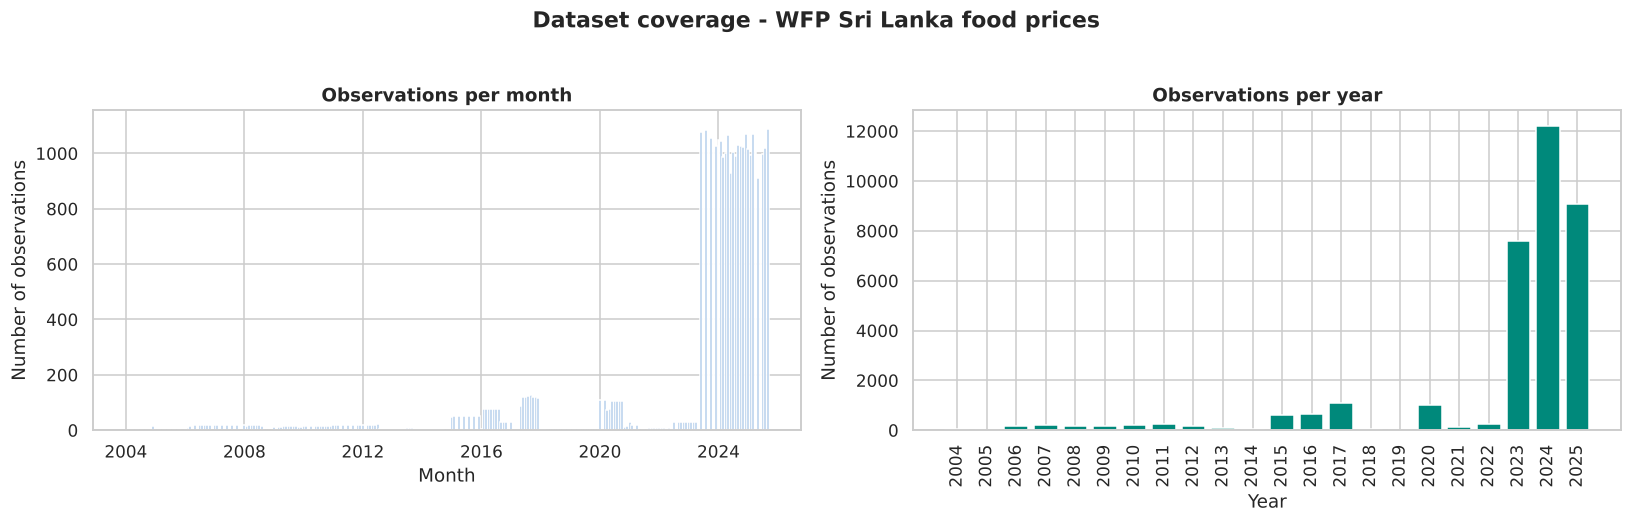

Share of all observations dated June 2023 or later: 84.0%

Observations per year:
year
2004       51
2005       22
2006      178
2007      211
2008      154
2009      166
2010      191
2011      234
2012      166
2013       78
2014       60
2015      618
2016      662
2017     1090
2018       51
2019       24
2020     1024
2021      125
2022      232
2023     7607
2024    12220
2025     9098


In [ ]:
per_month = eda.groupby("month_start").size()
per_year = eda.groupby("year").size()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].bar(per_month.index, per_month.values, width=22, color="#1565C0")
axes[0].set_title("Observations per month", fontweight="bold")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Number of observations")
axes[1].bar(per_year.index.astype(str), per_year.values, color="#00897B")
axes[1].set_title("Observations per year", fontweight="bold")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of observations")
axes[1].tick_params(axis="x", labelrotation=90)
fig.suptitle("Dataset coverage - WFP Sri Lanka food prices", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

share_2023 = (eda["month_start"] >= "2023-06-01").mean() * 100
print(f"Share of all observations dated June 2023 or later: {share_2023:.1f}%")
print("\nObservations per year:")
print(per_year.to_string())

**Reading this chart.** Coverage is thin and intermittent from 2004 to early 2023 — a handful
of commodities in a handful of markets — and then expands abruptly from **June 2023** to roughly
1,000 observations a month.

This is the fact that shapes the entire modelling strategy:

* The great majority of observations come from a **dense but short** panel of about 28 months.
* A 12-month lag is therefore available for only part of the data, which section 10 handles
  explicitly rather than by silently dropping rows.
* Fitting an independent ARIMA per series is impossible for most series, which is exactly the
  limitation the hybrid model in section 15 has to work around.

### 7.2 How long is each price series?

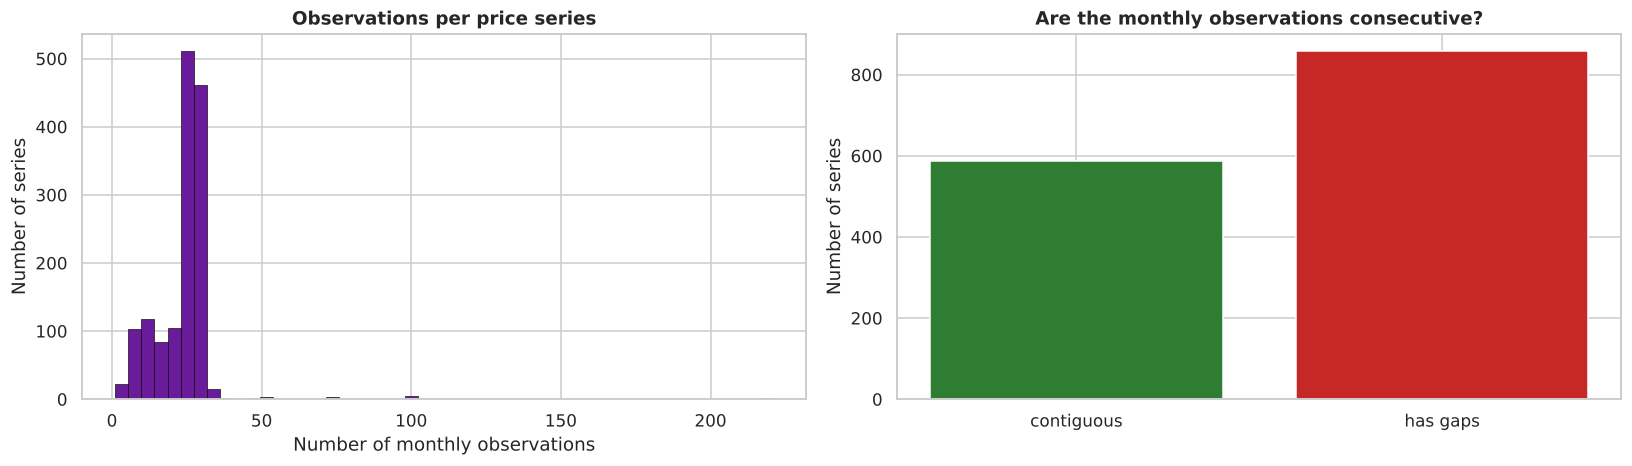

Series: 1,444
  observations per series: min 1, median 26, max 221
  series with >= 12 observations: 1,242
  series with >= 24 observations:   967
  series with >= 36 observations:    25
  series with >= 60 observations:    17
  contiguous monthly series : 586
  series containing gaps    : 858


In [ ]:
sizes = eda.groupby("series_id").size()
spans = eda.groupby("series_id")["month_start"].agg(["min", "max", "count"])
spans["span_months"] = ((spans["max"].dt.year - spans["min"].dt.year) * 12
                        + (spans["max"].dt.month - spans["min"].dt.month) + 1)
spans["contiguous"] = spans["count"] == spans["span_months"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].hist(sizes.values, bins=50, color="#6A1B9A", edgecolor="black", linewidth=.4)
axes[0].set_title("Observations per price series", fontweight="bold")
axes[0].set_xlabel("Number of monthly observations"); axes[0].set_ylabel("Number of series")
axes[1].bar(["contiguous", "has gaps"],
            [int(spans["contiguous"].sum()), int((~spans["contiguous"]).sum())],
            color=["#2E7D32", "#C62828"])
axes[1].set_title("Are the monthly observations consecutive?", fontweight="bold")
axes[1].set_ylabel("Number of series")
plt.tight_layout(); plt.show()

print(f"Series: {len(sizes):,}")
print(f"  observations per series: min {sizes.min()}, median {sizes.median():.0f}, max {sizes.max()}")
for t in (12, 24, 36, 60):
    print(f"  series with >= {t:>2} observations: {(sizes >= t).sum():>5,}")
print(f"  contiguous monthly series : {int(spans['contiguous'].sum()):,}")
print(f"  series containing gaps    : {int((~spans['contiguous']).sum()):,}")

**Why the gap count matters.** Nearly 60% of series have at least one missing month. If lags
were computed with a simple `groupby().shift(1)` over the observation order, a series with a
six-month gap would get a price from six months earlier labelled as "last month's price". Section 10
therefore reindexes every series onto a continuous monthly calendar before taking any lag.

### 7.3 Historical price trends

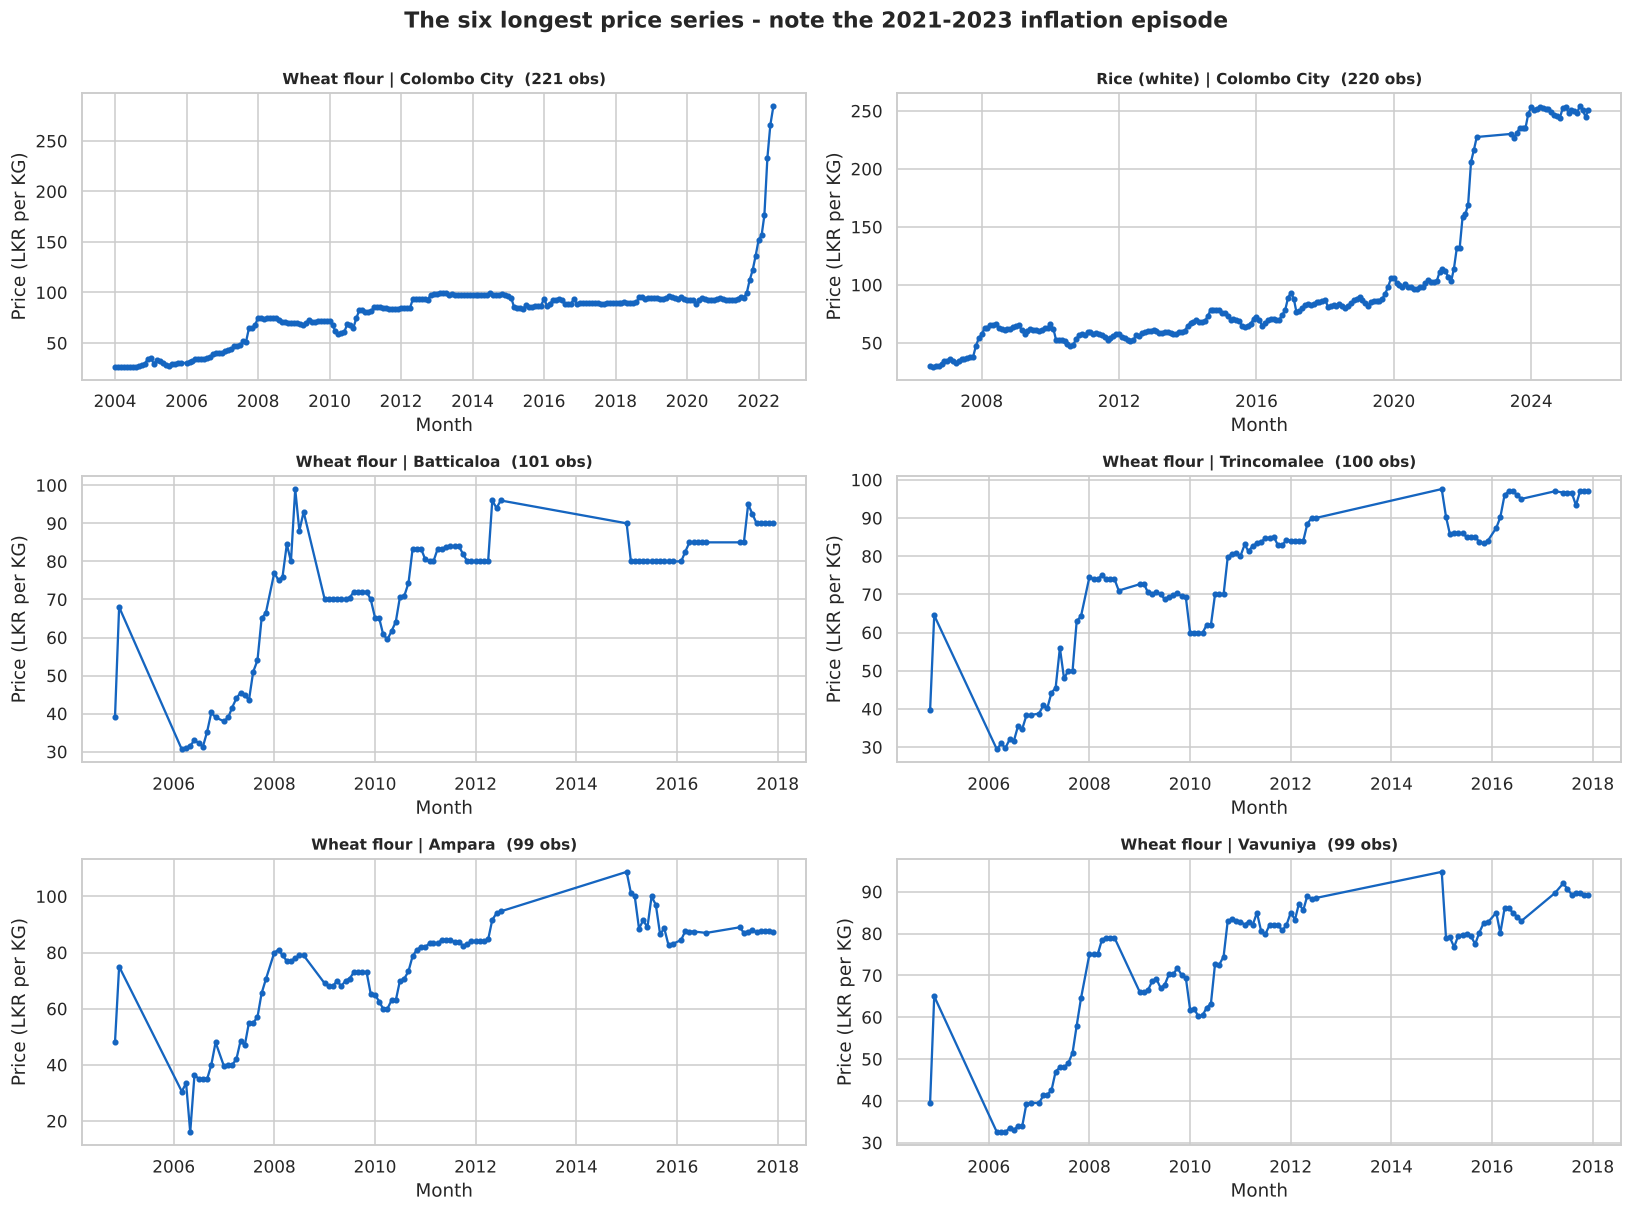

In [ ]:
top_series = sizes.sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(3, 2, figsize=(15, 11))
for ax, sid in zip(axes.ravel(), top_series):
    d = eda[eda["series_id"] == sid].sort_values("month_start")
    unit = d["unit"].iloc[0]
    ax.plot(d["month_start"], d["price"], marker="o", ms=3, lw=1.5, color="#1565C0")
    short = " | ".join(sid.split(" | ")[:2])
    ax.set_title(f"{short}  ({len(d)} obs)", fontsize=10, fontweight="bold")
    ax.set_xlabel("Month"); ax.set_ylabel(f"Price (LKR per {unit})")
fig.suptitle("The six longest price series - note the 2021-2023 inflation episode",
             fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

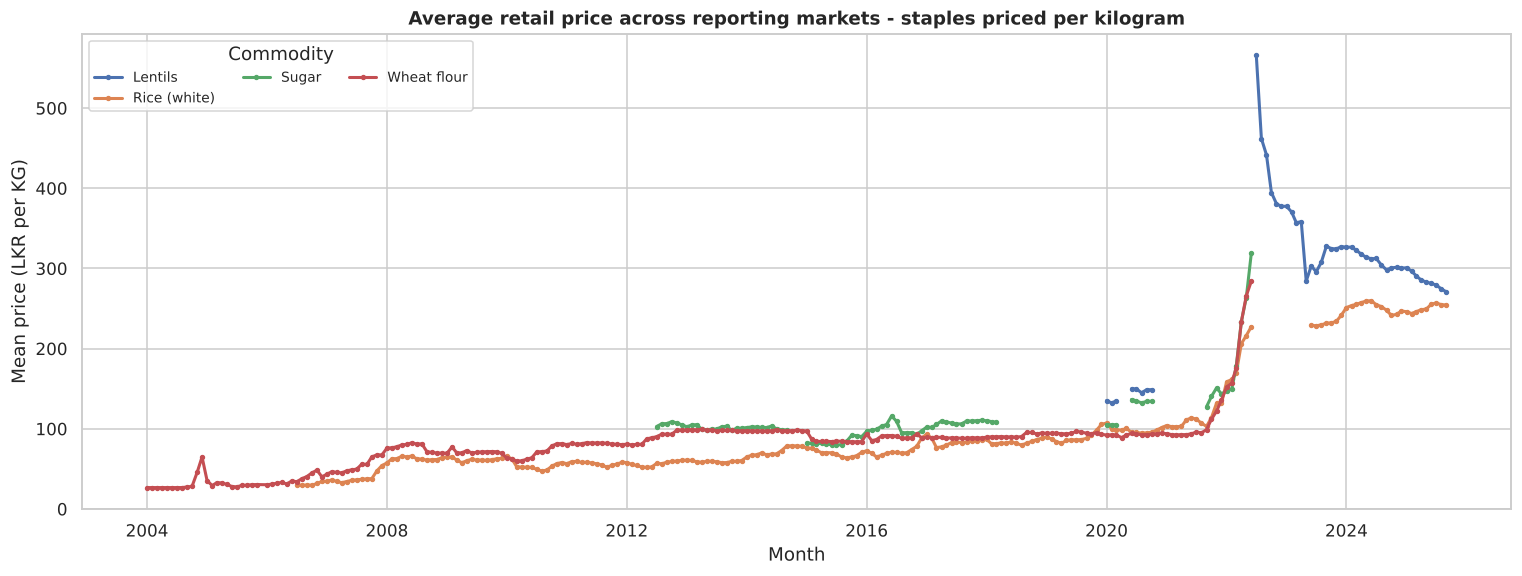

Latest available monthly mean (LKR per KG):
commodity
Sugar          319.600
Wheat flour    284.310
Lentils        270.708
Rice (white)   254.399


In [ ]:
# National average retail price per KG for selected staples
staples = ["Rice (white)", "Wheat flour", "Coconut", "Sugar", "Lentils", "Eggs"]
kg = eda[(eda["unit"] == "KG") & (eda["pricetype"] == "Retail")
         & (eda["commodity"].isin(staples))]
nat = kg.groupby(["month_start", "commodity"])["price"].mean().unstack()

fig, ax = plt.subplots(figsize=(14, 5.4))
for col in nat.columns:
    ax.plot(nat.index, nat[col], lw=2, marker="o", ms=2.5, label=col)
ax.set_title("Average retail price across reporting markets - staples priced per kilogram",
             fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Mean price (LKR per KG)")
ax.legend(title="Commodity", ncol=3, fontsize=9)
plt.tight_layout(); plt.show()

print("Latest available monthly mean (LKR per KG):")
print(nat.ffill().iloc[-1].sort_values(ascending=False).to_string())

### 7.4 Price distributions, by unit

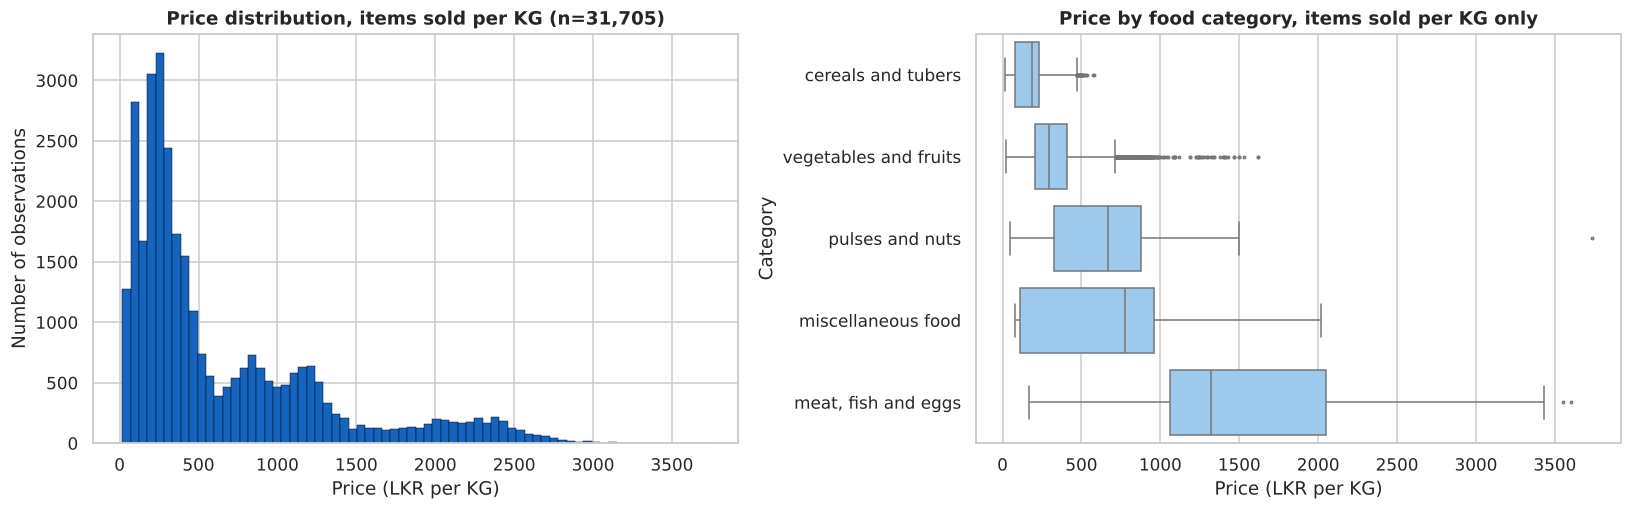

Price summary by unit (LKR) - these are NOT comparable with one another:
            count    mean     50%     min       max
unit                                               
750 ML     20.000 512.721 521.670 429.420   602.580
KG     31,705.000 653.238 376.000  16.000 3,735.420
L         543.000 107.740 117.000  95.000   162.000
Unit    1,994.000  73.309  57.975  11.500   215.000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
kg_all = eda[eda["unit"] == "KG"]["price"].dropna()
axes[0].hist(kg_all, bins=70, color="#1565C0", edgecolor="black", linewidth=.3)
axes[0].set_title(f"Price distribution, items sold per KG (n={len(kg_all):,})", fontweight="bold")
axes[0].set_xlabel("Price (LKR per KG)"); axes[0].set_ylabel("Number of observations")

order = (eda.groupby("category")["price"].median().sort_values().index)
sns.boxplot(data=eda[eda["unit"] == "KG"], x="price", y="category", order=[c for c in order if c in set(eda[eda["unit"]=="KG"]["category"])],
            ax=axes[1], color="#90CAF9", fliersize=1.5)
axes[1].set_title("Price by food category, items sold per KG only", fontweight="bold")
axes[1].set_xlabel("Price (LKR per KG)"); axes[1].set_ylabel("Category")
plt.tight_layout(); plt.show()

print("Price summary by unit (LKR) - these are NOT comparable with one another:")
print(eda.groupby("unit")["price"].describe()[["count", "mean", "50%", "min", "max"]].to_string())

The right-hand panel is restricted to items priced **per kilogram**. Mixing in the `Unit`,
`L` and `750 ML` rows would place a price per coconut beside a price per kilogram of fish and invite
a false comparison.

### 7.5 Monthly and yearly price changes

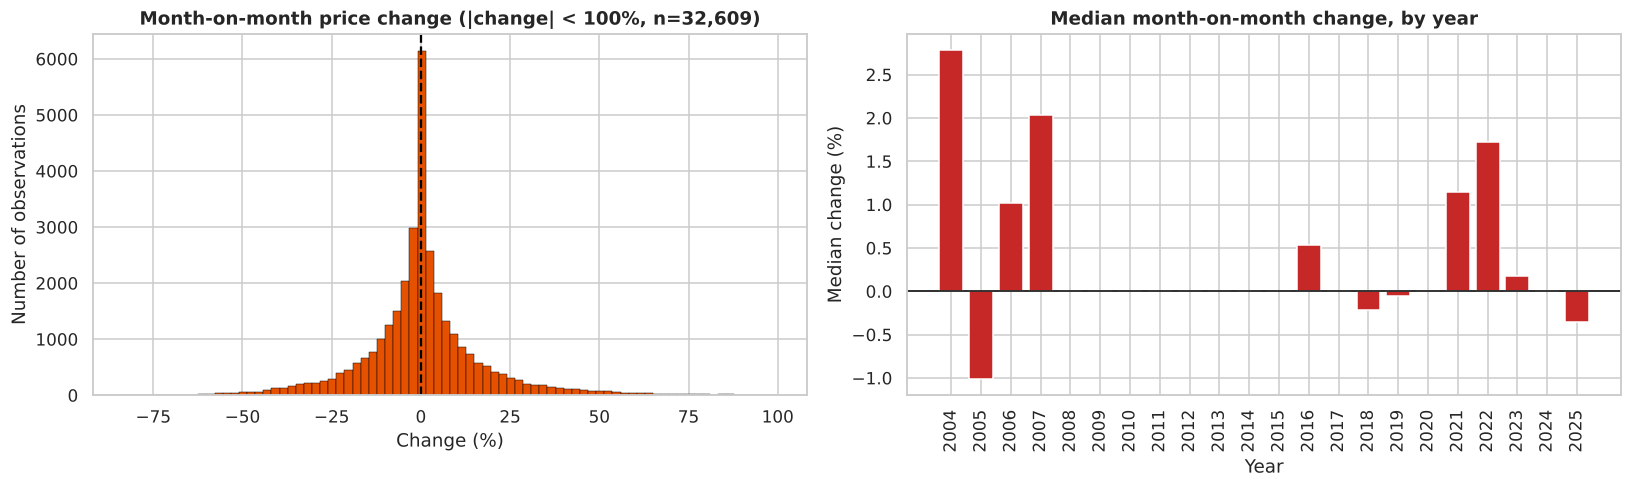

Median month-on-month change: 0.00%
Share of months with a price increase: 46.3%

Median year-on-year change by year (%):
year
2005     4.010
2006     4.310
2007    39.710
2008    69.880
2009     5.450
2010    -8.550
2011     5.730
2012     0.000
2013     0.270
2014    11.110
2015    -5.490
2016     6.150
2017    10.680
2018     4.190
2019     4.820
2020    -0.030
2021     2.280
2022   100.180
2023    55.670
2024    -2.630
2025    -4.170


In [ ]:
s = eda.sort_values(["series_id", "month_start"])
s["mom_pct"] = s.groupby("series_id")["price"].pct_change() * 100
s["yoy_pct"] = s.groupby("series_id")["price"].pct_change(12) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
mom = s["mom_pct"].replace([np.inf, -np.inf], np.nan).dropna()
mom = mom[mom.abs() < 100]
axes[0].hist(mom, bins=80, color="#E65100", edgecolor="black", linewidth=.3)
axes[0].axvline(0, color="black", ls="--")
axes[0].set_title(f"Month-on-month price change (|change| < 100%, n={len(mom):,})",
                  fontweight="bold")
axes[0].set_xlabel("Change (%)"); axes[0].set_ylabel("Number of observations")

yearly = s.groupby("year")["mom_pct"].median()
axes[1].bar(yearly.index.astype(str), yearly.values, color="#C62828")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Median month-on-month change, by year", fontweight="bold")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Median change (%)")
axes[1].tick_params(axis="x", labelrotation=90)
plt.tight_layout(); plt.show()

print(f"Median month-on-month change: {mom.median():.2f}%")
print(f"Share of months with a price increase: {(mom > 0).mean()*100:.1f}%")
print("\nMedian year-on-year change by year (%):")
print(s.groupby("year")["yoy_pct"].median().dropna().round(2).to_string())

Prices rise slightly more often than they fall, and the month-on-month distribution is
**right-skewed** — increases are larger than decreases. The year-by-year panel locates the inflation
episode precisely. A model whose features include recent momentum can exploit this asymmetry; one
that assumes mean reversion to a long-run average cannot.

### 7.6 Price volatility by commodity

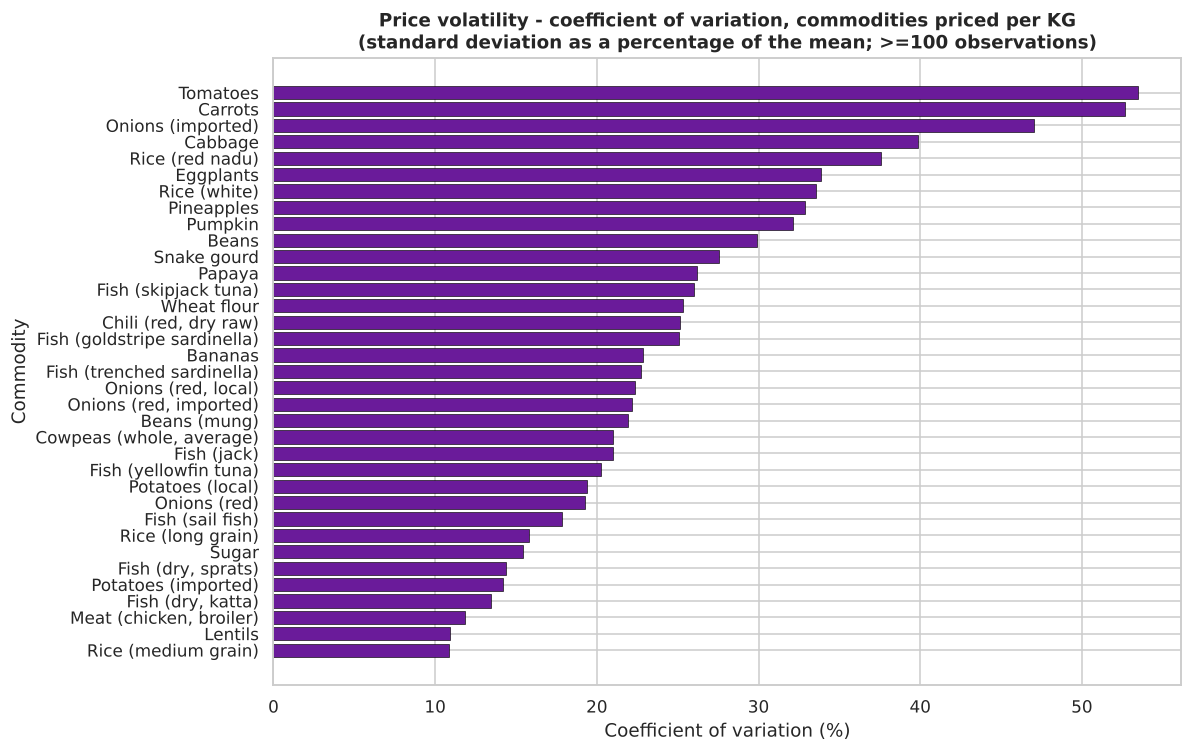

Most volatile (top 5):
commodity
Tomatoes            53.500
Carrots             52.600
Onions (imported)   47.000
Cabbage             39.900
Rice (red nadu)     37.600

Least volatile (bottom 5):
commodity
Potatoes (imported)       14.200
Fish (dry, katta)         13.500
Meat (chicken, broiler)   11.800
Lentils                   10.900
Rice (medium grain)       10.800


In [ ]:
vol = (eda[eda["unit"] == "KG"]
       .groupby("commodity")
       .agg(mean_price=("price", "mean"), sd=("price", "std"), n=("price", "size")))
vol = vol[vol["n"] >= 100]
vol["cv_pct"] = vol["sd"] / vol["mean_price"] * 100
vol = vol.sort_values("cv_pct", ascending=False)

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(vol.index[::-1], vol["cv_pct"][::-1], color="#6A1B9A", edgecolor="black", linewidth=.4)
ax.set_title("Price volatility - coefficient of variation, commodities priced per KG\n"
             "(standard deviation as a percentage of the mean; >=100 observations)",
             fontweight="bold")
ax.set_xlabel("Coefficient of variation (%)"); ax.set_ylabel("Commodity")
plt.tight_layout(); plt.show()

print("Most volatile (top 5):"); print(vol["cv_pct"].head().round(1).to_string())
print("\nLeast volatile (bottom 5):"); print(vol["cv_pct"].tail().round(1).to_string())

The coefficient of variation is used instead of the raw standard deviation so that cheap and
expensive commodities can be compared. Vegetables dominate the volatile end — they are seasonal and
perishable — while processed staples are steadier. This predicts where the models will struggle, and
section 21 checks that prediction against the measured per-commodity errors.

### 7.7 Differences between markets

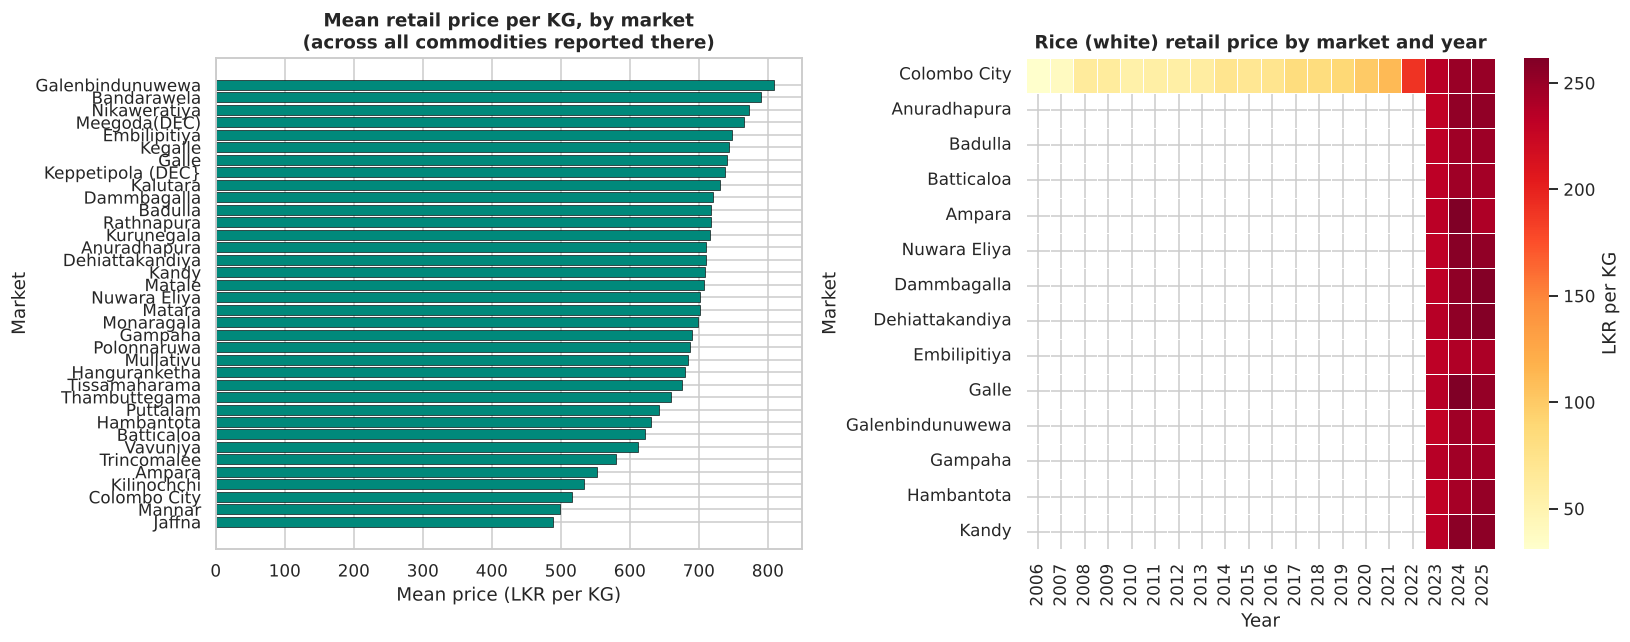

Mean retail price per KG differs across markets by a factor of 1.65


In [ ]:
mk = (eda[(eda["unit"] == "KG") & (eda["pricetype"] == "Retail")]
      .groupby("market")
      .agg(mean_price=("price", "mean"), n=("price", "size"),
           commodities=("commodity", "nunique")))
mk = mk[mk["n"] >= 200].sort_values("mean_price", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(mk.index[::-1], mk["mean_price"][::-1], color="#00897B",
             edgecolor="black", linewidth=.4)
axes[0].set_title("Mean retail price per KG, by market\n(across all commodities reported there)",
                  fontweight="bold")
axes[0].set_xlabel("Mean price (LKR per KG)"); axes[0].set_ylabel("Market")

rice = eda[(eda["commodity"] == "Rice (white)") & (eda["pricetype"] == "Retail")]
piv = rice.pivot_table(index="market", columns="year", values="price", aggfunc="mean")
piv = piv.loc[piv.notna().sum(axis=1).sort_values(ascending=False).head(14).index]
sns.heatmap(piv, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "LKR per KG"},
            linewidths=.4, linecolor="white")
axes[1].set_title("Rice (white) retail price by market and year", fontweight="bold")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Market")
plt.tight_layout(); plt.show()

print("Mean retail price per KG differs across markets by a factor of "
      f"{mk['mean_price'].max() / mk['mean_price'].min():.2f}")

Market-level differences are large, but they partly reflect **which commodities each market
reports** rather than pure geography — a market that reports mostly fish will show a higher mean than
one reporting mostly vegetables. The heatmap controls for that by fixing the commodity, and still
shows real cross-market spread. This is why `market` is a model feature: the same commodity does not
cost the same everywhere.

### 7.8 Missing data patterns

Missing values by column:
admin1       194
admin2       194
latitude     194
longitude    194

Rows with no province: 194
Markets involved: ['National Average']
Commodities involved: ['Fuel (diesel)', 'Fuel (petrol-gasoline)', 'Rice (long grain)', 'Rice (red nadu)', 'Sugar', 'Wheat flour'] ...


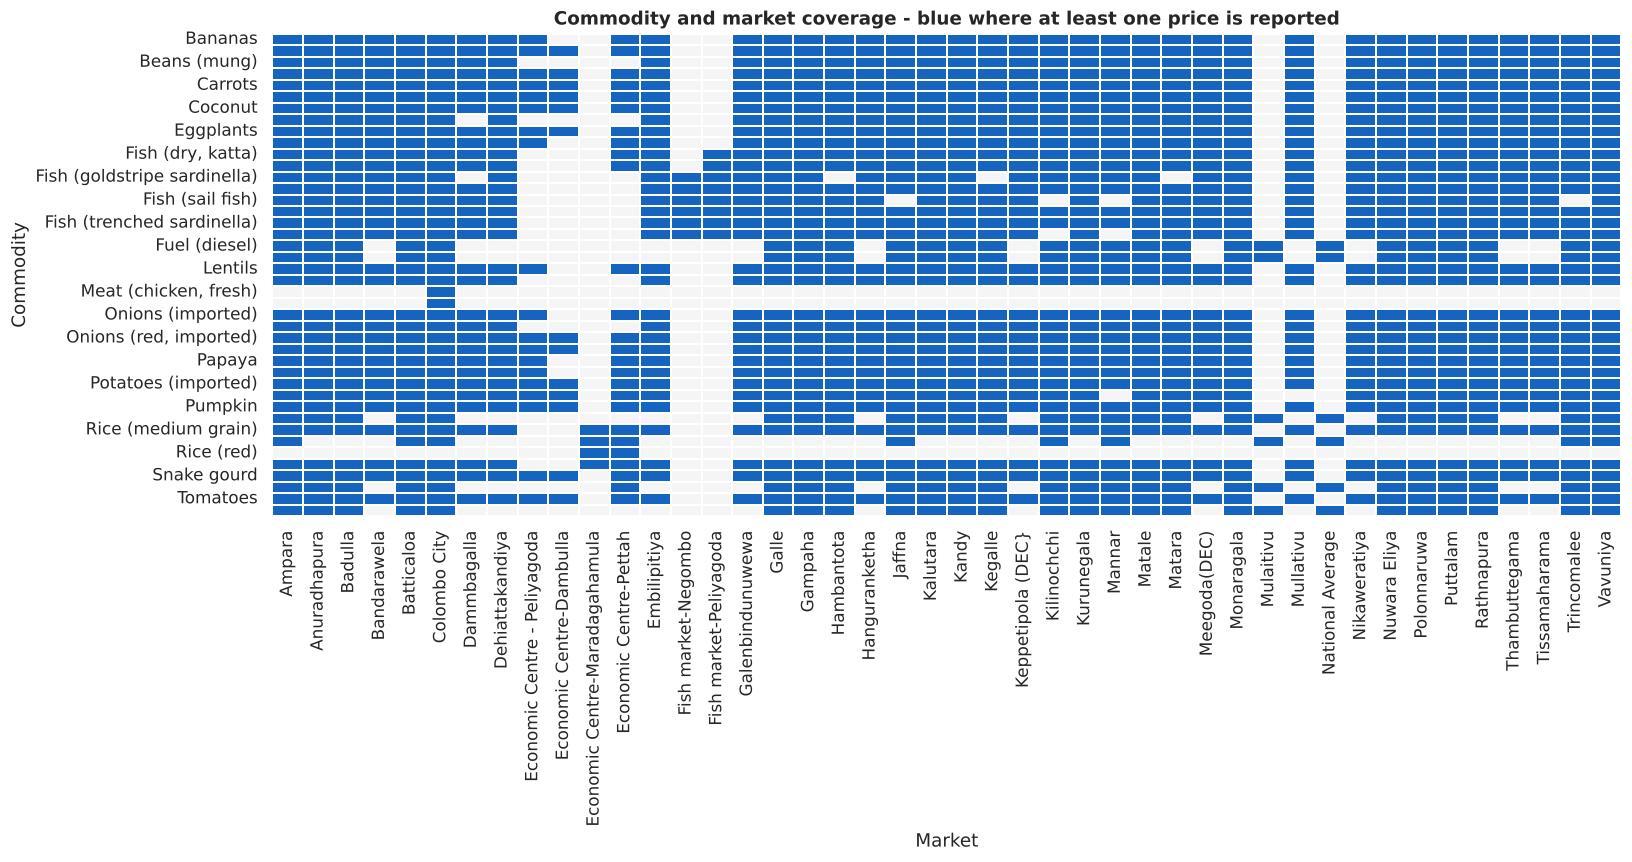


Commodity x market grid is 75.4% populated (42 commodities x 44 markets)


In [ ]:
miss = eda.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print("Missing values by column:"); print(miss.to_string() if len(miss) else "none")

if len(miss):
    affected = eda[eda["admin1"].isna()]
    print(f"\nRows with no province: {len(affected):,}")
    print("Markets involved:", affected["market"].unique().tolist())
    print("Commodities involved:", sorted(affected['commodity'].unique())[:8], "...")

# Coverage matrix: which commodity-market pairs are reported at all?
cov = eda.pivot_table(index="commodity", columns="market", values="price", aggfunc="size")
fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(cov.notna(), cmap=["#F5F5F5", "#1565C0"], cbar=False, ax=ax,
            linewidths=.3, linecolor="white")
ax.set_title("Commodity and market coverage - blue where at least one price is reported",
             fontweight="bold")
ax.set_xlabel("Market"); ax.set_ylabel("Commodity")
plt.tight_layout(); plt.show()

density = cov.notna().sum().sum() / (cov.shape[0] * cov.shape[1]) * 100
print(f"\nCommodity x market grid is {density:.1f}% populated "
      f"({cov.shape[0]} commodities x {cov.shape[1]} markets)")

The missing `admin1`, `admin2`, `latitude` and `longitude` values all belong to the
`National Average` market — an aggregate with no single district. They are a *structural* absence,
not a data-quality fault, so those rows are labelled `National` and kept.

The coverage matrix shows the commodity × market grid is far from full: markets specialise. A model
must therefore learn from the commodity–market combinations that exist rather than assume a complete
panel.

## 8. Data Cleaning

`preprocessing.clean_food_prices()` applies the decisions motivated by sections 6 and 7 and returns
a report of everything it did. The decisions, and the reasoning:

| Decision | Reasoning |
|---|---|
| Parse `date`; derive `month_start` | Every observation is on day 15, so the data is a monthly panel |
| Drop rows with a missing or unparseable date | A row with no time position cannot be used for forecasting |
| Drop rows with a missing or non-positive price | The price is the target; a zero or negative price is not a valid observation |
| Label missing `admin1`/`admin2` rather than drop | They belong to the `National Average` market, which has no district (section 7.8) |
| Keep `latitude`/`longitude` as missing | Not used as features; imputing coordinates would invent geography |
| Collapse repeated (series, month) pairs to their mean | A repeated monthly value for the same commodity–market–unit can only be an aggregation artefact |
| **Flag** outliers, never remove them | The 2022–2023 price spikes are real economic events (section 7.3). Deleting them would delete the signal the project exists to model |
| Keep both Retail and Wholesale | `pricetype` becomes part of the series key, so the two are never mixed within a series |
| Keep all four units | `unit` becomes part of the series key and a feature, so prices in different units are never pooled |

Outliers are detected with a **robust z-score**: the deviation from the series' own median, scaled by
its median absolute deviation (MAD). The MAD is used instead of the standard deviation because the
standard deviation is itself inflated by the outliers it is meant to detect.

In [ ]:
df_clean, clean_report = preprocessing.clean_food_prices(df_raw)
preprocessing.print_cleaning_report(clean_report)

00:14:04 | INFO    | Cleaning complete: 34262 -> 34262 rows, 1444 series, 2004-01-01 to 2025-09-01


PREPROCESSING REPORT
Rows in                        : 34,262
Dropped - unparseable date     : 0
Dropped - missing price        : 0
Dropped - price <= 0           : 0
Duplicate full rows removed    : 0
Rows in duplicate series-month : 0
Rows out                       : 34,262

Monthly panel?                 : True (days of month present: [15])
Date coverage                  : 2004-01-01 -> 2025-09-01
Currencies                     : ['LKR']
Price flags                    : ['actual']
Price types                    : ['Retail', 'Wholesale']
Units                          : ['750 ML', 'KG', 'L', 'Unit']
Commodities / markets          : 42 / 44

admin1 missing filled          : 194 -> 'National' (markets: ['National Average'])

Series (commodity|market|unit|pricetype): 1,444
  observations per series      : min=1, median=26.0, max=221
  series with >=12 / >=24 / >=36 obs : 1,242 / 967 / 25
  contiguous monthly series    : 586
  series containing gaps       : 858

Outlier rule              

In [ ]:
print("Largest upward price excursions flagged as extreme:\n")
for row in clean_report.get("largest_positive_outliers", [])[:8]:
    print(f"  {row['month']}  robust z = {row['robust_z']:>6.1f}  "
          f"LKR {row['price']:>9,.2f}   {row['series']}")
print(f"\nFlagged: {clean_report['n_outliers_flagged']:,} rows "
      f"({clean_report['n_outliers_flagged']/len(df_clean)*100:.2f}% of the data)")
print(f"Removed: {clean_report['outliers_removed']}")
print(f"\nPolicy: {clean_report['outlier_policy']}")

Largest upward price excursions flagged as extreme:

  2014-09-01  robust z =   56.8  LKR     82.15   Rice (long grain) | National Average | KG | Retail
  2015-01-01  robust z =   52.4  LKR     99.44   Wheat flour | Monaragala | KG | Retail
  2014-06-01  robust z =   51.6  LKR     80.15   Rice (long grain) | National Average | KG | Retail
  2016-04-01  robust z =   46.4  LKR     98.00   Wheat flour | Monaragala | KG | Retail
  2016-06-01  robust z =   46.4  LKR     98.00   Wheat flour | Monaragala | KG | Retail
  2014-08-01  robust z =   44.5  LKR     77.39   Rice (long grain) | National Average | KG | Retail
  2014-05-01  robust z =   43.9  LKR     77.15   Rice (long grain) | National Average | KG | Retail
  2016-05-01  robust z =   42.9  LKR     97.17   Wheat flour | Monaragala | KG | Retail

Flagged: 216 rows (0.63% of the data)
Removed: 0

Policy: Flagged only. Extreme food prices in 2022-2023 reflect Sri Lanka's real inflation episode, so removing them would delete genuine signal.

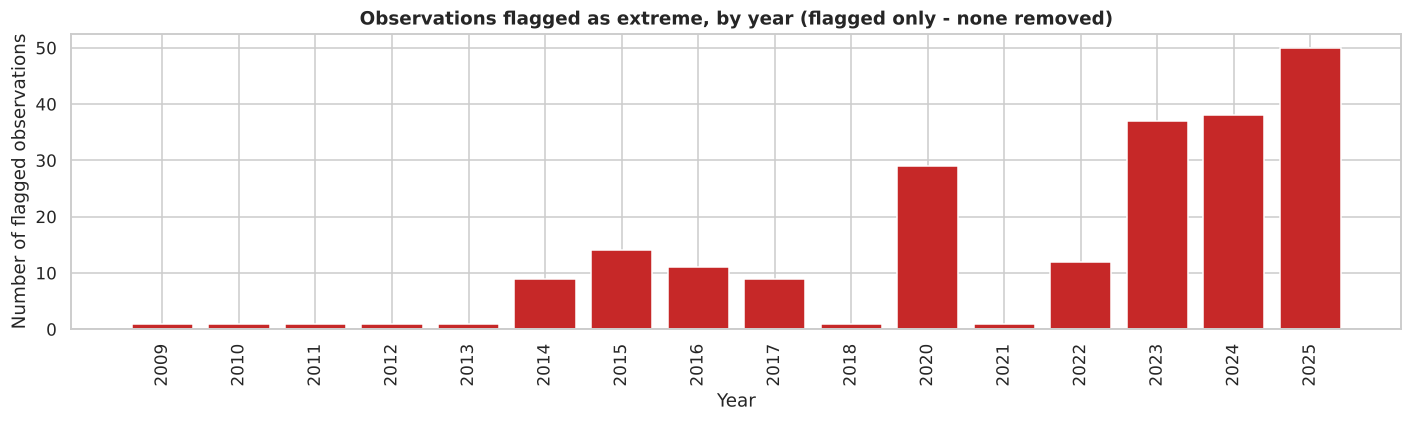

year
2009     1
2010     1
2011     1
2012     1
2013     1
2014     9
2015    14
2016    11
2017     9
2018     1
2020    29
2021     1
2022    12
2023    37
2024    38
2025    50


In [ ]:
# Where do the flagged extremes sit in time? If they cluster in the crisis years,
# they are economic events rather than recording errors.
flagged = df_clean[df_clean["is_outlier"]]
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(flagged.groupby("year").size().index.astype(str),
       flagged.groupby("year").size().values, color="#C62828")
ax.set_title("Observations flagged as extreme, by year (flagged only - none removed)",
             fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Number of flagged observations")
ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout(); plt.show()
print(flagged.groupby("year").size().to_string())

### 9. Data Preprocessing

Sections 8 and 9 of the brief are handled by the same function, so the preprocessing summary is
recorded here explicitly.

**Missing values.** Prices and dates: no row in this file was lost to either. Geography: 194 rows
labelled rather than dropped. Coordinates: left missing, unused.

**Duplicates.** Checked twice — as whole rows, and as repeated (series, month) pairs. The supplied
file contains neither.

**Date conversion.** `date` → `datetime64`, then `month_start` as the monthly period start, plus
`year`, `month` and `quarter`.

**Categorical encoding.** Deferred to section 11, deliberately: the encoder must be **fitted on the
training split only**, so it is fitted after the chronological split, not before. Fitting it on the
whole dataset would leak information about which categories exist in the future.

**Numerical scaling.** Also deferred, and applied *selectively*. Tree ensembles are invariant to
monotone rescaling of features, so scaling them would add nothing. The two scale-sensitive models —
the `LinearRegression` stacking base learner and the `Ridge` meta-learner — are each wrapped in a
`Pipeline` with `StandardScaler`, so scaling happens inside cross-validation and cannot leak.

**Consistency checks.** One currency (LKR); one price flag (`actual`); four units kept separate; two
price types kept separate.

In [ ]:
# Persist the cleaned panel for the dashboard and for reuse
utils.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df_clean.to_parquet(utils.CLEAN_PARQUET, index=False)
df_clean.to_csv(utils.CLEAN_CSV, index=False)
print("Cleaned panel saved:")
print("  ", utils.CLEAN_PARQUET)
print("  ", utils.CLEAN_CSV)
print(f"\nShape: {df_clean.shape}")
df_clean.head()

Cleaned panel saved:
   /home/claude/sri-lanka-food-price-ensemble/data/processed/food_prices_clean.parquet
   /home/claude/sri-lanka-food-price-ensemble/data/processed/food_prices_clean.csv

Shape: (34262, 23)


,month_start,date,year,month,quarter,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,series_id,robust_z,is_outlier
0,2004-01-01,2004-01-15,2004,1,1,Western,Colombo,Colombo City,368,6.930,79.850,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.710,0.330,Rice (red nadu) | Colombo City | KG | Retail,-0.948,False
1,2004-01-01,2004-01-15,2004,1,1,Western,Colombo,Colombo City,368,6.930,79.850,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.660,0.270,Wheat flour | Colombo City | KG | Retail,-4.543,False
2,2004-02-01,2004-02-15,2004,2,1,Western,Colombo,Colombo City,368,6.930,79.850,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.620,0.340,Rice (red nadu) | Colombo City | KG | Retail,-0.906,False
3,2004-02-01,2004-02-15,2004,2,1,Western,Colombo,Colombo City,368,6.930,79.850,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.710,0.270,Wheat flour | Colombo City | KG | Retail,-4.540,False
4,2004-03-01,2004-03-15,2004,3,1,Western,Colombo,Colombo City,368,6.930,79.850,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.920,0.340,Rice (red nadu) | Colombo City | KG | Retail,-0.938,False


## 10. Feature Engineering

The target is the price in month *t*. Every feature must be computable from information available
**strictly before** month *t*. Two engineering decisions carry most of the weight.

### 10.1 Calendar alignment

Section 7.2 showed that roughly 60% of series have at least one missing month. A naive
`groupby("series_id")["price"].shift(1)` would take the previous *row*, not the previous *month*, so a
series with a six-month gap would receive a six-month-old price labelled `lag_1`. The model would
learn from a feature that does not mean what its name says.

`build_features` therefore pivots the panel into a series × month matrix, **reindexes it onto a
continuous monthly calendar**, and takes every lag and rolling window on that matrix. `lag_12` is
either the price exactly twelve calendar months earlier or missing — never a substitute.

### 10.2 Preventing target leakage

* All rolling and expanding statistics are computed on the **shifted** price matrix, so a window for
  month *t* covers only months up to *t−1*. The target can never enter its own feature.
* `roll_mean_3` requires all three preceding months to be observed (`min_periods=3`); a partial
  window is not quietly averaged.
* Nothing is computed across the train/test boundary, and no statistic is fitted on data later than
  the row it describes.

### 10.3 The feature set, and why each group earns its place

| Group | Features | Why it should help |
|---|---|---|
| Calendar | `year`, `month`, `quarter`, `time_index`, `month_sin`, `month_cos` | `time_index` lets trees pick up the long-run inflation trend. The sine/cosine pair encodes month-of-year cyclically, so December sits next to January instead of 11 units away. |
| History depth | `obs_index`, `months_since_prev_obs` | How much history the series has here, and whether the previous observation really is last month. These let a tree discount lag features for thin or gappy series rather than trusting them blindly. |
| Lags | `lag_1`, `lag_2`, `lag_3`, `lag_6`, `lag_12` | The autoregressive core. Monthly food prices are highly persistent, so last month's price is the strongest single predictor; `lag_12` carries the same-month-last-year seasonal signal that matters for vegetables. |
| Rolling | `roll_mean_3/6/12`, `roll_std_3/6/12` | The means give a local level that is less noisy than any single lag. The standard deviations give local **volatility** — what separates a stable staple from a swinging vegetable, and a strong cue for how wide the model's own error is likely to be. |
| Momentum | `diff_1`, `pct_change_1`, `pct_change_3` | Direction and size of recent movement, absolute and relative. Section 7.5 showed the change distribution is skewed, so momentum is informative. |
| Expanding | `exp_mean`, `exp_std` | The series' entire observed history to date — a long-memory anchor, and the fallback below. |
| Availability | `has_lag_6`, `has_lag_12`, `has_roll_6`, `has_roll_12` | Whether each long-memory feature was genuinely observed or filled. |
| Categorical | `commodity`, `market`, `unit`, `pricetype`, `category`, `admin1` (ordinal-encoded) | Identity. The same features mean different things for rice in Colombo and for fish in Jaffna. `unit` is included so that prices in different units are never treated as equivalent. |

### 10.4 The long-memory fallback — a measured trade-off

Requiring a genuine 12-month history for every row costs a great deal of data, because most series
begin in 2023:

* require everything up to `lag_12` and `roll_12` → **17,629** usable rows
* require only the 3-month core → **29,941** usable rows

Dropping two-thirds of the dense 2023–2025 panel to satisfy one feature is a bad trade. Instead,
when a long-memory feature is unavailable it is filled with that series' **own expanding mean or
standard deviation** — a statistic computed only from months strictly before the row — and a
`has_*` flag records that it was filled. This keeps `lag_12` in the feature set as the brief
requires, introduces no leakage (the fill uses only the series' own past), and lets the models learn
how much to trust a filled value. The row is only dropped if the 3-month core is missing, which
means the series genuinely has fewer than three prior consecutive months.

In [ ]:
df_feat, feat_report = fe.build_features(df_clean)

print(f"Featured frame: {df_feat.shape[0]:,} rows x {df_feat.shape[1]} columns")
print(f"Model features defined: {len(utils.FEATURE_COLUMNS)}\n")

print("Long-memory feature availability (genuinely observed):")
for flag in utils.AVAILABILITY_FLAGS:
    n = feat_report[flag]
    print(f"  {flag:<14}: {n:>7,} rows ({n/len(df_feat)*100:>5.1f}%)")

print("\nRows where a long-memory feature was filled from the series' own expanding statistic:")
for k, v in feat_report.items():
    if "_filled_from_" in k:
        print(f"  {k:<42}: {v:>7,}")

00:14:06 | INFO    | Feature engineering produced 34262 rows x 51 columns.


Featured frame: 34,262 rows x 51 columns
Model features defined: 34

Long-memory feature availability (genuinely observed):
  has_lag_6     :  23,669 rows ( 69.1%)
  has_lag_12    :  17,060 rows ( 49.8%)
  has_roll_6    :  20,035 rows ( 58.5%)
  has_roll_12   :  11,287 rows ( 32.9%)

Rows where a long-memory feature was filled from the series' own expanding statistic:
  lag_6_filled_from_exp_mean                :  10,593
  lag_12_filled_from_exp_mean               :  17,202
  roll_mean_6_filled_from_exp_mean          :  14,227
  roll_mean_12_filled_from_exp_mean         :  22,975
  roll_std_6_filled_from_exp_std            :  14,227
  roll_std_12_filled_from_exp_std           :  22,975


In [ ]:
# Leakage check: lag_1 must equal the SAME series' price exactly one calendar month earlier
chk = df_feat[[utils.SERIES_ID, "month_index", "price", "lag_1", "lag_12", "roll_mean_3"]].copy()
lookup = dict(zip(zip(chk[utils.SERIES_ID], chk["month_index"]), chk["price"]))
sample = chk.dropna(subset=["lag_1"]).sample(5000, random_state=0)
expected = [lookup.get((sid, mi - 1)) for sid, mi in
            zip(sample[utils.SERIES_ID], sample["month_index"])]
mismatch = sum(
    1 for e, a in zip(expected, sample["lag_1"])
    if e is None or not np.isclose(e, a, rtol=1e-9)
)
print(f"lag_1 verification on {len(sample):,} sampled rows -> mismatches: {mismatch}")

identical = np.isclose(df_feat["roll_mean_3"].astype(float),
                       df_feat["price"].astype(float), rtol=1e-12).sum()
print(f"Rows where roll_mean_3 equals the target exactly: {identical} "
      f"({identical/len(df_feat)*100:.3f}% - coincidence, not leakage)")
print("\nIf both numbers are ~0, the features contain no target leakage.")

lag_1 verification on 5,000 sampled rows -> mismatches: 0
Rows where roll_mean_3 equals the target exactly: 475 (1.386% - coincidence, not leakage)

If both numbers are ~0, the features contain no target leakage.


In [ ]:
# Example: the engineered features for one well-covered series
example_sid = (df_feat.groupby(utils.SERIES_ID).size().sort_values(ascending=False).index[1])
show = ["month_start", "price", "lag_1", "lag_2", "lag_3", "lag_12",
        "roll_mean_3", "roll_std_3", "pct_change_1", "has_lag_12", "obs_index"]
print("Series:", example_sid, "\n")
df_feat[df_feat[utils.SERIES_ID] == example_sid].sort_values("month_start")[show].tail(12)

Series: Rice (white) | Colombo City | KG | Retail 



,month_start,price,lag_1,lag_2,lag_3,lag_12,roll_mean_3,roll_std_3,pct_change_1,has_lag_12,obs_index
29573,2024-10-01,245.360,246.650,248.690,251.510,235.200,248.950,2.440,-0.820,1,208
29574,2024-11-01,244.290,245.360,246.650,248.690,235.270,246.900,1.679,-0.523,1,209
29575,2024-12-01,252.150,244.290,245.360,246.650,247.580,245.433,1.182,-0.436,1,210
29576,2025-01-01,253.690,252.150,244.290,245.360,253.230,247.267,4.263,3.217,1,211
29577,2025-02-01,248.460,253.690,252.150,244.290,251.060,250.043,5.042,0.611,1,212
29578,2025-03-01,250.720,248.460,253.690,252.150,251.880,251.433,2.688,-2.062,1,213
29579,2025-04-01,250.320,250.720,248.460,253.690,253.080,250.957,2.623,0.910,1,214
29580,2025-05-01,248.270,250.320,250.720,248.460,252.210,249.833,1.206,-0.160,1,215
29581,2025-06-01,254.020,248.270,250.320,250.720,251.440,249.770,1.314,-0.819,1,216
29582,2025-07-01,250.620,254.020,248.270,250.320,251.510,250.870,2.914,2.316,1,217


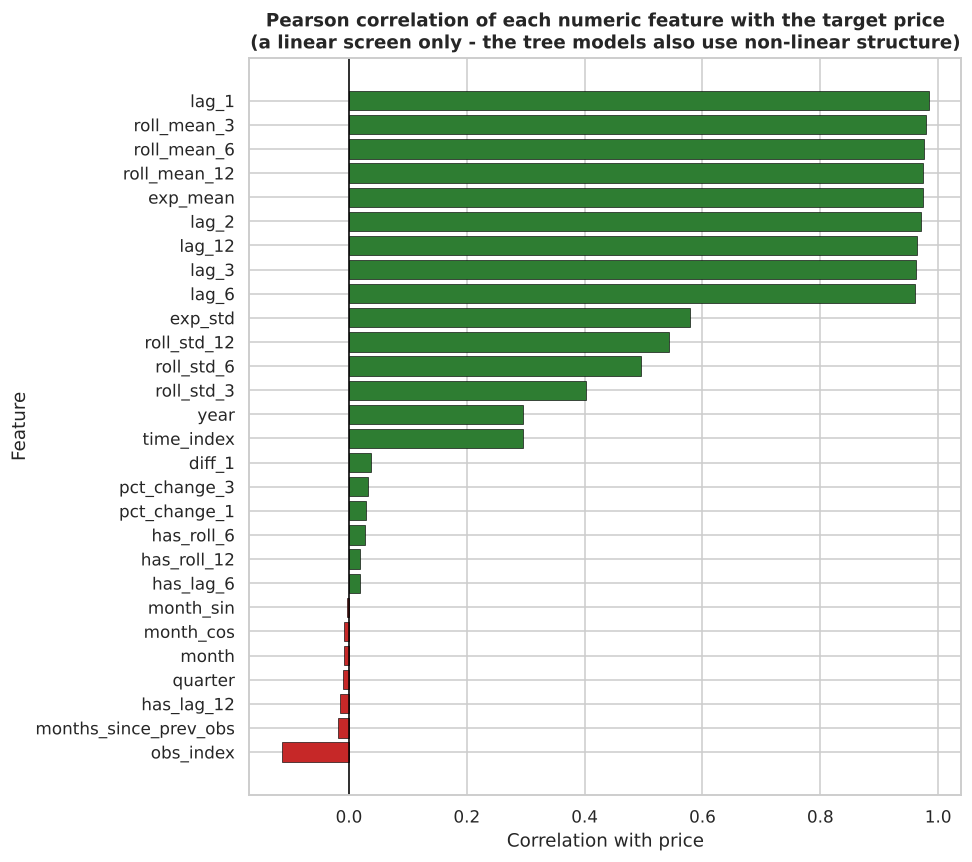

Most correlated with the target:
lag_1          0.985
roll_mean_3    0.979
roll_mean_6    0.976
roll_mean_12   0.975
exp_mean       0.975
lag_2          0.971
lag_12         0.965
lag_3          0.962


In [ ]:
# How strongly is each feature related to the target? (linear screen only)
num_feats = [c for c in utils.FEATURE_COLUMNS if not c.endswith("_enc")]
corr = (df_feat[num_feats + ["price"]].astype(float).corr()["price"]
        .drop("price").sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#2E7D32" if v > 0 else "#C62828" for v in corr.values]
ax.barh(corr.index[::-1], corr.values[::-1], color=colors[::-1],
        edgecolor="black", linewidth=.4)
ax.axvline(0, color="black", lw=1)
ax.set_title("Pearson correlation of each numeric feature with the target price\n"
             "(a linear screen only - the tree models also use non-linear structure)",
             fontweight="bold")
ax.set_xlabel("Correlation with price"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

print("Most correlated with the target:"); print(corr.head(8).round(3).to_string())

The lag and rolling-mean features correlate above 0.9 with the target, which is exactly what
a persistent monthly price series should look like. That high correlation is also a warning: a model
that simply copied `lag_1` would already score well, so section 18 checks whether the ensembles beat
that kind of trivial persistence rather than just reporting a high R² and stopping.

In [ ]:
df_model, table_report = fe.build_model_table(df_feat)

print(f"Rows before : {table_report['n_rows_before']:,}")
print(f"Rows kept   : {table_report['n_rows_after']:,} ({table_report['pct_rows_kept']}%)")
print(f"Rows dropped: {table_report['n_rows_dropped']:,}")
print(f"Series kept : {table_report['n_series']:,}")
print(f"Coverage    : {table_report['date_min']} -> {table_report['date_max']}")
print(f"\nReason rows are dropped: {table_report['reason']}")

df_feat.to_parquet(utils.FEATURES_PARQUET, index=False)
df_model.to_parquet(utils.MODEL_TABLE_PARQUET, index=False)
print("\nSaved the featured frame and the modelling table to data/processed/")

00:14:06 | INFO    | Model table: 26188 rows (76.4% of featured rows), 1413 series, 2004-04-01 to 2025-09-01


Rows before : 34,262
Rows kept   : 26,188 (76.43%)
Rows dropped: 8,074
Series kept : 1,413
Coverage    : 2004-04-01 -> 2025-09-01

Reason rows are dropped: A row needs at least three consecutive prior monthly observations in its own series before lag_1..lag_3 and the 3-month rolling statistics exist.

Saved the featured frame and the modelling table to data/processed/


## 11. Chronological Data Splitting

The data is a time series, so the split must be **by date and never shuffled**. A random split would
place June 2025 in training and April 2025 in test, letting the model learn from the future to
predict the past — and producing a flattering score that would collapse in real use.

**Split points**

| Split | Period | Purpose |
|---|---|---|
| Train | up to **2024-12-31** | fit the models |
| Validation | **2025-01** to **2025-03** | choose the stacking meta-learner's alpha; sanity-check |
| Test | **2025-04** to **2025-09** | reported once, at the end |

**Why these dates.** They were chosen from the actual coverage, not picked arbitrarily. The dense
panel runs from mid-2023 to September 2025, and these boundaries give roughly a **70 / 10 / 20**
split of the modelling table while leaving a **six-month** test horizon — long enough to show how
error grows with distance from the training data (section 18.2), and long enough that the test
metrics are not an artefact of one unusual month. They also leave the training period long enough
for most series to accumulate the ~12 residuals the hybrid's ARIMA component needs (section 15).

**Time-aware cross-validation.** Within the training period, tuning uses `TimeSeriesSplit`, which
produces expanding windows: fold 1 trains on the earliest rows and validates on the next block, fold
2 trains on everything up to that block and validates on the following one, and so on. Every
validation fold is strictly later than its training fold.

**Leakage-safe validation for stacking** is covered in section 14: the meta-learner is trained only
on out-of-fold predictions from these same time-ordered folds.

**The categorical encoder is fitted here**, on the training split alone. A category appearing only
in test (a market that starts reporting later) is mapped to `-1` rather than silently given a code
derived from future data.

In [ ]:
train_df, val_df, test_df, split_report = fe.chronological_split(df_model)

print(json.dumps({k: v for k, v in split_report.items() if k != "test_months"},
                 indent=2, default=str))
print("\nTest months:", ", ".join(split_report["test_months"]))

# Hard assertions - the split must be strictly ordered
assert train_df["month_start"].max() < val_df["month_start"].min()
assert val_df["month_start"].max() < test_df["month_start"].min()
print("\nVerified: every validation month is after every training month, "
      "and every test month is after every validation month.")

00:14:06 | INFO    | Split -> train 18428 (70%) | val 2754 (10%) | test 5006 (19%)


{
  "train_end": "2024-12-31",
  "val_end": "2025-03-31",
  "n_train": 18428,
  "n_val": 2754,
  "n_test": 5006,
  "pct_train": 70.4,
  "pct_val": 10.5,
  "pct_test": 19.1,
  "train_period": "2004-04-01 .. 2024-12-01",
  "val_period": "2025-01-01 .. 2025-03-01",
  "test_period": "2025-04-01 .. 2025-09-01",
  "train_series": 1403,
  "val_series": 998,
  "test_series": 1043,
  "shuffled": false,
  "note": "Test series not present in training are predicted from their own lag features; the categorical encoder maps any unseen category to -1."
}

Test months: 2025-04-01, 2025-05-01, 2025-06-01, 2025-07-01, 2025-08-01, 2025-09-01

Verified: every validation month is after every training month, and every test month is after every validation month.


In [ ]:
# Encoder fitted on TRAIN ONLY, then applied to all three splits
encoder = fe.fit_categorical_encoder(train_df)
train_df = fe.apply_categorical_encoder(train_df, encoder)
val_df   = fe.apply_categorical_encoder(val_df, encoder)
test_df  = fe.apply_categorical_encoder(test_df, encoder)

X_train, y_train = fe.get_xy(train_df)
X_val,   y_val   = fe.get_xy(val_df)
X_test,  y_test  = fe.get_xy(test_df)

print(f"X_train {X_train.shape}   X_val {X_val.shape}   X_test {X_test.shape}")
print(f"NaNs -> train {int(X_train.isna().sum().sum())}, "
      f"val {int(X_val.isna().sum().sum())}, test {int(X_test.isna().sum().sum())}")

unseen = int((test_df["market_enc"] == -1).sum() + (test_df["commodity_enc"] == -1).sum())
print(f"Test rows with a category unseen in training (encoded -1): {unseen}")

print("\nTarget distribution by split (LKR):")
print(pd.DataFrame({
    "train": y_train.describe(), "val": y_val.describe(), "test": y_test.describe(),
}).round(2).to_string())

X_train (18428, 34)   X_val (2754, 34)   X_test (5006, 34)
NaNs -> train 0, val 0, test 0
Test rows with a category unseen in training (encoded -1): 0

Target distribution by split (LKR):
           train       val      test
count 18,428.000 2,754.000 5,006.000
mean     579.390   655.010   707.320
std      609.750   593.090   690.130
min       11.500    28.000    25.330
25%      149.310   240.220   229.040
50%      312.410   399.080   408.980
75%      875.000   865.420   940.500
max    3,735.420 3,095.000 3,429.170


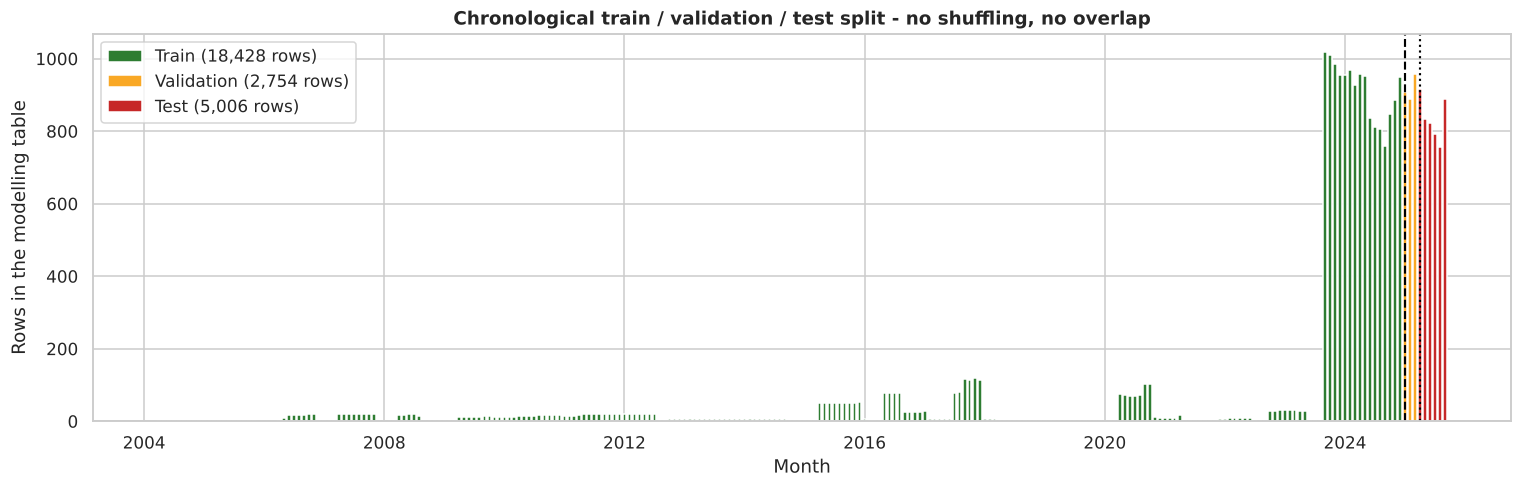

TimeSeriesSplit(3) folds inside the training period:
  fold 1: fit on  4,607 rows (to 2024-12-01) -> validate on 4,607 rows (2013-10-01 to 2024-12-01)
  fold 2: fit on  9,214 rows (to 2024-12-01) -> validate on 4,607 rows (2013-10-01 to 2024-12-01)
  fold 3: fit on 13,821 rows (to 2024-12-01) -> validate on 4,607 rows (2004-04-01 to 2024-12-01)


In [ ]:
# Visualise the split
fig, ax = plt.subplots(figsize=(14, 4.6))
for name, d, c in [("Train", train_df, "#2E7D32"), ("Validation", val_df, "#F9A825"),
                   ("Test", test_df, "#C62828")]:
    g = d.groupby("month_start").size()
    ax.bar(g.index, g.values, width=22, color=c, label=f"{name} ({len(d):,} rows)")
ax.axvline(utils.TRAIN_END, color="black", ls="--", lw=1.4)
ax.axvline(utils.VAL_END, color="black", ls=":", lw=1.4)
ax.set_title("Chronological train / validation / test split - no shuffling, no overlap",
             fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Rows in the modelling table")
ax.legend()
plt.tight_layout(); plt.show()

# Show the expanding-window CV folds used for tuning
from sklearn.model_selection import TimeSeriesSplit
print(f"TimeSeriesSplit({utils.TUNING_CV_SPLITS}) folds inside the training period:")
for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=utils.TUNING_CV_SPLITS)
                             .split(X_train), 1):
    tr_end = train_df.iloc[tr]["month_start"].max().date()
    te_s = train_df.iloc[te]["month_start"].min().date()
    te_e = train_df.iloc[te]["month_start"].max().date()
    print(f"  fold {i}: fit on {len(tr):>6,} rows (to {tr_end}) -> "
          f"validate on {len(te):>5,} rows ({te_s} to {te_e})")

## 12. Bagging — Random Forest Regressor

### How bagging works

**Bagging** is short for **b**ootstrap **agg**regat**ing**, and it attacks one specific problem:
**variance**. A single deep decision tree has low bias — given enough depth it can fit almost any
training set — but very high variance: change a handful of training rows and the tree's splits, and
therefore its predictions, can change substantially. Such a model has effectively memorised noise
along with signal.

Bagging's insight is that averaging many such models cancels much of that noise, provided the models
are not all making the *same* mistake. It achieves that in two ways:

1. **Bootstrap resampling.** Each tree is grown on a sample of the training rows drawn *with
   replacement*, the same size as the original. Each tree therefore sees a slightly different
   dataset, and roughly a third of rows are left out of any given tree.
2. **Random feature subsetting.** At every split, a tree may only consider a random subset of the
   features (`max_features`). This is what makes a *random forest* more than just bagged trees: it
   stops every tree from choosing the same dominant feature (here, `lag_1`) at the root, which would
   make the trees nearly identical and leave nothing for averaging to cancel.

Trees are grown **independently and in parallel** — no tree knows what the others did. The forest's
prediction is the plain average of all of them. Averaging *N* roughly independent predictors with
variance σ² gives variance σ²/N; the correlation between trees is what stops that being the whole
story, and feature subsetting is the lever that reduces it.

### How a Random Forest produces a prediction

Each tree sends the row down its splits — "is `lag_1` above 420?", "is `commodity_enc` below 17?" —
until it reaches a leaf, and returns the mean training price in that leaf. The forest averages those
300 leaf values. This has two consequences that matter in section 23: the prediction is always a
weighted average of prices seen in training, so a forest **cannot extrapolate** above the highest
price it was trained on; and because every row is treated independently, the forest has no way to use
the fact that its own errors are serially correlated — which is precisely what the hybrid in section
15 exploits.

### Why it suits this dataset

42 commodities × 44 markets × 4 units, with non-linear interactions between identity, recent level
and season, and a wide range of price scales. That is the kind of heterogeneous tabular problem
forests handle well with little tuning, and the averaging gives useful robustness to the 216 extreme
values flagged in section 8.

In [ ]:
if USE_SAVED_MODELS:
    artefacts = mp.load_artifacts()
    rf_model = artefacts["models"]["random_forest"]
    rf_params = (artefacts["metadata"].get("tuning", {})
                 .get("random_forest", {}).get("best_params", {}))
    rf_tuning = (artefacts["metadata"].get("tuning", {}) or {}).get("random_forest", {})
    print("Loaded the tuned Random Forest from models/saved_models/")
else:
    rf_out = tm.train_random_forest(X_train, y_train, tune=True)
    rf_model = rf_out["model"]
    rf_params = rf_out.get("best_params", {})
    rf_tuning = {k: v for k, v in rf_out.items() if k != "model"}
    print("Trained the Random Forest in this notebook")

print("\nChosen hyperparameters:")
for k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features"):
    if k in rf_params:
        print(f"  {k:<18}: {rf_params[k]}")
if rf_tuning.get("best_cv_rmse"):
    print(f"\nBest time-series CV RMSE during tuning: {rf_tuning['best_cv_rmse']:,.3f} LKR")

rf_pred_test = rf_model.predict(X_test)
rf_metrics = utils.regression_metrics(y_test, rf_pred_test)
print("\nRandom Forest - test set:")
for k, v in rf_metrics.items():
    print(f"  {k:<10}: {v:,.4f}" if isinstance(v, float) else f"  {k:<10}: {v:,}")

Loaded the tuned Random Forest from models/saved_models/

Chosen hyperparameters:
  n_estimators      : 300
  max_depth         : 20
  min_samples_leaf  : 1
  max_features      : 0.7

Best time-series CV RMSE during tuning: 168.761 LKR

Random Forest - test set:
  MAE       : 73.3929
  RMSE      : 120.9531
  R2        : 0.9693
  MAPE_pct  : 13.8028
  n_obs     : 5,006


Top 12 features by mean decrease in impurity:
      feature  importance
        lag_1       0.640
  roll_mean_3       0.165
 roll_mean_12       0.060
     exp_mean       0.051
  roll_mean_6       0.050
       lag_12       0.010
        month       0.002
        lag_6       0.002
commodity_enc       0.002
 pct_change_3       0.002
 pct_change_1       0.002
       diff_1       0.001


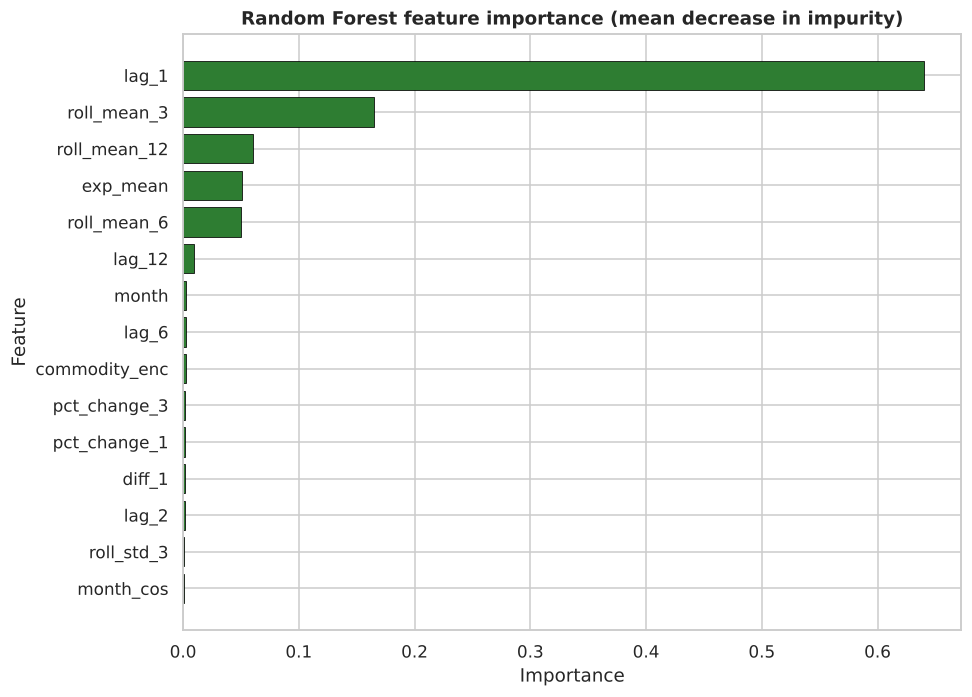

In [ ]:
rf_importance = tm.feature_importances(rf_model, list(X_train.columns))
print("Top 12 features by mean decrease in impurity:")
print(rf_importance.head(12).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 6.5))
d = rf_importance.head(15).iloc[::-1]
ax.barh(d["feature"], d["importance"], color="#2E7D32", edgecolor="black", linewidth=.5)
ax.set_title("Random Forest feature importance (mean decrease in impurity)", fontweight="bold")
ax.set_xlabel("Importance"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

## 13. Boosting — XGBoost Regressor

### How boosting works

Boosting attacks the opposite problem to bagging: **bias**. Instead of averaging many strong,
independent models, it adds together many **weak** ones — shallow trees — each trained to fix what
the current ensemble still gets wrong.

The sequence is:

1. Start with a constant prediction (the mean training price).
2. Compute how wrong the current ensemble is on every training row — specifically, the gradient of
   the loss with respect to the prediction.
3. Fit a **new shallow tree to those gradients**, not to the original target.
4. Add that tree to the ensemble, scaled down by the **learning rate**.
5. Repeat for `n_estimators` rounds.

Because step 3 fits the *errors that remain*, every tree concentrates on the rows the ensemble
currently handles badly. Bias falls step by step. The price is that the trees are no longer
independent: tree 400 only makes sense on top of trees 1–399, so boosting cannot be parallelised
across trees the way bagging can, and it will happily start fitting noise if allowed to run too
long.

### What XGBoost adds

* **Second-order optimisation.** It uses both the gradient and the curvature (Hessian) of the loss,
  which is a Newton step rather than plain gradient descent, so it converges in fewer rounds.
* **Regularised objective.** An explicit L2 (`reg_lambda`) and L1 penalty on leaf weights, plus a
  complexity cost per leaf, is written into the objective the trees optimise — not bolted on
  afterwards.
* **Shrinkage.** The `learning_rate` scales each tree's contribution, so no single tree can dominate
  and later trees get a chance to correct it.
* **Subsampling.** `subsample` (rows) and `colsample_bytree` (features) inject randomness, borrowing
  bagging's variance reduction inside a boosting framework.
* **Histogram split finding.** `tree_method="hist"` buckets feature values, which is why a 600-tree
  fit on this table takes under two seconds while a 300-tree forest takes twenty-five.

### The key contrast with bagging

| | Bagging (Random Forest) | Boosting (XGBoost) |
|---|---|---|
| Trees built | in parallel, independently | sequentially, each depending on all before it |
| Each tree sees | a bootstrap resample | the current ensemble's errors |
| Tree depth | deep, fully grown | shallow (depth 4–8 here) |
| Primarily reduces | variance | bias |
| Combination | plain average | weighted sum |
| Overfitting risk | low; more trees rarely hurt | real; needs learning rate, depth and round limits |

In [ ]:
if USE_SAVED_MODELS:
    xgb_model = artefacts["models"]["xgboost"]
    xgb_params = (artefacts["metadata"].get("tuning", {})
                  .get("xgboost", {}).get("best_params", {}))
    xgb_tuning = (artefacts["metadata"].get("tuning", {}) or {}).get("xgboost", {})
    print("Loaded the tuned XGBoost model from models/saved_models/")
else:
    xgb_out = tm.train_xgboost(X_train, y_train, tune=True)
    xgb_model = xgb_out["model"]
    xgb_params = xgb_out.get("best_params", {})
    xgb_tuning = {k: v for k, v in xgb_out.items() if k != "model"}
    print("Trained XGBoost in this notebook")

print("\nChosen hyperparameters:")
for k in ("n_estimators", "learning_rate", "max_depth", "subsample",
          "colsample_bytree", "min_child_weight", "reg_lambda"):
    if k in xgb_params:
        print(f"  {k:<18}: {xgb_params[k]}")
if xgb_tuning.get("best_cv_rmse"):
    print(f"\nBest time-series CV RMSE during tuning: {xgb_tuning['best_cv_rmse']:,.3f} LKR")

xgb_pred_test = xgb_model.predict(X_test)
xgb_metrics = utils.regression_metrics(y_test, xgb_pred_test)
print("\nXGBoost - test set:")
for k, v in xgb_metrics.items():
    print(f"  {k:<10}: {v:,.4f}" if isinstance(v, float) else f"  {k:<10}: {v:,}")

Loaded the tuned XGBoost model from models/saved_models/

Chosen hyperparameters:
  n_estimators      : 400
  learning_rate     : 0.03
  max_depth         : 8
  subsample         : 0.8
  colsample_bytree  : 0.6
  min_child_weight  : 5
  reg_lambda        : 1.0

Best time-series CV RMSE during tuning: 209.045 LKR

XGBoost - test set:
  MAE       : 73.6796
  RMSE      : 121.2552
  R2        : 0.9691
  MAPE_pct  : 14.1443
  n_obs     : 5,006


Top 12 features by gain:
      feature  importance
        lag_1       0.546
 roll_mean_12       0.107
  roll_mean_3       0.095
  roll_mean_6       0.088
       lag_12       0.068
     exp_mean       0.055
        lag_2       0.003
        month       0.003
commodity_enc       0.003
    month_cos       0.003
      quarter       0.002
        lag_6       0.002


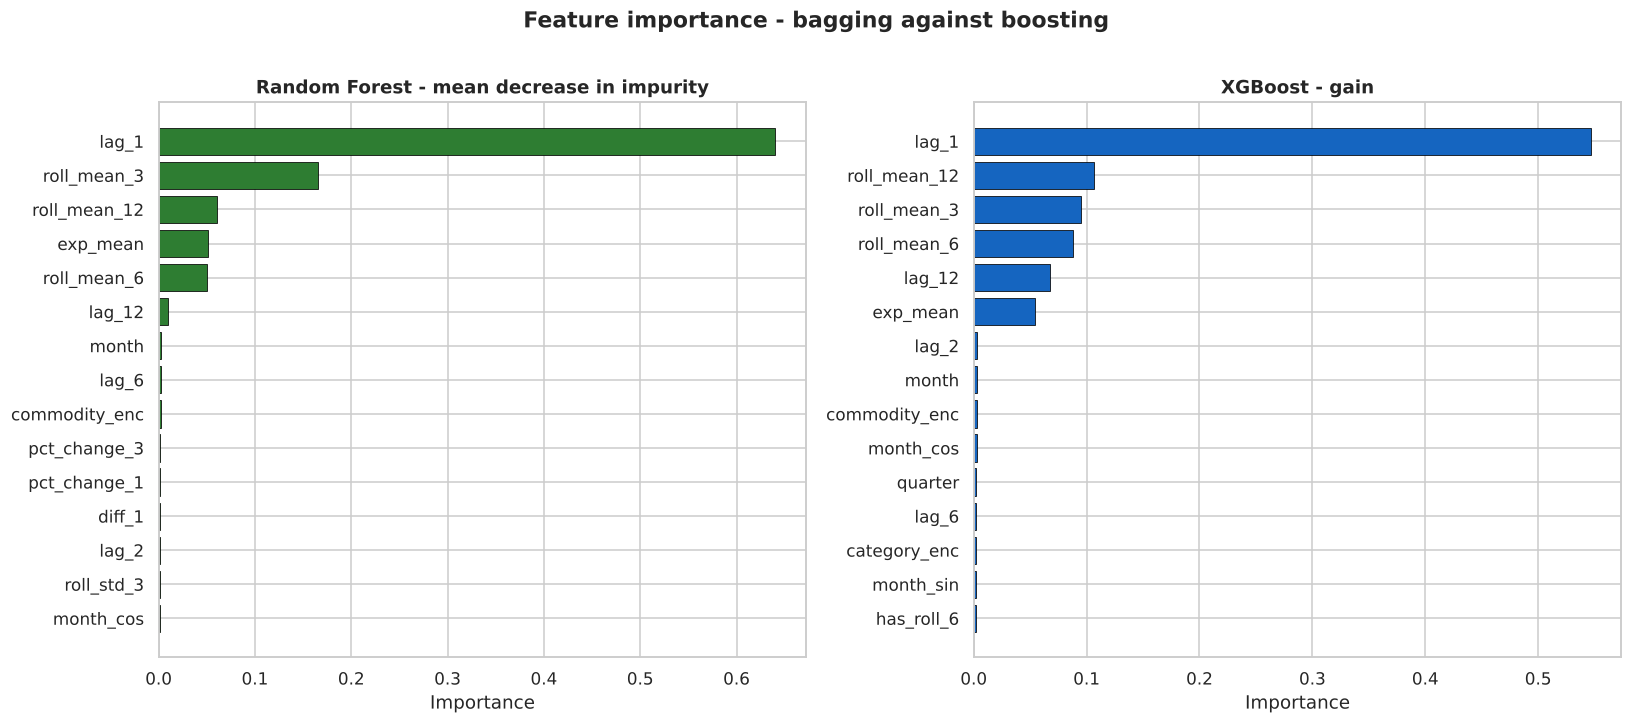


Top features where the two disagree most:
              random_forest  xgboost   gap
feature                                   
lag_1                 0.640    0.546 0.094
roll_mean_3           0.165    0.095 0.071
lag_12                0.010    0.068 0.058
roll_mean_12          0.060    0.107 0.046
roll_mean_6           0.050    0.088 0.038
exp_mean              0.051    0.055 0.004
quarter               0.000    0.002 0.002
lag_2                 0.001    0.003 0.002


In [ ]:
xgb_importance = tm.feature_importances(xgb_model, list(X_train.columns))
print("Top 12 features by gain:")
print(xgb_importance.head(12).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
d = rf_importance.head(15).iloc[::-1]
axes[0].barh(d["feature"], d["importance"], color="#2E7D32", edgecolor="black", linewidth=.5)
axes[0].set_title("Random Forest - mean decrease in impurity", fontweight="bold")
axes[0].set_xlabel("Importance")
d = xgb_importance.head(15).iloc[::-1]
axes[1].barh(d["feature"], d["importance"], color="#1565C0", edgecolor="black", linewidth=.5)
axes[1].set_title("XGBoost - gain", fontweight="bold")
axes[1].set_xlabel("Importance")
fig.suptitle("Feature importance - bagging against boosting", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

comparison = (rf_importance.set_index("feature")["importance"]
              .rename("random_forest")
              .to_frame()
              .join(xgb_importance.set_index("feature")["importance"].rename("xgboost")))
print("\nTop features where the two disagree most:")
comparison["gap"] = (comparison["random_forest"] - comparison["xgboost"]).abs()
print(comparison.sort_values("gap", ascending=False).head(8).round(4).to_string())

The two importance measures are **not on the same scale** and are not computed the same way:
the forest's is mean decrease in impurity across all splits, XGBoost's is total gain. They are
therefore compared for *ranking*, not for magnitude. Section 20 adds **permutation importance**,
which is computed on the held-out test set and so measures what each model actually relies on to
generalise, rather than what it used to fit the training data.

## 14. Stacking — Random Forest + XGBoost + Linear Regression, with a Ridge Meta-learner

### How stacking works

Bagging and boosting both combine many copies of the *same* kind of model. Stacking combines
*different algorithms* and then learns, from data, how much to trust each one.

It has two levels:

* **Level 0 — base learners.** Several different models are trained on the same features. Here, as
  the brief specifies:
  1. `RandomForestRegressor` — non-linear, variance-reducing
  2. `XGBRegressor` — non-linear, bias-reducing
  3. `LinearRegression` — linear, and the only one of the three that can **extrapolate** beyond the
     training price range
* **Level 1 — meta-learner.** A second model takes the base learners' predictions *as its input
  features* and learns the best combination. Here that is `Ridge`.

If the forest tends to under-predict expensive commodities while the linear model handles them
better, a well-fitted meta-learner can lean on the linear model exactly where it helps. Stacking can
only beat its base learners when they make **different** mistakes; if they are all wrong on the same
rows, no weighting can fix those rows.

### Why Ridge as the meta-learner

The three base predictions are highly collinear — they are all estimates of the same price, so they
correlate above 0.99. Ordinary least squares on collinear inputs produces unstable, wildly opposed
coefficients (e.g. +4.2 on one model and −3.3 on another) that fit the training blend and generalise
poorly. Ridge's L2 penalty shrinks the coefficients toward zero and keeps them stable and
interpretable as blending weights. Its one hyperparameter, `alpha`, controls how hard it shrinks, and
is chosen on the chronological validation split.

### Preventing leakage — the critical detail

The meta-learner must **not** be trained on base-model predictions for rows those base models were
fitted on. A Random Forest predicting a row it has already seen is nearly exact, so the meta-learner
would learn "the forest is always right", which is false out of sample. Base-model predictions for
the meta-learner must therefore be **out-of-fold**.

For time-series data there is a second requirement: those folds must be **time-ordered**, so no
out-of-fold prediction for month *m* comes from a model that had seen month *m* or later.

### Why not `sklearn.ensemble.StackingRegressor`

It cannot do this. Internally it calls `cross_val_predict`, which requires the CV splitter to be a
true **partition** of the data — every row in exactly one test fold. `TimeSeriesSplit` is not a
partition: its earliest rows are never in any test fold, because there is nothing before them to
train on. Passing `TimeSeriesSplit` to `StackingRegressor` raises:

```
ValueError: cross_val_predict only works for partitions
```

Using `KFold` instead would make it run, but `KFold` shuffles time: a fold could train on 2025 and
predict 2024, which is the leakage the whole chronological design exists to prevent.

`TimeAwareStackingRegressor` (in `src/train_models.py`) therefore implements the same algorithm
correctly:

1. Split the training rows with `TimeSeriesSplit` (expanding windows).
2. For each fold, fit fresh base learners on the fold's training part and predict its test part →
   the out-of-fold matrix. Rows in the first fold get no prediction and are **excluded** from
   meta-training rather than imputed.
3. Fit Ridge on that matrix.
4. Refit all base learners on the full training set, for use at prediction time.

The out-of-fold matrix does not depend on `alpha`, so it is built **once** and only the Ridge is
refitted per candidate — which is what makes the alpha search affordable.

In [ ]:
if USE_SAVED_MODELS:
    stacking_model = artefacts["models"]["stacking"]
    stack_info = (artefacts["metadata"].get("tuning", {}) or {}).get("stacking", {})
    print("Loaded the fitted stacking ensemble from models/saved_models/")
else:
    stack_out = tm.train_stacking(
        X_train, y_train, X_val, y_val,
        rf_params={k: v for k, v in rf_params.items()
                   if k in {"n_estimators", "max_depth", "min_samples_leaf", "max_features"}},
        xgb_params={k: v for k, v in xgb_params.items()
                    if k in {"n_estimators", "learning_rate", "max_depth", "subsample",
                             "colsample_bytree", "min_child_weight", "reg_lambda"}},
        tune_alpha=not QUICK_TUNING,
    )
    stacking_model = stack_out["model"]
    stack_info = {k: v for k, v in stack_out.items() if k != "model"}
    print("Fitted the stacking ensemble in this notebook")

print("\nBase learners :", stack_info.get("base_learners", stacking_model.names_))
print("Meta-learner  : Ridge (inside a StandardScaler pipeline)")
print("Chosen alpha  :", (stack_info.get("best_params") or {}).get("ridge_alpha", "n/a"))
print(f"\nOut-of-fold rows used to train the meta-learner : "
      f"{stack_info.get('n_oof_rows', stacking_model.n_oof_rows_):,}")
print(f"Earliest training rows with no OOF prediction   : "
      f"{stack_info.get('n_rows_without_oof', stacking_model.n_rows_without_oof_):,}")
print(f"\nLeakage control: {stack_info.get('leakage_control', '')}")

Loaded the fitted stacking ensemble from models/saved_models/

Base learners : ['random_forest', 'xgboost', 'linear_regression']
Meta-learner  : Ridge (inside a StandardScaler pipeline)
Chosen alpha  : 10.0

Out-of-fold rows used to train the meta-learner : 14,740
Earliest training rows with no OOF prediction   : 3,688

Leakage control: Meta-learner trained only on TimeSeriesSplit out-of-fold predictions; 3688 earliest training rows had no OOF prediction and were excluded from meta-training.


Ridge blending weights on the (standardised) base predictions:

  random_forest       :     422.9314
  xgboost             :    -240.6583
  linear_regression   :     460.7013
  intercept           :     596.1406

A larger absolute weight means the meta-learner leans on that base learner more.
Weights apply to standardised inputs, so they are comparable with each other.


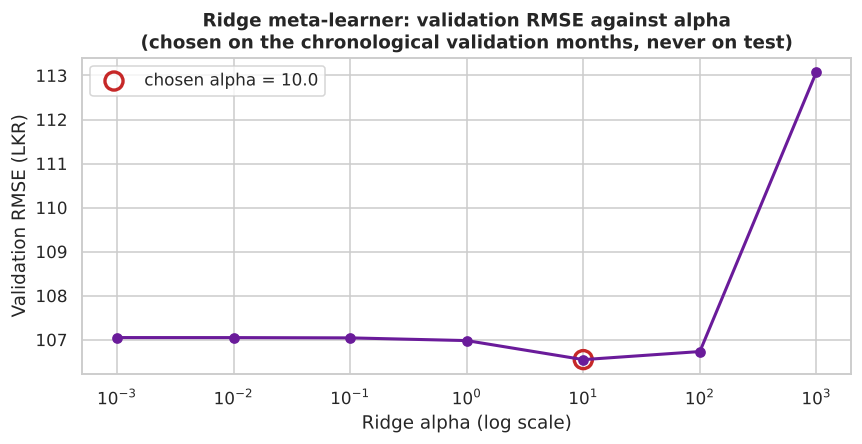

    alpha  val_rmse
    0.001   107.048
    0.010   107.048
    0.100   107.041
    1.000   106.980
   10.000   106.547
  100.000   106.731
1,000.000   113.081


In [ ]:
weights = stack_info.get("meta_weights") or stacking_model.meta_weights()
print("Ridge blending weights on the (standardised) base predictions:\n")
for k, v in weights.items():
    print(f"  {k:<20}: {v:>12,.4f}")
print("\nA larger absolute weight means the meta-learner leans on that base learner more.")
print("Weights apply to standardised inputs, so they are comparable with each other.")

if stack_info.get("alpha_search"):
    al = pd.DataFrame(stack_info["alpha_search"])
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(al["alpha"], al["val_rmse"], marker="o", color="#6A1B9A", lw=2)
    ax.set_xscale("log")
    best_a = al.loc[al["val_rmse"].idxmin()]
    ax.scatter([best_a["alpha"]], [best_a["val_rmse"]], s=140, facecolors="none",
               edgecolors="#C62828", linewidths=2.2, label=f"chosen alpha = {best_a['alpha']}")
    ax.set_title("Ridge meta-learner: validation RMSE against alpha\n"
                 "(chosen on the chronological validation months, never on test)",
                 fontweight="bold")
    ax.set_xlabel("Ridge alpha (log scale)"); ax.set_ylabel("Validation RMSE (LKR)")
    ax.legend()
    plt.tight_layout(); plt.show()
    print(al.to_string(index=False))

In [ ]:
stack_pred_test = stacking_model.predict(X_test)
stack_metrics = utils.regression_metrics(y_test, stack_pred_test)
print("Stacking - test set:")
for k, v in stack_metrics.items():
    print(f"  {k:<10}: {v:,.4f}" if isinstance(v, float) else f"  {k:<10}: {v:,}")

# How much do the base learners actually disagree? This caps stacking's potential gain.
base_test = stacking_model.base_predictions_frame(X_test)
print("\nCorrelation between the base learners' test predictions:")
print(base_test.corr().round(4).to_string())

base_err = pd.DataFrame({c: np.asarray(y_test) - base_test[c] for c in base_test.columns})
print("\nCorrelation between the base learners' test ERRORS:")
print(base_err.corr().round(4).to_string())
print("\nStacking can only improve on its base learners where their errors differ.")
print("Error correlations near 1.0 mean they are wrong on the same rows, which limits the gain.")

print("\nIndividual base learners on the test set (for context - not entries in the comparison):")
for c in base_test.columns:
    m = utils.regression_metrics(y_test, base_test[c])
    print(f"  {c:<20} MAE {m['MAE']:>9,.2f}   RMSE {m['RMSE']:>9,.2f}   R2 {m['R2']:>7.4f}")

Stacking - test set:
  MAE       : 71.9214
  RMSE      : 114.9520
  R2        : 0.9723
  MAPE_pct  : 14.3510
  n_obs     : 5,006



Correlation between the base learners' test predictions:
                   random_forest  xgboost  linear_regression
random_forest              1.000    0.999              0.997
xgboost                    0.999    1.000              0.997
linear_regression          0.997    0.997              1.000

Correlation between the base learners' test ERRORS:
                   random_forest  xgboost  linear_regression
random_forest              1.000    0.968              0.911
xgboost                    0.968    1.000              0.887
linear_regression          0.911    0.887              1.000

Stacking can only improve on its base learners where their errors differ.
Error correlations near 1.0 mean they are wrong on the same rows, which limits the gain.

Individual base learners on the test set (for context - not entries in the comparison):
  random_forest        MAE     73.39   RMSE    120.95   R2  0.9693
  xgboost              MAE     73.68   RMSE    121.26   R2  0.9691
  linear_regre

## 15. Hybrid — Random Forest + ARIMA

### Why combine them at all

The three ensembles so far share a blind spot. Each row is treated as an independent observation:
features in, price out. But these rows are not independent — they are **time series**. If the forest
has under-predicted a particular rice series in Jaffna for four months running, that is real
information about next month, and a model that treats rows independently simply discards it.

A classical time-series model is built for exactly that structure, and ARIMA is built for exactly
that question: given the recent path of a sequence, what comes next?

The hybrid therefore splits the problem along its natural seam:

* **Random Forest** models the *level* — the cross-sectional, non-linear mapping from commodity,
  market, season and recent prices to a price.
* **ARIMA** models the *residual structure* — whatever autocorrelation is left in the forest's
  errors.

$$\hat{y}_{\text{hybrid}} = \underbrace{\hat{y}_{\text{RF}}}_{\text{level}} + \underbrace{\hat{r}_{\text{ARIMA}}}_{\text{residual correction}}$$

### Why Random Forest for the first stage

It handles the heterogeneous panel well, needs little tuning, is robust to the flagged extremes, and
captures interactions between commodity, market and recent level without being told the functional
form. It is also the component whose weakness ARIMA most directly complements: a forest cannot
extrapolate and ignores serial correlation.

### Why ARIMA for the second stage

ARIMA(p, d, q) combines three mechanisms: **AR(p)**, a regression on the series' own past values;
**I(d)**, differencing to remove a trend; and **MA(q)**, a regression on past forecast errors.
Fitted to a residual sequence, the AR and MA terms capture persistent over- or under-prediction and
its decay. If the forest's residuals were pure white noise, ARIMA would correctly find nothing to
model and the correction would be near zero — so this stage can only help or be neutral, never
destroy a good forest fit, provided it is fitted honestly.

`d` is held at **0** for every candidate order. Regression residuals should already be mean-reverting,
and AIC is only comparable between models fitted to the *same* differenced series — mixing `d=0` and
`d=1` candidates would make the AIC-based order selection meaningless.

### How the training residuals are calculated — and why out-of-fold is essential

This is the step where a hybrid most easily goes wrong.

A Random Forest asked to predict a training row it has already seen is nearly exact. Its *in-sample*
residuals are tiny and consist mostly of memorisation noise. An ARIMA fitted to those would model the
pattern of the forest's **memorisation**, not of its **generalisation error** — and the resulting
correction would be useless out of sample, or actively harmful.

So the residuals come from **out-of-fold** predictions, using `TimeSeriesSplit`:

$$r_{s,t} = y_{s,t} - \hat{y}^{\text{OOF}}_{\text{RF}}(s,t)$$

where $\hat{y}^{\text{OOF}}$ for month *t* comes from a forest fitted only on months **before** *t*.
These residuals have the same character as the errors the forest will make on the test months, which
is what makes ARIMA's correction transferable.

### How ARIMA models the residual patterns

Residuals are grouped **by price series** (commodity | market | unit | pricetype) and ordered by
month. For each series with enough residuals, every candidate order is fitted and the one with the
lowest AIC is kept. Series are handled separately because a forest's bias is series-specific: it may
systematically under-predict Jaffna fish while being unbiased on Colombo rice, and a single pooled
residual model would average those away.

### How the two predictions are combined, and how leakage is prevented

| Control | Mechanism |
|---|---|
| Residuals are generalisation errors | Out-of-fold, not in-sample |
| Out-of-fold folds respect time | `TimeSeriesSplit` expanding windows |
| ARIMA sees no future data | Fitted to **training** residuals only; validation and test residuals are never computed |
| Forecasts are not re-anchored | The forecast origin is the **last training month**. A test month *k* months later uses the *k*-step-ahead forecast, never a one-step forecast updated with an actual it has not been given |
| No test actual is used | The correction for each series is produced before any test value is read |

### Series with too little history — a real limitation, stated

ARIMA fitted to eight observations estimates nothing useful. A series needs at least
`MIN_RESIDUALS_FOR_ARIMA` (12) training residuals; below that it receives a **zero correction** and
falls back to the plain Random Forest prediction. Because most series in this file begin in 2023,
this materially limits how many series the hybrid can actually correct, and therefore how far it can
move the overall metrics. The counts are reported below rather than hidden — the honest reading is
that the hybrid is a *partial* correction on this dataset, not a wholesale replacement for the
forest.

**ARIMA is not reported as a fifth model.** It exists here only as the hybrid's residual component.

In [ ]:
if USE_SAVED_MODELS:
    hybrid = artefacts["models"]["hybrid"]
    hybrid_summary = (artefacts.get("arima_info") or {}).get("summary") or hybrid.summary()
    print("Loaded the fitted hybrid model from models/saved_models/")
else:
    hybrid = hm.RandomForestARIMAHybrid(rf_model=rf_model).fit(
        train_df, X_train, y_train, list(X_train.columns), rf_already_fitted=True)
    hybrid_summary = hybrid.summary()
    print("Fitted the hybrid model in this notebook")

print("\n" + "=" * 70)
print("HYBRID MODEL SUMMARY")
print("=" * 70)
print(f"Forecast origin (last training month) : {hybrid_summary['forecast_origin_month']}")
print(f"Out-of-fold folds                     : {hybrid_summary['n_oof_folds']}")
print(f"Training rows with an OOF residual    : {hybrid_summary['n_training_rows_with_oof']:,}")
print(f"Training rows without one (first fold): {hybrid_summary['n_training_rows_without_oof']:,}")
print(f"\nMinimum residuals required for ARIMA  : {hybrid_summary['min_residuals_for_arima']}")
print(f"Series given an ARIMA residual model  : {hybrid_summary['n_series_with_arima']:,}")
print(f"Series falling back to RF only        : {hybrid_summary['n_series_without_arima']:,}")

total = hybrid_summary['n_series_with_arima'] + hybrid_summary['n_series_without_arima']
print(f"Coverage                              : "
      f"{hybrid_summary['n_series_with_arima']/total*100:.1f}% of series")

rs = hybrid_summary["oof_residual_summary"]
print(f"\nOut-of-fold residuals: n={rs['n_residuals']:,}, mean={rs['mean']:,.2f} LKR, "
      f"sd={rs['std']:,.2f} LKR")
print(f"MAE of the OOF predictions the residuals come from: "
      f"{rs['mae_of_oof_predictions']:,.2f} LKR")
print("\nLeakage controls:")
for c in hybrid_summary["leakage_controls"]:
    print(f"  - {c}")

Loaded the fitted hybrid model from models/saved_models/

HYBRID MODEL SUMMARY
Forecast origin (last training month) : 2024-12-01
Out-of-fold folds                     : 4
Training rows with an OOF residual    : 14,740
Training rows without one (first fold): 3,688

Minimum residuals required for ARIMA  : 12
Series given an ARIMA residual model  : 634
Series falling back to RF only        : 495
Coverage                              : 56.2% of series

Out-of-fold residuals: n=14,740, mean=39.92 LKR, sd=179.25 LKR
MAE of the OOF predictions the residuals come from: 87.29 LKR

Leakage controls:
  - Residuals come from TimeSeriesSplit out-of-fold predictions, not in-sample fits.
  - ARIMA is fitted to training residuals only.
  - Forecast origin is the last training month; test month k uses the k-step forecast.
  - No test or validation actual is used to produce the correction.


ARIMA orders selected by AIC (d held at 0 throughout):

order (p,d,q)  series  share
    (0, 0, 0)     280 44.200
    (0, 0, 1)     129 20.300
    (1, 0, 0)      72 11.400
    (0, 0, 2)      71 11.200
    (2, 0, 1)      40  6.300
    (2, 0, 0)      31  4.900
    (1, 0, 1)      11  1.700


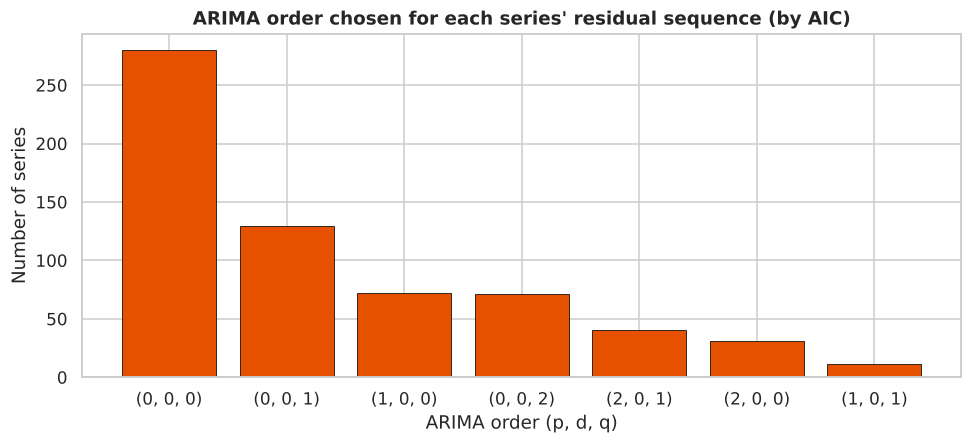


An order of (0,0,0) means AIC preferred a constant: for that series the forest's 
residuals carry no usable autocorrelation, so the correction is just a level shift.


In [ ]:
print("ARIMA orders selected by AIC (d held at 0 throughout):\n")
oc = hybrid_summary.get("arima_order_counts", {})
if oc:
    ordf = (pd.DataFrame(sorted(oc.items(), key=lambda kv: -kv[1]),
                         columns=["order (p,d,q)", "series"])
            .assign(share=lambda d: (d["series"] / d["series"].sum() * 100).round(1)))
    print(ordf.to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.bar(ordf["order (p,d,q)"], ordf["series"], color="#E65100",
           edgecolor="black", linewidth=.5)
    ax.set_title("ARIMA order chosen for each series' residual sequence (by AIC)",
                 fontweight="bold")
    ax.set_xlabel("ARIMA order (p, d, q)"); ax.set_ylabel("Number of series")
    plt.tight_layout(); plt.show()
    print("\nAn order of (0,0,0) means AIC preferred a constant: for that series the forest's "
          "\nresiduals carry no usable autocorrelation, so the correction is just a level shift.")

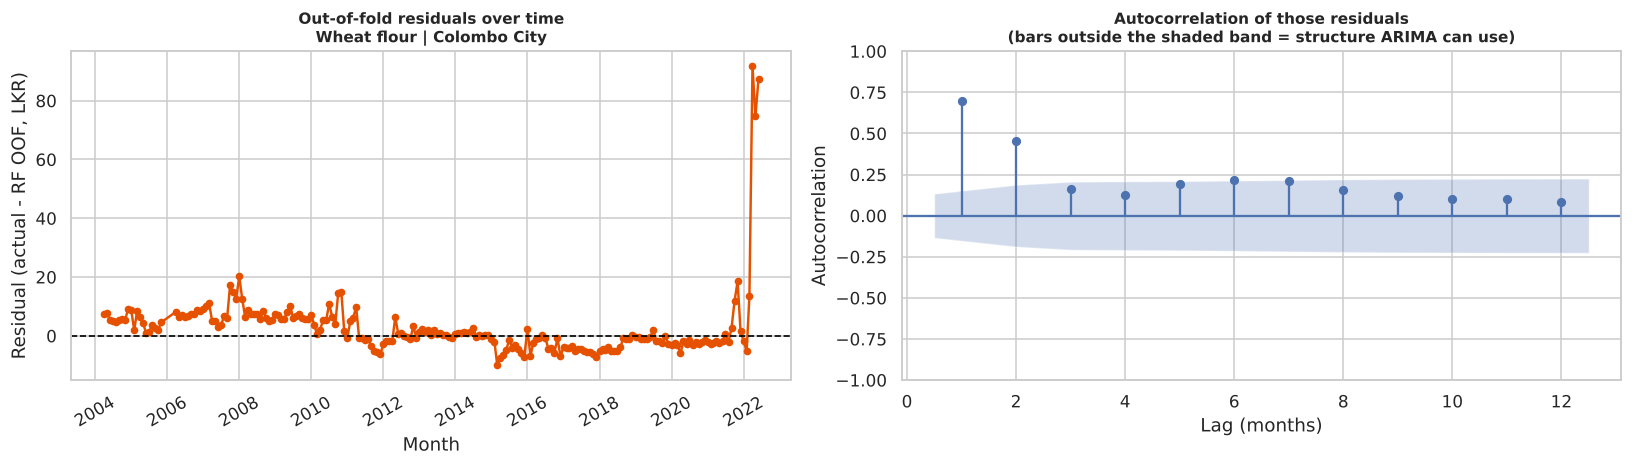

Series: Wheat flour | Colombo City | KG | Retail
  training residuals : 215
  ARIMA fitted       : True
  selected order     : (1, 0, 0)  (AIC 1423.58)
  residual sd        : 11.19 LKR


In [ ]:
# The residual sequence for one series, and what ARIMA found in it
resid_all = getattr(hybrid, "training_residuals_", None)
if resid_all is not None and len(resid_all):
    counts = resid_all.groupby(utils.SERIES_ID).size().sort_values(ascending=False)
    sid = counts.index[0]
    d = resid_all[resid_all[utils.SERIES_ID] == sid].sort_values("month_start")

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
    axes[0].plot(d["month_start"], d["residual"], marker="o", ms=4, color="#E65100", lw=1.6)
    axes[0].axhline(0, color="black", ls="--", lw=1.1)
    axes[0].set_title(f"Out-of-fold residuals over time\n{' | '.join(sid.split(' | ')[:2])}",
                      fontsize=10, fontweight="bold")
    axes[0].set_xlabel("Month"); axes[0].set_ylabel("Residual (actual - RF OOF, LKR)")
    axes[0].tick_params(axis="x", labelrotation=30)

    from statsmodels.graphics.tsaplots import plot_acf
    nlags = min(12, max(1, len(d) // 2 - 1))
    plot_acf(d["residual"].to_numpy(), lags=nlags, ax=axes[1], zero=False)
    axes[1].set_title("Autocorrelation of those residuals\n"
                      "(bars outside the shaded band = structure ARIMA can use)",
                      fontsize=10, fontweight="bold")
    axes[1].set_xlabel("Lag (months)"); axes[1].set_ylabel("Autocorrelation")
    plt.tight_layout(); plt.show()

    info = hybrid.arima_info_.get(sid, {})
    print(f"Series: {sid}")
    print(f"  training residuals : {info.get('n_obs')}")
    print(f"  ARIMA fitted       : {info.get('ok')}")
    if info.get("ok"):
        print(f"  selected order     : {info.get('order')}  (AIC {info.get('aic')})")
        print(f"  residual sd        : {info.get('resid_std'):,.2f} LKR")
else:
    print("Residual detail is not retained in the saved artefact; "
          "set USE_SAVED_MODELS=False to inspect it.")

In [ ]:
# Predict on the test set and decompose the hybrid into its two parts
hybrid_out = hybrid.predict(test_df, X_test)
hybrid_pred_test = hybrid_out["hybrid"]
hybrid_metrics = utils.regression_metrics(y_test, hybrid_pred_test)

print("Hybrid (Random Forest + ARIMA) - test set:")
for k, v in hybrid_metrics.items():
    print(f"  {k:<10}: {v:,.4f}" if isinstance(v, float) else f"  {k:<10}: {v:,}")

n_corr = int(hybrid_out["corrected"].sum())
print(f"\nTest rows receiving an ARIMA correction : {n_corr:,} of {len(y_test):,} "
      f"({n_corr/len(y_test)*100:.1f}%)")
print(f"Test rows falling back to RF alone      : {len(y_test)-n_corr:,}")

rc = hybrid_out["residual_forecast"][hybrid_out["corrected"]]
if len(rc):
    print(f"\nARIMA residual corrections applied: mean {rc.mean():+,.2f} LKR, "
          f"sd {rc.std():,.2f}, range [{rc.min():+,.2f}, {rc.max():+,.2f}]")

# Did the correction help on the rows where it was actually applied?
mask = hybrid_out["corrected"]
if mask.sum() > 0:
    yt = np.asarray(y_test)[mask]
    print("\nOn the corrected rows only:")
    print(f"  Random Forest alone : MAE {utils.mae(yt, hybrid_out['rf'][mask]):>9,.2f} LKR")
    print(f"  Hybrid (RF + ARIMA) : MAE {utils.mae(yt, hybrid_pred_test[mask]):>9,.2f} LKR")
    delta = utils.mae(yt, hybrid_out['rf'][mask]) - utils.mae(yt, hybrid_pred_test[mask])
    verdict = "improved" if delta > 0 else "worsened"
    print(f"  -> the ARIMA correction {verdict} MAE by {abs(delta):,.2f} LKR "
          f"on these {int(mask.sum()):,} rows")
    print("\nThis is the fairest read on whether the residual model works: the overall")
    print("metric mixes corrected rows with rows where the hybrid is identical to the forest.")

Hybrid (Random Forest + ARIMA) - test set:
  MAE       : 91.7817
  RMSE      : 163.2618
  R2        : 0.9440
  MAPE_pct  : 15.7421
  n_obs     : 5,006

Test rows receiving an ARIMA correction : 2,649 of 5,006 (52.9%)
Test rows falling back to RF alone      : 2,357

ARIMA residual corrections applied: mean +53.74 LKR, sd 179.49, range [-221.42, +1,177.98]

On the corrected rows only:
  Random Forest alone : MAE     78.44 LKR
  Hybrid (RF + ARIMA) : MAE    113.19 LKR
  -> the ARIMA correction worsened MAE by 34.75 LKR on these 2,649 rows

This is the fairest read on whether the residual model works: the overall
metric mixes corrected rows with rows where the hybrid is identical to the forest.


## 16. Hyperparameter Tuning

All tuning uses `GridSearchCV` with **`TimeSeriesSplit`**, scored by negative RMSE. Expanding-window
folds mean every validation fold is strictly later in time than the rows used to fit it, so no
hyperparameter is chosen with the benefit of hindsight.

**The test set is never used for tuning.** It is touched once, in section 17.

**Grid sizes are chosen deliberately.** A 300-tree forest fit on these 18,428 rows takes about 25
seconds on two cores, while a 600-round XGBoost fit takes under two. Each extra parameter value
multiplies the number of fits by the fold count, so the forest gets a compact grid over the
parameters that actually change its behaviour (depth, leaf size, feature subsampling) while XGBoost —
being far cheaper — gets a much wider one. The brief asks for a faster execution option; that is
`FOOD_PRICE_FAST=1` (or `python run_pipeline.py --fast`), which reduces both grids.

The Ridge `alpha` for the stacking meta-learner is tuned separately on the chronological validation
split, because refitting only the meta-learner is cheap once the out-of-fold matrix exists.

In [ ]:
tuning = (artefacts["metadata"].get("tuning") if USE_SAVED_MODELS
          else {"random_forest": rf_tuning, "xgboost": xgb_tuning, "stacking": stack_info})

for name in ("random_forest", "xgboost"):
    t = (tuning or {}).get(name, {})
    if not t:
        continue
    print("=" * 70)
    print(name.replace("_", " ").upper())
    print("=" * 70)
    print(f"Parameter combinations tried : {t.get('n_combinations')}")
    print(f"Time-series CV folds         : {t.get('cv_folds')}")
    print(f"Total model fits             : "
          f"{(t.get('n_combinations') or 0) * (t.get('cv_folds') or 0)}")
    print(f"Tuning time                  : {t.get('tuning_seconds')} s")
    print(f"Best CV RMSE                 : {t.get('best_cv_rmse', float('nan')):,.3f} LKR")
    print(f"Best parameters              : {t.get('best_params')}")
    if t.get("cv_results_summary"):
        print("\nTop 5 configurations by CV RMSE:")
        print(pd.DataFrame(t["cv_results_summary"]).to_string(index=False))
    print()

RANDOM FOREST
Parameter combinations tried : 8
Time-series CV folds         : 3
Total model fits             : 24
Tuning time                  : 266.2 s
Best CV RMSE                 : 168.761 LKR
Best parameters              : {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 300}

Top 5 configurations by CV RMSE:
                                                                              params  cv_rmse  cv_rmse_std  rank
  {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 300}  168.761      147.062     1
{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 300}  169.789      148.652     2
  {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 300}  174.763      155.328     3
{'max_depth': None, 'max_features': 0.4, 'min_samples_leaf': 1, 'n_estimators': 300}  175.889      159.004     4
  {'max_depth': 20, 'max_features': 0.4, 'min_samples_leaf': 1, 'n_estimators': 300}  176.4

In [ ]:
# Does the tuning ranking hold up on the validation split? (a sanity check, not a selection)
rows = []
for key, model in [("random_forest", rf_model), ("xgboost", xgb_model),
                   ("stacking", stacking_model)]:
    m = utils.regression_metrics(y_val, model.predict(X_val))
    rows.append({"model": utils.MODEL_LABELS[key], "val_MAE": m["MAE"],
                 "val_RMSE": m["RMSE"], "val_R2": m["R2"]})
val_tbl = pd.DataFrame(rows).sort_values("val_MAE")
print("Validation-split performance (2025-01 to 2025-03):")
print(val_tbl.round(4).to_string(index=False))
print("\nThe validation split is used for tuning decisions only.")
print("The reported comparison in section 18 uses the untouched test months.")

Validation-split performance (2025-01 to 2025-03):
                                model  val_MAE  val_RMSE  val_R2
              Bagging - Random Forest   66.713   107.777   0.967
                   Boosting - XGBoost   68.388   108.554   0.967
Stacking - RF + XGB + LR (Ridge meta)   76.266   106.547   0.968

The validation split is used for tuning decisions only.
The reported comparison in section 18 uses the untouched test months.


## 17. Model Evaluation

All four approaches are scored on **exactly the same test rows** — the chronological test split
(2025-04 to 2025-09) — so the comparison is like-for-like.

**The three required metrics**

* **MAE** (mean absolute error), in LKR. The average size of a miss, in the units of the problem.
  Easy to interpret and does not over-weight extremes. *Lower is better.*
* **RMSE** (root mean squared error), in LKR. Squares errors before averaging, so a few large
  misses dominate. A model with low MAE but high RMSE is usually right but occasionally badly wrong.
  *Lower is better.*
* **R²**. The share of variance in the test prices explained by the model, relative to always
  predicting the test mean. *Higher is better; 1.0 is perfect.*

**MAPE** is reported alongside as supporting information. It is not one of the required metrics, but
because this panel mixes commodities priced at 11 LKR with commodities priced at 3,700 LKR, a
percentage error is the only fair way to compare accuracy *across* commodities (used in section 21).

**On coverage.** All four models predict all 5,006 test rows, so no model is scored on a different
subset. The hybrid's ARIMA correction applies to a *subset of series* — reported in section 15 — but
the uncorrected rows are still predicted by the hybrid (its forest component), not excluded.

In [ ]:
predictions = {
    "random_forest": np.asarray(rf_pred_test, dtype=float),
    "xgboost":       np.asarray(xgb_pred_test, dtype=float),
    "stacking":      np.asarray(stack_pred_test, dtype=float),
    "hybrid":        np.asarray(hybrid_pred_test, dtype=float),
}

# Every model must cover exactly the same rows
assert all(len(p) == len(y_test) for p in predictions.values())
print(f"All four approaches scored on the same {len(y_test):,} test observations")
print(f"Test period: {split_report['test_period']}")
print(f"Test series: {split_report['test_series']:,}")

comparison_table = ev.build_comparison_table(y_test, predictions)
comparison_table.round(4)

All four approaches scored on the same 5,006 test observations
Test period: 2025-04-01 .. 2025-09-01
Test series: 1,043


,Rank_by_MAE,model_key,Approach,MAE,RMSE,R2,MAPE_pct,n_test_obs
0,1,stacking,Stacking - RF + XGB + LR (Ridge meta),71.921,114.952,0.972,14.351,5006
1,2,random_forest,Bagging - Random Forest,73.393,120.953,0.969,13.803,5006
2,3,xgboost,Boosting - XGBoost,73.680,121.255,0.969,14.144,5006
3,4,hybrid,Hybrid - Random Forest + ARIMA,91.782,163.262,0.944,15.742,5006


In [ ]:
# A trivial persistence benchmark, for CONTEXT ONLY.
# This is not entered into the four-model comparison - it is here to confirm the
# ensembles are doing real work rather than copying last month's price.
naive = X_test["lag_1"].to_numpy(dtype=float)
naive_m = utils.regression_metrics(y_test, naive)
best_m = comparison_table.iloc[0]

print("Context check - 'predict last month's price' on the same test rows:")
print(f"  MAE {naive_m['MAE']:,.2f} LKR | RMSE {naive_m['RMSE']:,.2f} | R2 {naive_m['R2']:.4f}")
print(f"\nBest ensemble ({best_m['Approach']}):")
print(f"  MAE {best_m['MAE']:,.2f} LKR | RMSE {best_m['RMSE']:,.2f} | R2 {best_m['R2']:.4f}")
improve = (naive_m['MAE'] - best_m['MAE']) / naive_m['MAE'] * 100
print(f"\n-> the best ensemble reduces MAE by {improve:.1f}% against naive persistence")
print("\nReported for context only. Naive persistence is NOT one of the four compared")
print("approaches, in line with the brief.")

Context check - 'predict last month's price' on the same test rows:
  MAE 65.55 LKR | RMSE 112.81 | R2 0.9733

Best ensemble (Stacking - RF + XGB + LR (Ridge meta)):
  MAE 71.92 LKR | RMSE 114.95 | R2 0.9723

-> the best ensemble reduces MAE by -9.7% against naive persistence

Reported for context only. Naive persistence is NOT one of the four compared
approaches, in line with the brief.


## 18. Four-Model Comparison

The four approaches, their metrics, and the charts the brief requires: one for MAE, one for RMSE and
one for R².

In [ ]:
show = comparison_table.copy()
show["MAE (LKR)"]  = show["MAE"].round(2)
show["RMSE (LKR)"] = show["RMSE"].round(2)
show["R2"]         = show["R2"].round(4)
show["MAPE (%)"]   = show["MAPE_pct"].round(2)

print("=" * 86)
print("FOUR-MODEL COMPARISON - chronological test set")
print(f"{split_report['test_period']}  |  {len(y_test):,} observations  |  "
      f"{split_report['test_series']:,} price series")
print("=" * 86)
print(show[["Rank_by_MAE", "Approach", "MAE (LKR)", "RMSE (LKR)", "R2", "MAPE (%)"]]
      .to_string(index=False))
print("=" * 86)

best_mae  = ev.identify_best_model(comparison_table, "MAE")
best_rmse = ev.identify_best_model(comparison_table, "RMSE")
best_r2   = ev.identify_best_model(comparison_table, "R2")
print(f"\nBest by MAE  : {best_mae['best_model']}  ({best_mae['best_value']:,.3f} LKR)")
print(f"Best by RMSE : {best_rmse['best_model']}  ({best_rmse['best_value']:,.3f} LKR)")
print(f"Best by R2   : {best_r2['best_model']}  ({best_r2['best_value']:.4f})")
if "margin" in best_mae:
    print(f"\nMAE margin over the runner-up ({best_mae['runner_up']}): "
          f"{best_mae['margin']:,.3f} LKR ({best_mae['margin_pct']:.2f}%)")

FOUR-MODEL COMPARISON - chronological test set
2025-04-01 .. 2025-09-01  |  5,006 observations  |  1,043 price series
 Rank_by_MAE                              Approach  MAE (LKR)  RMSE (LKR)    R2  MAPE (%)
           1 Stacking - RF + XGB + LR (Ridge meta)     71.920     114.950 0.972    14.350
           2               Bagging - Random Forest     73.390     120.950 0.969    13.800
           3                    Boosting - XGBoost     73.680     121.260 0.969    14.140
           4        Hybrid - Random Forest + ARIMA     91.780     163.260 0.944    15.740

Best by MAE  : Stacking - RF + XGB + LR (Ridge meta)  (71.921 LKR)
Best by RMSE : Stacking - RF + XGB + LR (Ridge meta)  (114.952 LKR)
Best by R2   : Stacking - RF + XGB + LR (Ridge meta)  (0.9723)

MAE margin over the runner-up (Bagging - Random Forest): 1.472 LKR (2.00%)


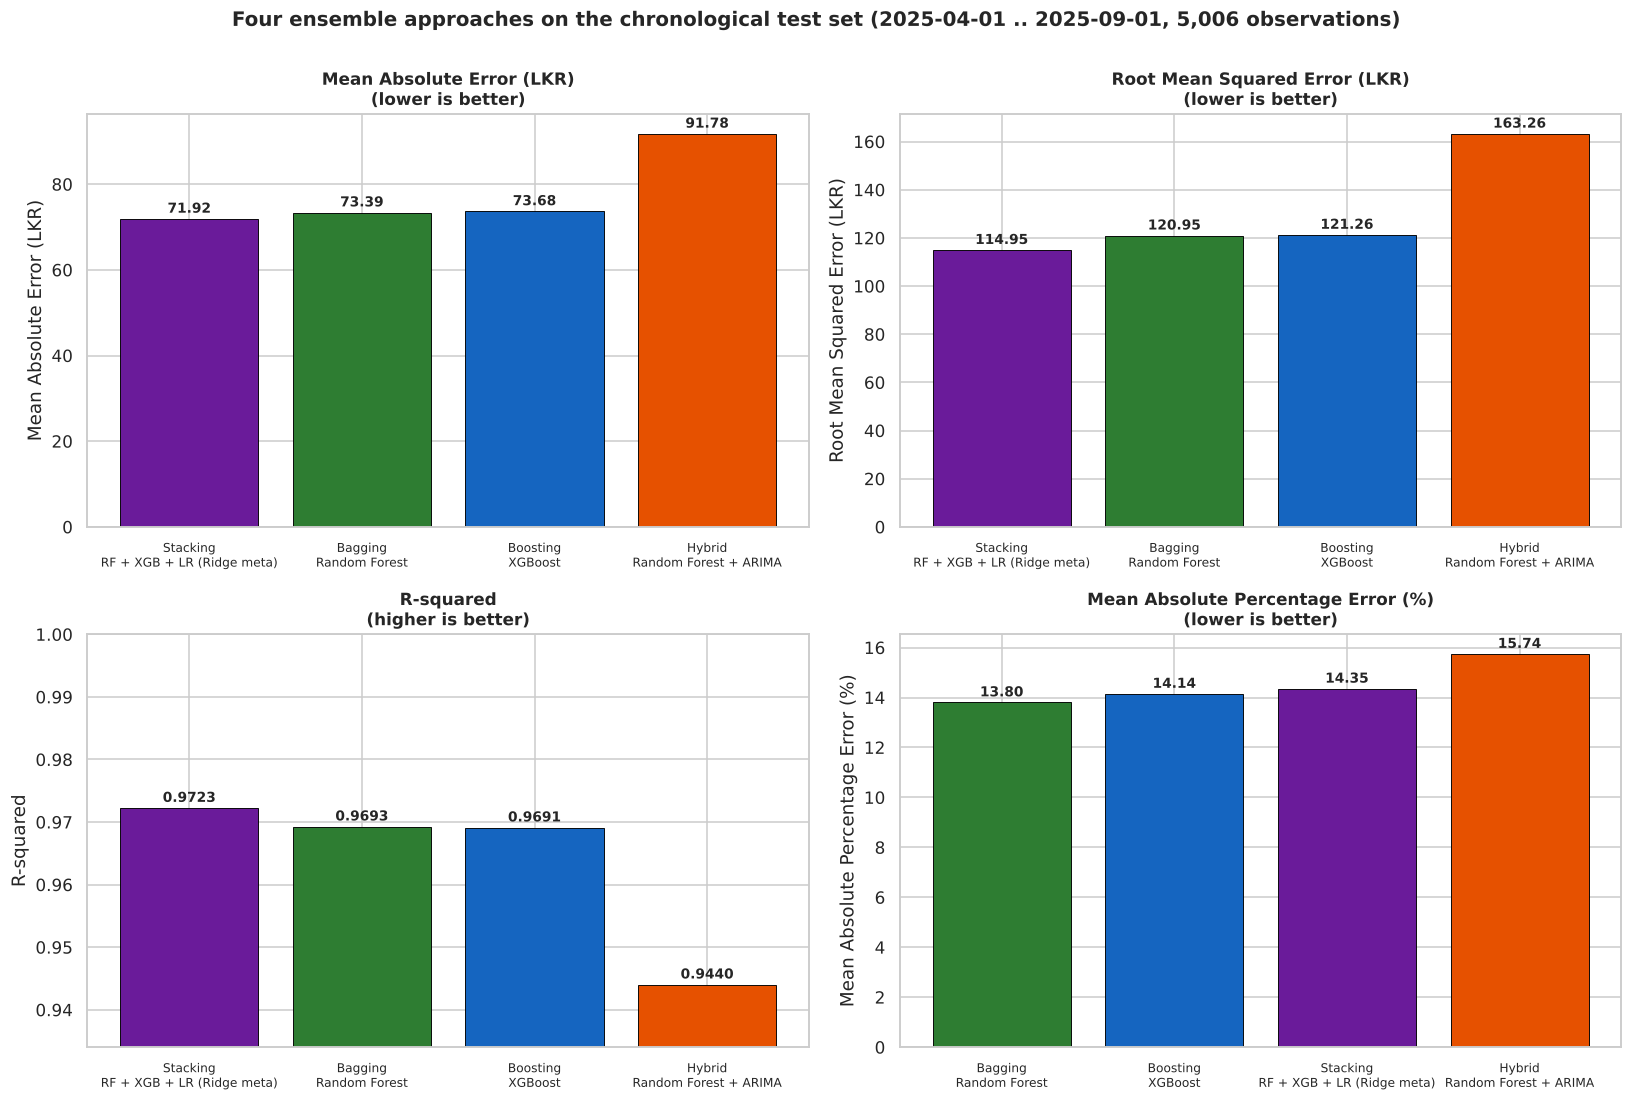

In [ ]:
# The three required comparison charts, plus MAPE
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
specs = [("MAE", "Mean Absolute Error (LKR)", True),
         ("RMSE", "Root Mean Squared Error (LKR)", True),
         ("R2", "R-squared", False),
         ("MAPE_pct", "Mean Absolute Percentage Error (%)", True)]
for ax, (metric, label, asc) in zip(axes.ravel(), specs):
    d = comparison_table.sort_values(metric, ascending=asc)
    colors = [ev.PALETTE.get(k, "#555") for k in d["model_key"]]
    bars = ax.bar(range(len(d)), d[metric], color=colors, edgecolor="black", linewidth=.6)
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels([a.replace(" - ", "\n") for a in d["Approach"]], fontsize=8)
    ax.set_title(f"{label}\n({'lower is better' if asc else 'higher is better'})",
                 fontsize=11, fontweight="bold")
    ax.set_ylabel(label)
    for b, v in zip(bars, d[metric]):
        ax.annotate(f"{v:,.4f}" if metric == "R2" else f"{v:,.2f}",
                    (b.get_x() + b.get_width() / 2, v), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
    if metric == "R2":
        ax.set_ylim(max(0, d[metric].min() - 0.01), 1.0)
fig.suptitle(f"Four ensemble approaches on the chronological test set "
             f"({split_report['test_period']}, {len(y_test):,} observations)",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

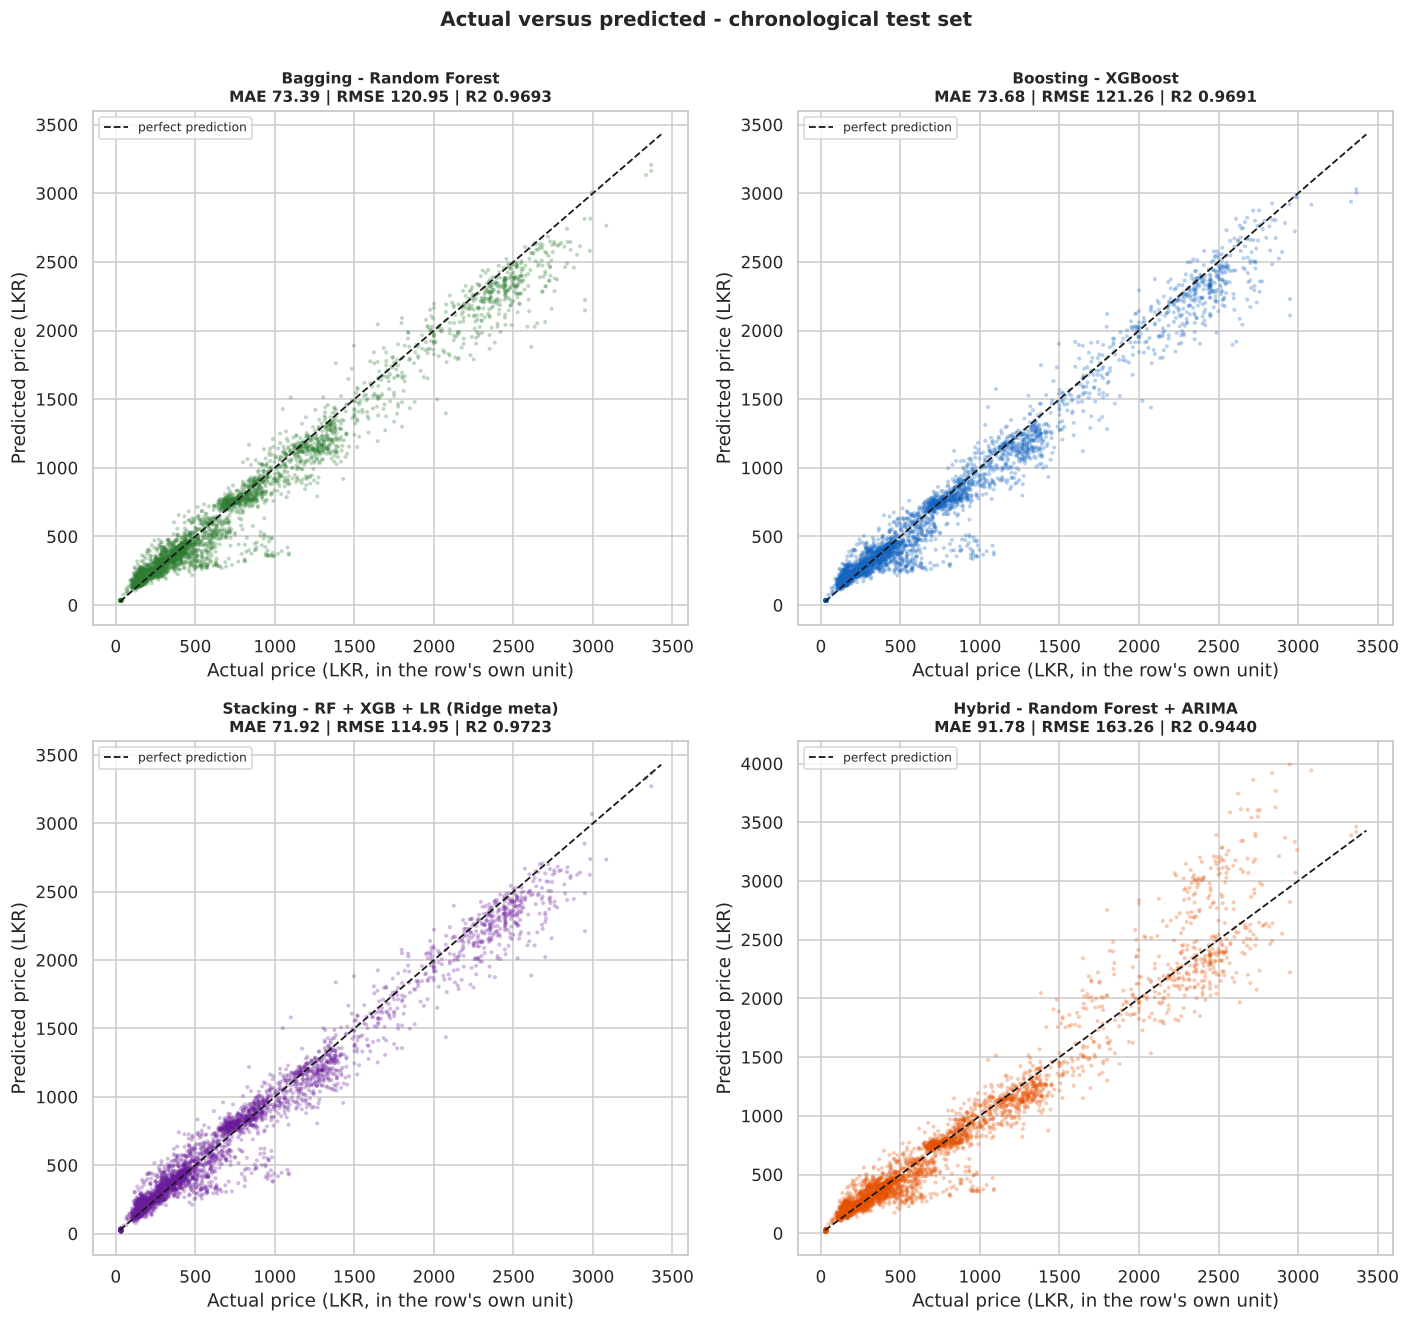

In [ ]:
# Actual versus predicted, one panel per approach
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
yt = np.asarray(y_test, dtype=float)
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(yt), min(4000, len(yt)), replace=False)
lo, hi = yt.min(), yt.max()
for ax, key in zip(axes.ravel(), utils.MODEL_ORDER):
    p = predictions[key]
    ax.scatter(yt[idx], p[idx], s=7, alpha=.3, color=ev.PALETTE[key], edgecolors="none")
    ax.plot([lo, hi], [lo, hi], "k--", lw=1.2, label="perfect prediction")
    m = utils.regression_metrics(yt, p)
    ax.set_title(f"{utils.MODEL_LABELS[key]}\nMAE {m['MAE']:,.2f} | "
                 f"RMSE {m['RMSE']:,.2f} | R2 {m['R2']:.4f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Actual price (LKR, in the row's own unit)")
    ax.set_ylabel("Predicted price (LKR)")
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Actual versus predicted - chronological test set", fontsize=13,
             fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

### 18.2 How error behaves across the test horizon

All four models are trained to December 2024. The test months therefore sit progressively further
from the training data, which is the realistic situation for forecasting.

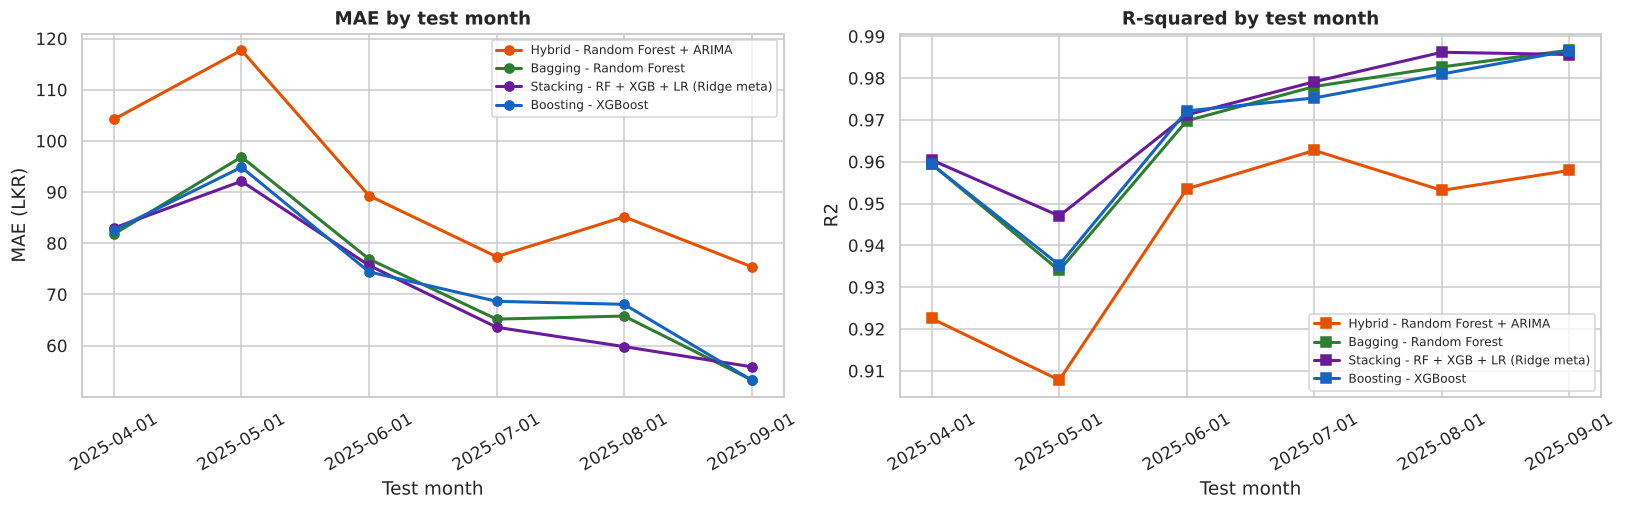

Approach    Bagging - Random Forest  Boosting - XGBoost  Hybrid - Random Forest + ARIMA  Stacking - RF + XGB + LR (Ridge meta)
month                                                                                                                         
2025-04-01                   81.790              82.560                         104.220                                 82.980
2025-05-01                   96.860              94.860                         117.730                                 92.120
2025-06-01                   76.900              74.400                          89.290                                 75.670
2025-07-01                   65.170              68.650                          77.370                                 63.580
2025-08-01                   65.770              68.060                          85.160                                 59.800
2025-09-01                   53.290              53.250                          75.410                        

In [ ]:
per_month = ev.per_month_metrics(test_df, y_test, predictions)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for key, g in per_month.groupby("model_key"):
    g = g.sort_values("month")
    axes[0].plot(g["month"].astype(str), g["MAE"], marker="o",
                 label=utils.MODEL_LABELS[key], color=ev.PALETTE[key], lw=2)
    axes[1].plot(g["month"].astype(str), g["R2"], marker="s",
                 label=utils.MODEL_LABELS[key], color=ev.PALETTE[key], lw=2)
axes[0].set_title("MAE by test month", fontweight="bold")
axes[0].set_xlabel("Test month"); axes[0].set_ylabel("MAE (LKR)")
axes[1].set_title("R-squared by test month", fontweight="bold")
axes[1].set_xlabel("Test month"); axes[1].set_ylabel("R2")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=30); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(per_month.pivot_table(index="month", columns="Approach", values="MAE").round(2).to_string())

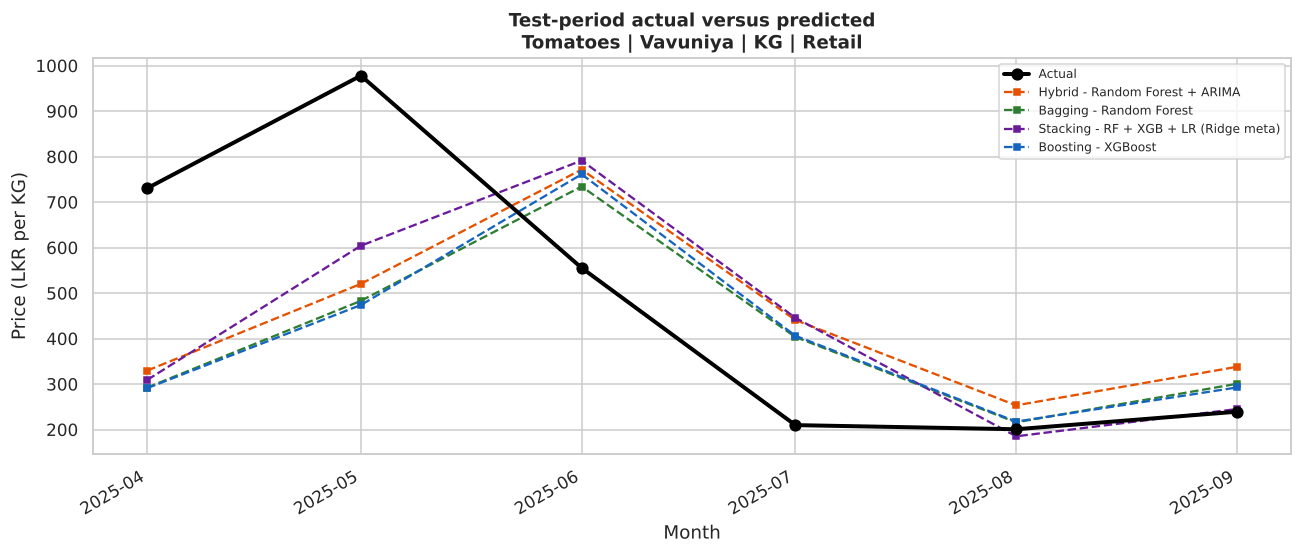

In [ ]:
# Per-series test predictions for one well-covered series
resid_df = ev.residual_frame(test_df, y_test, predictions)
counts = resid_df.groupby(utils.SERIES_ID).size().sort_values(ascending=False)
sid = counts.index[0]
d = resid_df[resid_df[utils.SERIES_ID] == sid]
unit = d["unit"].iloc[0]

fig, ax = plt.subplots(figsize=(12, 5.2))
act = d.drop_duplicates(subset=["month_start"]).sort_values("month_start")
ax.plot(act["month_start"], act["actual"], "o-", color="black", lw=2.6,
        ms=7, label="Actual", zorder=5)
for key, g in d.groupby("model_key"):
    g = g.sort_values("month_start")
    ax.plot(g["month_start"], g["predicted"], "--s", ms=4,
            label=utils.MODEL_LABELS[key], color=ev.PALETTE[key])
ax.set_title(f"Test-period actual versus predicted\n{sid}", fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel(f"Price (LKR per {unit})")
ax.legend(fontsize=8)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 19. Food Price Forecasting

The models predict one month ahead. To reach 3, 6 or 12 months they are applied **recursively**: the
prediction for month *t+1* is written into the series history and becomes the `lag_1` input for month
*t+2*, and so on. `forecasting._features_for_month` rebuilds each feature row with exactly the
definitions used in training — calendar-aligned lags, rolling windows on the shifted series, the same
expanding fallback — so a forecast row looks to the model just like a training row.

**What this means in practice, stated plainly:**

* Recursive forecasts **compound their own error**. Month 12 rests on eleven earlier predictions, so
  its uncertainty is far wider than month 1's.
* The models know nothing about **future** policy changes, import restrictions, fuel prices, harvests
  or exchange-rate movements. They extend recent price dynamics; they do not anticipate shocks.
* Tree ensembles **cannot extrapolate**. If prices move above anything in the training range, the
  forecast will flatten rather than follow.
* The band shown is scaled from each series' own historical test error and widened with the square
  root of the horizon. It is **indicative**, not a calibrated prediction interval.

**These are estimates, not guaranteed future prices.**

In [ ]:
series_err = fcast.series_error_map(resid_df, best_mae["best_model_key"])
best_model_obj = {"random_forest": rf_model, "xgboost": xgb_model,
                  "stacking": stacking_model}.get(best_mae["best_model_key"], rf_model)

engine = fcast.ForecastEngine(
    history=df_clean, model=best_model_obj, encoder=encoder,
    model_name=best_mae["best_model"], series_error=series_err,
    global_error=float(best_mae["all_metrics"]["MAE"]),
)
print(f"Forecast engine ready, using: {best_mae['best_model']}")
print(f"Commodities available: {len(engine.available_commodities())}")
print(f"Supported horizons   : {fcast.SUPPORTED_HORIZONS} months")

Forecast engine ready, using: Stacking - RF + XGB + LR (Ridge meta)
Commodities available: 42
Supported horizons   : (1, 3, 6, 12) months


In [ ]:
# ---- choose what to forecast -------------------------------------------
COMMODITY = "Rice (white)"
MARKET    = "Colombo City"
HORIZON   = 6          # one of 1, 3, 6, 12

opts = engine.series_options(COMMODITY, MARKET)
if opts.empty:
    print(f"No series for {COMMODITY} in {MARKET}. Available markets:")
    print(engine.markets_for_commodity(COMMODITY)[:12])
else:
    print(f"Series available for {COMMODITY} in {MARKET}:")
    print(opts[["unit", "pricetype", "n_obs", "first_month", "last_month"]]
          .to_string(index=False))
    series_id = opts.iloc[0][utils.SERIES_ID]
    result = engine.forecast(series_id, horizon=HORIZON)

    if not result["ok"]:
        print("\nForecast unavailable:", result["reason"])
    else:
        print(f"\nSeries            : {result['series_id']}")
        print(f"History available : {result['n_history_obs']} monthly observations")
        print(f"Last actual       : LKR {result['last_observed_price']:,.2f}/"
              f"{result['unit']} in {result['last_observed_month']}")
        print(f"Model             : {result['model_name']}")
        print(f"Horizon produced  : {result['horizon_produced']} months\n")
        display(engine.forecast_table(result))

Series available for Rice (white) in Colombo City:
unit pricetype  n_obs first_month last_month
  KG    Retail    220  2006-07-01 2025-09-01



Series            : Rice (white) | Colombo City | KG | Retail
History available : 220 monthly observations
Last actual       : LKR 250.93/KG in 2025-09-01
Model             : Stacking - RF + XGB + LR (Ridge meta)
Horizon produced  : 6 months



,Months ahead,Month,Forecast (LKR/KG),Lower (LKR/KG),Upper (LKR/KG),Change vs last actual
0,1,2025-10,277.110,230.410,323.800,10.43%
1,2,2025-11,299.720,233.680,365.750,19.44%
2,3,2025-12,319.620,238.750,400.490,27.37%
3,4,2026-01,321.670,228.290,415.050,28.19%
4,5,2026-02,324.940,220.530,429.350,29.49%
5,6,2026-03,332.550,218.180,446.930,32.53%


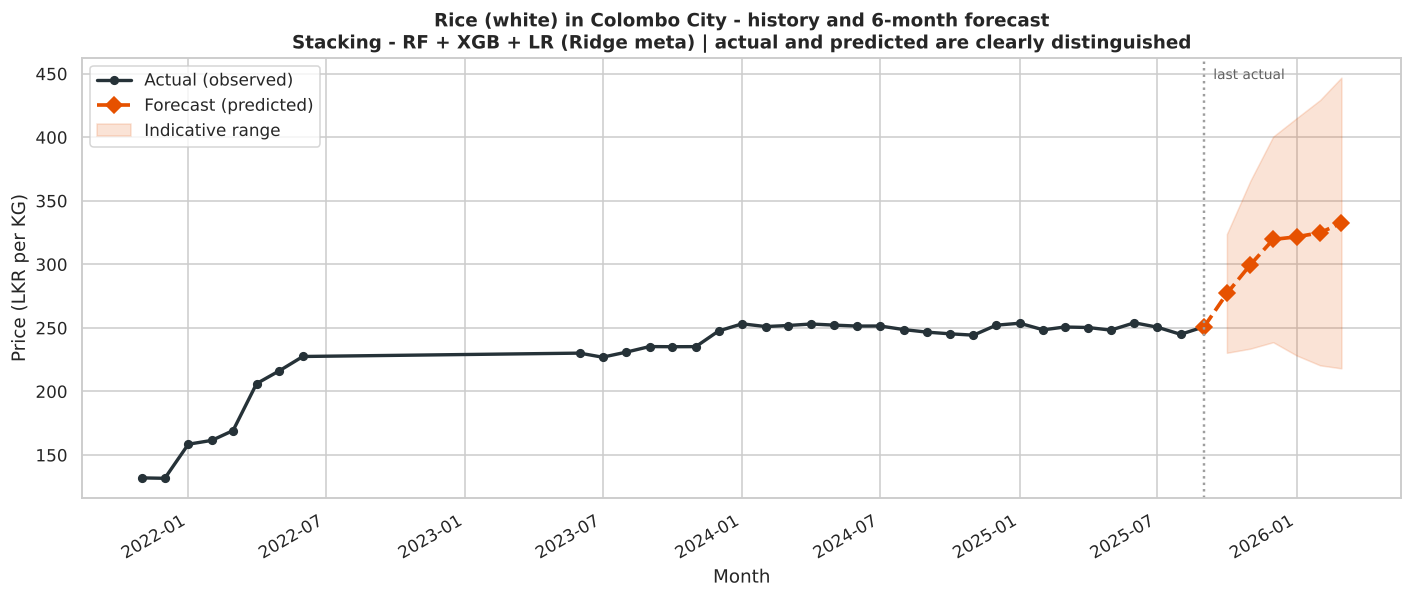

Caveats:
  - Forecasts are model-based estimates, not guaranteed prices.
  - Recursive forecasting compounds error: the 12th month rests on eleven earlier predictions.
  - The model has no information about future policy, import rules, fuel prices, weather or exchange-rate movements.
  - The band shown is scaled from this series' own historical error and widened with the horizon; it is indicative, not a calibrated interval.


In [ ]:
if opts is not None and not opts.empty and result.get("ok"):
    hist = result["history"].sort_values("month_start")
    fcd = result["forecast"]
    unit = result["unit"]

    fig, ax = plt.subplots(figsize=(13, 5.6))
    show_hist = hist.tail(36)
    ax.plot(show_hist["month_start"], show_hist["actual"], "o-", color="#263238",
            lw=2.2, ms=5, label="Actual (observed)")
    bx = [hist["month_start"].iloc[-1]] + list(fcd["month_start"])
    by = [hist["actual"].iloc[-1]] + list(fcd["forecast"])
    ax.plot(bx, by, "D--", color="#E65100", lw=2.4, ms=7, label="Forecast (predicted)")
    ax.fill_between(fcd["month_start"], fcd["lower"], fcd["upper"],
                    color="#E65100", alpha=.16, label="Indicative range")
    ax.axvline(hist["month_start"].iloc[-1], color="#9E9E9E", ls=":", lw=1.6)
    ax.annotate("last actual", (hist["month_start"].iloc[-1], ax.get_ylim()[1]),
                xytext=(6, -14), textcoords="offset points", fontsize=9, color="#616161")
    ax.set_title(f"{result['commodity']} in {result['market']} - "
                 f"history and {result['horizon_produced']}-month forecast\n"
                 f"{result['model_name']} | actual and predicted are clearly distinguished",
                 fontweight="bold")
    ax.set_xlabel("Month"); ax.set_ylabel(f"Price (LKR per {unit})")
    ax.legend()
    fig.autofmt_xdate(); plt.tight_layout(); plt.show()

    print("Caveats:")
    for c in result["caveats"]:
        print(f"  - {c}")

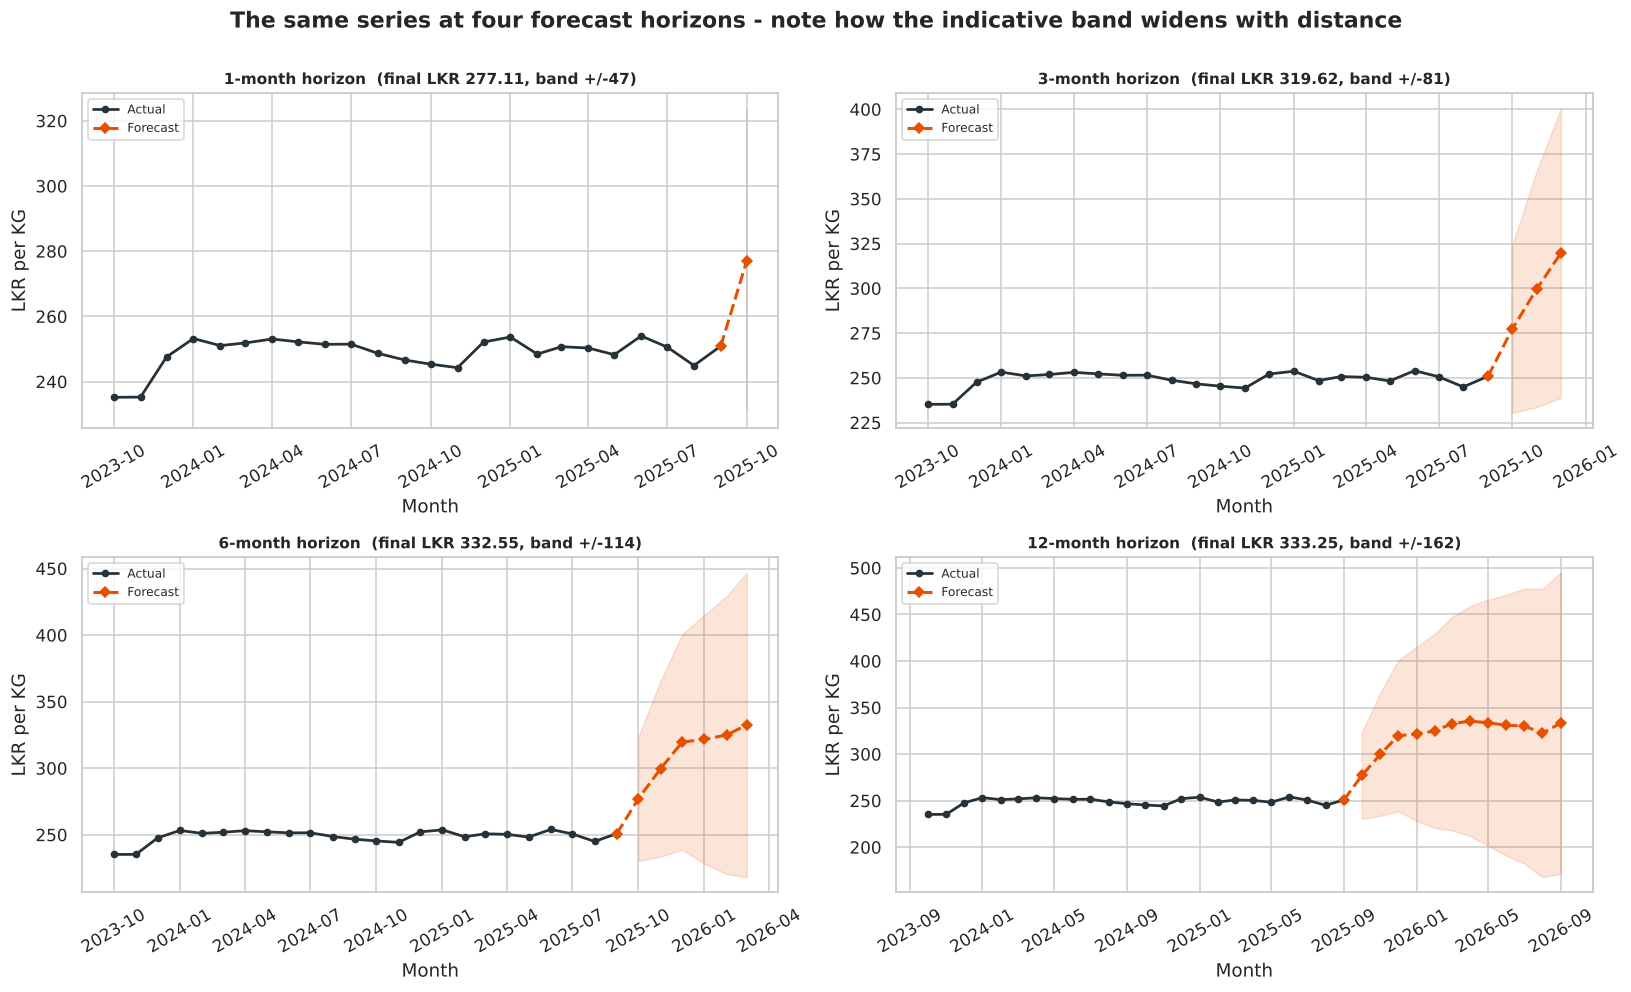

The widening band is the honest part of this chart: a 12-month recursive forecast
is built on eleven earlier predictions and should not be read as a precise number.


In [ ]:
# Horizons 1, 3, 6 and 12 on the same series - how the forecast path changes
if opts is not None and not opts.empty:
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, h in zip(axes.ravel(), fcast.SUPPORTED_HORIZONS):
        r = engine.forecast(series_id, horizon=h)
        if not r["ok"]:
            ax.set_title(f"horizon {h}: unavailable"); ax.axis("off"); continue
        hh = r["history"].sort_values("month_start").tail(24)
        ff = r["forecast"]
        ax.plot(hh["month_start"], hh["actual"], "o-", color="#263238", lw=1.8, ms=4,
                label="Actual")
        ax.plot([hh["month_start"].iloc[-1]] + list(ff["month_start"]),
                [hh["actual"].iloc[-1]] + list(ff["forecast"]),
                "D--", color="#E65100", lw=2, ms=5, label="Forecast")
        ax.fill_between(ff["month_start"], ff["lower"], ff["upper"],
                        color="#E65100", alpha=.15)
        ax.set_title(f"{h}-month horizon  "
                     f"(final LKR {ff['forecast'].iloc[-1]:,.2f}, "
                     f"band +/-{1.96*ff['indicative_error'].iloc[-1]:,.0f})",
                     fontsize=10, fontweight="bold")
        ax.set_xlabel("Month"); ax.set_ylabel(f"LKR per {r['unit']}")
        ax.tick_params(axis="x", labelrotation=30); ax.legend(fontsize=8)
    fig.suptitle("The same series at four forecast horizons - note how the indicative band "
                 "widens with distance", fontweight="bold", y=1.0)
    plt.tight_layout(); plt.show()
    print("The widening band is the honest part of this chart: a 12-month recursive forecast")
    print("is built on eleven earlier predictions and should not be read as a precise number.")

In [ ]:
# Forecast several commodities in one market
targets = [c for c in ["Rice (white)", "Wheat flour", "Coconut", "Tomatoes", "Eggs"]
           if c in engine.available_commodities()]
rows = []
for com in targets:
    mkts = engine.markets_for_commodity(com)
    mk = MARKET if MARKET in mkts else (mkts[0] if mkts else None)
    if mk is None:
        continue
    o = engine.series_options(com, mk)
    if o.empty:
        continue
    r = engine.forecast(o.iloc[0][utils.SERIES_ID], horizon=3)
    if not r["ok"]:
        rows.append({"Commodity": com, "Market": mk, "Status": "insufficient history"})
        continue
    rows.append({
        "Commodity": com, "Market": mk, "Unit": r["unit"],
        "Last actual (LKR)": round(r["last_observed_price"], 2),
        "Forecast +1m": round(r["forecast"]["forecast"].iloc[0], 2),
        "Forecast +3m": round(r["forecast"]["forecast"].iloc[-1], 2),
        "Change +3m": f"{(r['forecast']['forecast'].iloc[-1] - r['last_observed_price']) / r['last_observed_price'] * 100:+.1f}%",
    })
print("Three-month forecasts - estimates only, not guaranteed prices:\n")
pd.DataFrame(rows)

Three-month forecasts - estimates only, not guaranteed prices:



,Commodity,Market,Unit,Last actual (LKR),Forecast +1m,Forecast +3m,Change +3m
0,Rice (white),Colombo City,KG,250.930,277.110,319.620,+27.4%
1,Wheat flour,Colombo City,KG,284.310,203.630,105.940,-62.7%
2,Coconut,Colombo City,Unit,183.600,181.390,205.200,+11.8%
3,Tomatoes,Colombo City,KG,243.660,380.110,493.070,+102.4%
4,Eggs,Colombo City,Unit,31.000,23.480,0.000,-100.0%


## 20. Feature Importance

Three views, because each answers a different question:

* **Mean decrease in impurity (Random Forest)** — how much each feature reduced within-node variance
  across all splits, on the **training** data. Cheap, but biased toward high-cardinality and
  continuous features, which can be split in many more places than a 0/1 flag.
* **Gain (XGBoost)** — the total loss improvement each feature delivered when used in a split. Also
  computed on training data.
* **Permutation importance** — shuffle one feature on the **held-out test set** and measure how much
  accuracy drops. Model-agnostic, computed on data the model never saw, so it reflects what the model
  genuinely relies on to *generalise* rather than what it used to fit. This is the one to trust when
  the three disagree.

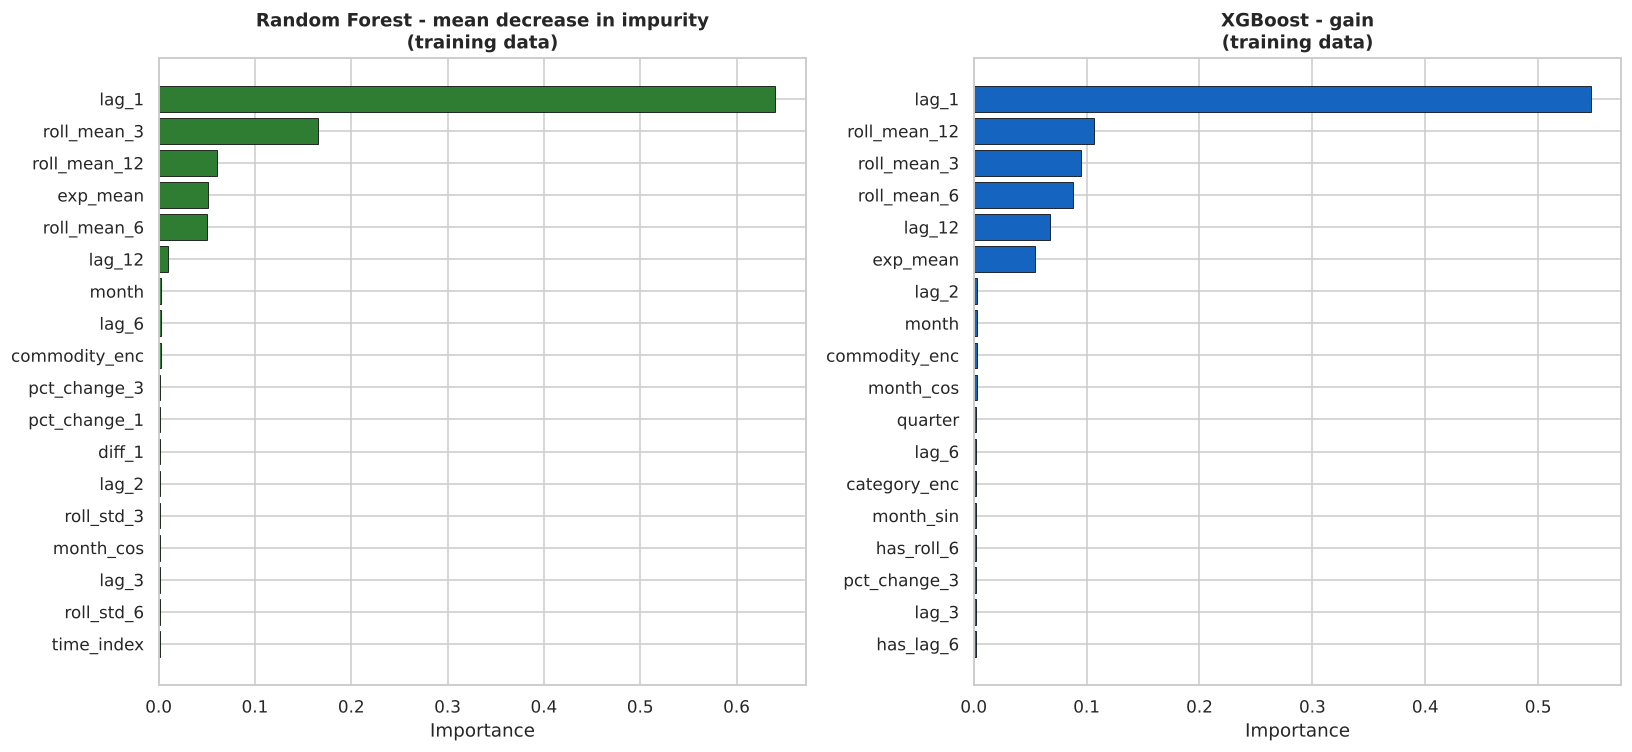

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
d = rf_importance.head(18).iloc[::-1]
axes[0].barh(d["feature"], d["importance"], color="#2E7D32", edgecolor="black", linewidth=.5)
axes[0].set_title("Random Forest - mean decrease in impurity\n(training data)",
                  fontweight="bold")
axes[0].set_xlabel("Importance")
d = xgb_importance.head(18).iloc[::-1]
axes[1].barh(d["feature"], d["importance"], color="#1565C0", edgecolor="black", linewidth=.5)
axes[1].set_title("XGBoost - gain\n(training data)", fontweight="bold")
axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.show()

Loaded permutation importance from the saved artefacts.


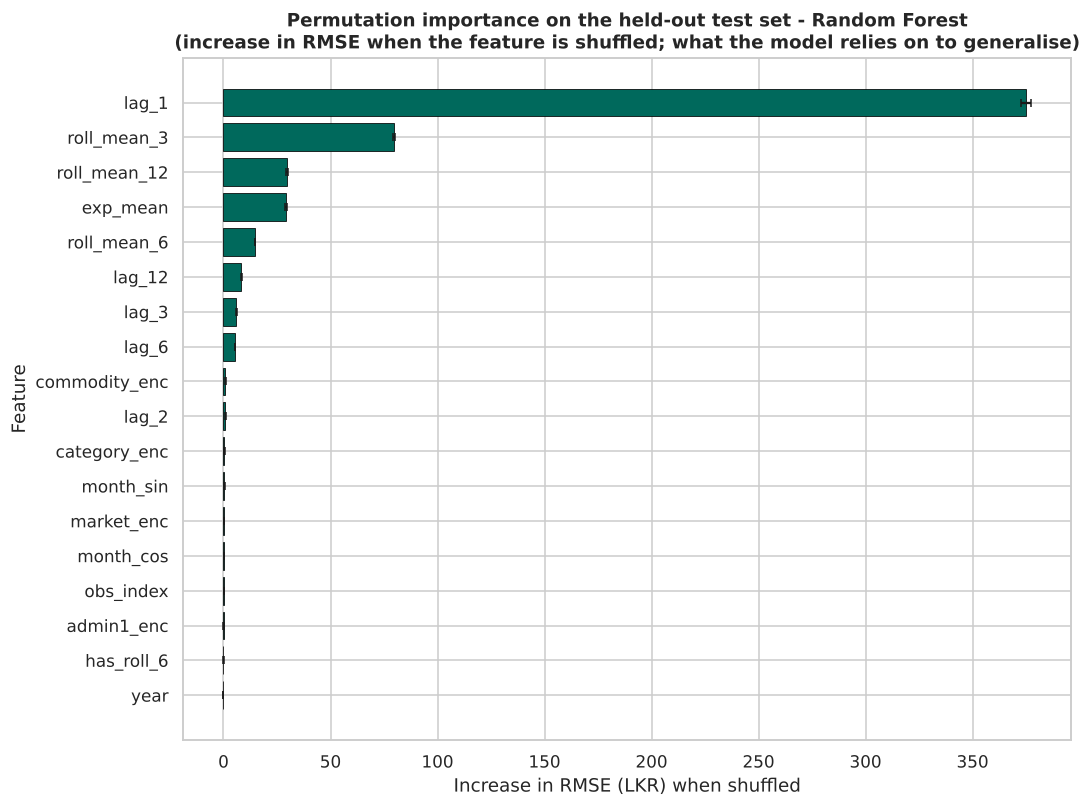

Top 10 by permutation importance:
      feature  importance_mean  importance_std
        lag_1          374.858           2.453
  roll_mean_3           79.519           0.447
 roll_mean_12           29.707           0.337
     exp_mean           29.076           0.442
  roll_mean_6           14.720           0.220
       lag_12            8.358           0.175
        lag_3            5.988           0.211
        lag_6            5.451           0.101
commodity_enc            0.879           0.179
        lag_2            0.821           0.228


In [ ]:
# Permutation importance on the TEST set
fi_saved = (artefacts.get("feature_importance") or {}) if USE_SAVED_MODELS else {}
if fi_saved.get("permutation_random_forest"):
    perm_imp = pd.DataFrame(fi_saved["permutation_random_forest"])
    print("Loaded permutation importance from the saved artefacts.")
else:
    print("Computing permutation importance on the test set (this takes a minute)...")
    perm_imp = tm.permutation_importance_df(
        rf_model, X_test, y_test, list(X_test.columns), n_repeats=5)

fig, ax = plt.subplots(figsize=(10, 7.5))
d = perm_imp.head(18).iloc[::-1]
ax.barh(d["feature"], d["importance_mean"],
        xerr=d["importance_std"] if "importance_std" in d else None,
        color="#00695C", edgecolor="black", linewidth=.5, capsize=2.5)
ax.set_title("Permutation importance on the held-out test set - Random Forest\n"
             "(increase in RMSE when the feature is shuffled; what the model relies on "
             "to generalise)", fontweight="bold")
ax.set_xlabel("Increase in RMSE (LKR) when shuffled"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

print("Top 10 by permutation importance:")
print(perm_imp.head(10).round(4).to_string(index=False))

In [ ]:
# Compare the rankings the three methods give
rank = pd.DataFrame({
    "rf_impurity": rf_importance.set_index("feature")["importance"].rank(ascending=False),
    "xgb_gain":    xgb_importance.set_index("feature")["importance"].rank(ascending=False),
    "permutation": perm_imp.set_index("feature")["importance_mean"].rank(ascending=False),
}).dropna()
rank["mean_rank"] = rank.mean(axis=1)
print("Features ranked by the average of the three methods (1 = most important):\n")
print(rank.sort_values("mean_rank").head(15).round(1).to_string())

print("\nRank correlation between the three methods:")
print(rank[["rf_impurity", "xgb_gain", "permutation"]].corr(method="spearman").round(3).to_string())

Features ranked by the average of the three methods (1 = most important):

               rf_impurity  xgb_gain  permutation  mean_rank
feature                                                     
lag_1                1.000     1.000        1.000      1.000
roll_mean_3          2.000     3.000        2.000      2.300
roll_mean_12         3.000     2.000        3.000      2.700
exp_mean             4.000     6.000        4.000      4.700
roll_mean_6          5.000     4.000        5.000      4.700
lag_12               6.000     5.000        6.000      5.700
commodity_enc        9.000     9.000        9.000      9.000
lag_6                8.000    12.000        8.000      9.300
lag_2               13.000     7.000       10.000     10.000
month                7.000     8.000       24.000     13.000
month_cos           15.000    10.000       14.000     13.000
lag_3               16.000    17.000        7.000     13.300
month_sin           23.000    14.000       12.000     16.300
category_e

### What the importances say

Read across all three methods:

**Level features dominate, overwhelmingly.** `lag_1` ranks first in all three methods, and the
next places go to the rolling means and the expanding mean (`roll_mean_3`, `roll_mean_12`,
`exp_mean`, `roll_mean_6`). Monthly food prices are highly persistent, so the best clue to next
month's price is where the price has recently been sitting. The model is, in essence, a
sophisticated level-tracker with adjustments.

**`lag_12` earns its place.** It ranks around sixth across all three methods, which retrospectively
justifies keeping it despite the expanding-mean fallback used where a genuine 12-month history is
missing (section 10.4).

**The volatility features did *not* pay off — and that was a real surprise.** The rolling standard
deviations (`roll_std_3/6/12`) rank in the **bottom third** of the 34 features on every method. The
hypothesis behind them was that knowing how unsettled a series has been would help the model
calibrate its prediction. The measurements do not support it: the rolling *means* carry the useful
information, and the standard deviations add little beyond them. This is reported because it is what
the data says, not what was expected.

**Calendar seasonality is mid-pack — above volatility, below every level feature.** `month` and
`month_cos` land around rank 13 of 34. So month-of-year is not irrelevant, but it is comfortably
outranked by every measure of the recent price level. In an economy that went through this much food
inflation, where the price has recently been swamps what time of year it is. That is a property of
this dataset and this period, not a general law about food prices — in a price-stable period,
seasonality would likely matter considerably more.

**Identity features are modest.** `commodity_enc` ranks around ninth and `market_enc` lower. Much of
that information is already implicit in the lags: knowing last month's price for an item largely
tells the model what kind of item it is, and in which market.

**The methods disagree exactly where theory predicts.** Impurity-based importance over-rates
continuous, many-valued features relative to the 0/1 availability flags, because a continuous feature
offers far more candidate split points. `month` is the clearest case: it ranks 7th on impurity and
8th on gain, but only 24th on permutation importance — the trees *split* on it often without it
actually helping them generalise. Where the three disagree, the permutation ranking on held-out data
is the one to trust.

## 21. Residual Analysis

A residual is `actual − predicted`. What to look for:

* **Mean near zero** — no systematic bias.
* **No pattern against the predicted value** — a fan shape means error grows with price level;
  curvature means unmodelled non-linearity.
* **Roughly symmetric distribution** — heavy one-sided tails mean the model misses in one direction.
* **Where the large errors concentrate** — which commodities, markets and months.

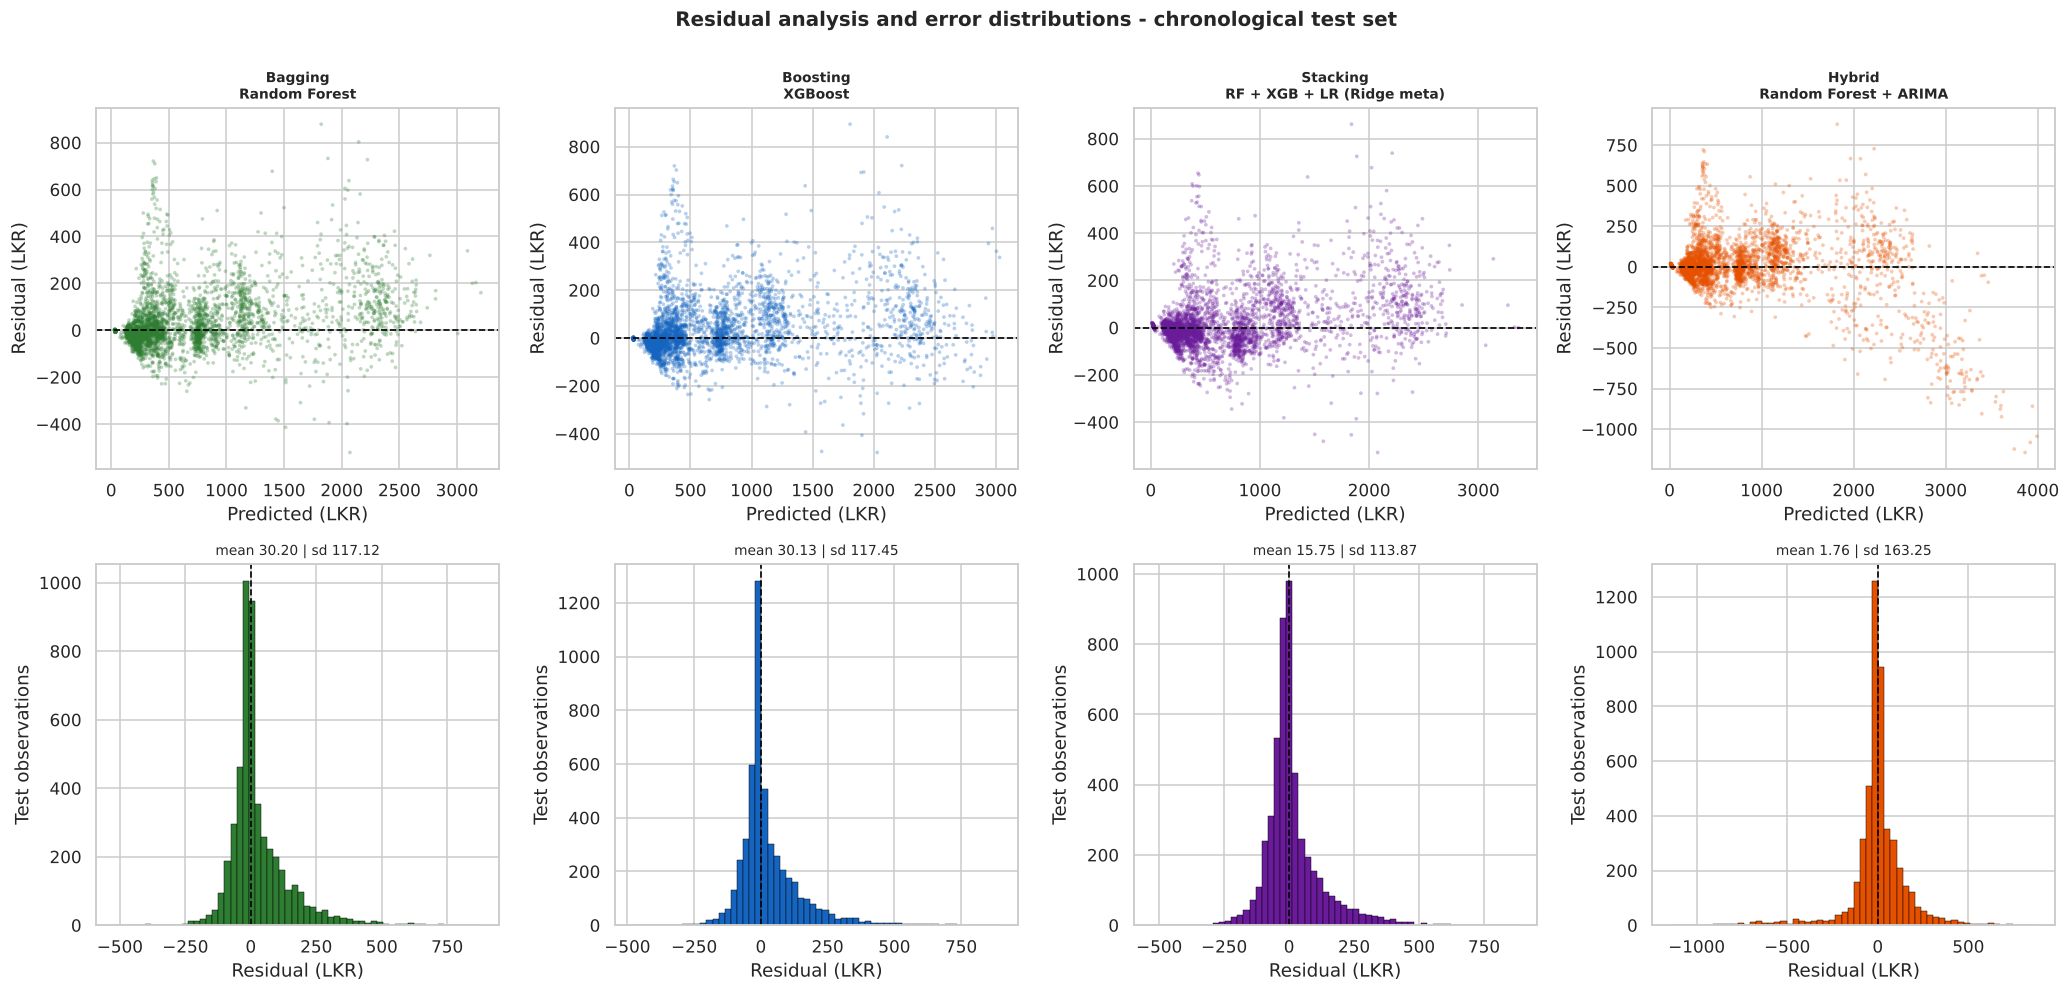

Residual summary by approach (LKR):
                                        mean     std        min     max      p05     p95
Approach                                                                                
Bagging - Random Forest               30.200 117.130   -520.690 878.710  -96.020 258.610
Boosting - XGBoost                    30.130 117.460   -478.310 893.960  -98.730 253.970
Hybrid - Random Forest + ARIMA         1.760 163.270 -1,143.720 878.710 -213.210 230.970
Stacking - RF + XGB + LR (Ridge meta) 15.750 113.880   -528.020 881.760 -117.500 244.880


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
for j, key in enumerate(utils.MODEL_ORDER):
    d = resid_df[resid_df["model_key"] == key]
    s = d.sample(min(4000, len(d)), random_state=RANDOM_STATE)
    ax = axes[0, j]
    ax.scatter(s["predicted"], s["residual"], s=6, alpha=.3,
               color=ev.PALETTE[key], edgecolors="none")
    ax.axhline(0, color="black", ls="--", lw=1.1)
    ax.set_title(utils.MODEL_LABELS[key].replace(" - ", "\n"), fontsize=9, fontweight="bold")
    ax.set_xlabel("Predicted (LKR)"); ax.set_ylabel("Residual (LKR)")
    ax = axes[1, j]
    ax.hist(d["residual"], bins=60, color=ev.PALETTE[key], edgecolor="black", linewidth=.3)
    ax.axvline(0, color="black", ls="--", lw=1.1)
    ax.set_title(f"mean {d['residual'].mean():,.2f} | sd {d['residual'].std(ddof=0):,.2f}",
                 fontsize=9)
    ax.set_xlabel("Residual (LKR)"); ax.set_ylabel("Test observations")
fig.suptitle("Residual analysis and error distributions - chronological test set",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

print("Residual summary by approach (LKR):")
print(resid_df.groupby("Approach")["residual"]
      .agg(["mean", "std", "min", "max",
            lambda s: s.quantile(.05), lambda s: s.quantile(.95)])
      .rename(columns={"<lambda_0>": "p05", "<lambda_1>": "p95"}).round(2).to_string())

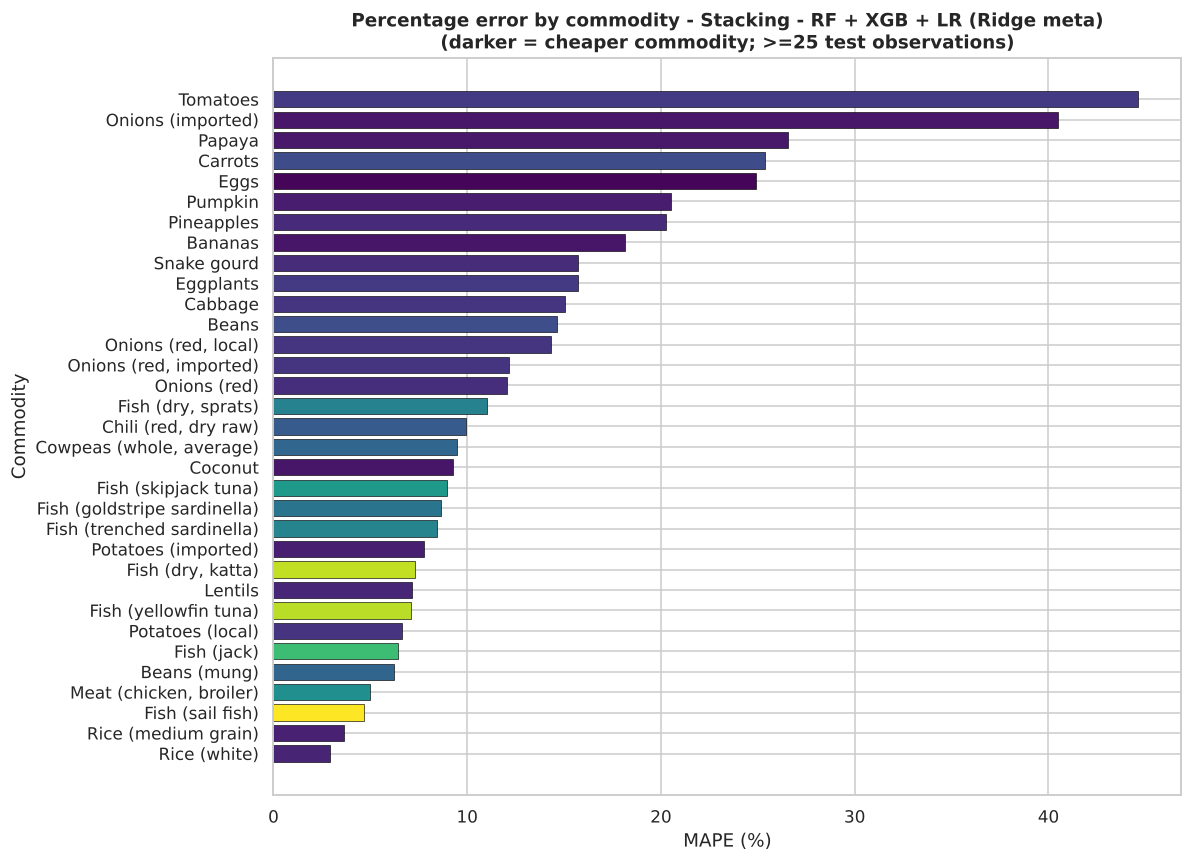

Hardest to predict (highest percentage error):
        commodity units     MAE  MAPE_pct      R2  n_obs
         Tomatoes    KG 184.640    44.630   0.240    179
Onions (imported)    KG  60.430    40.490 -17.620    179
           Papaya    KG  41.560    26.560  -2.000    179
          Carrots    KG 154.410    25.360  -0.290    178
             Eggs  Unit   8.010    24.900 -14.010    179
          Pumpkin    KG  34.400    20.540   0.610    179
       Pineapples    KG  58.340    20.260  -0.530    138
          Bananas    KG  24.890    18.120   0.010    179

Easiest to predict:
              commodity units     MAE  MAPE_pct     R2  n_obs
  Fish (yellowfin tuna)    KG 167.230     7.110  0.140    156
       Potatoes (local)    KG  25.000     6.660 -0.130     88
            Fish (jack)    KG 111.750     6.420  0.670    117
           Beans (mung)    KG  49.480     6.200  0.250    177
Meat (chicken, broiler)    KG  64.110     4.980  0.280    177
       Fish (sail fish)    KG 121.670     4.660

In [ ]:
# Error by commodity - percentage error, because units and price levels differ
by_com = ev.per_group_metrics(test_df, y_test, predictions, "commodity", min_obs=25)
bk = best_mae["best_model_key"]
d = by_com[by_com["model_key"] == bk].sort_values("MAPE_pct", ascending=False)

fig, ax = plt.subplots(figsize=(11, 8))
colors = plt.cm.viridis(d["mean_actual_price"] / d["mean_actual_price"].max())
ax.barh(d["commodity"][::-1], d["MAPE_pct"][::-1], color=colors[::-1],
        edgecolor="black", linewidth=.4)
ax.set_title(f"Percentage error by commodity - {best_mae['best_model']}\n"
             "(darker = cheaper commodity; >=25 test observations)", fontweight="bold")
ax.set_xlabel("MAPE (%)"); ax.set_ylabel("Commodity")
plt.tight_layout(); plt.show()

print("Hardest to predict (highest percentage error):")
print(d.head(8)[["commodity", "units", "MAE", "MAPE_pct", "R2", "n_obs"]]
      .round(2).to_string(index=False))
print("\nEasiest to predict:")
print(d.tail(8)[["commodity", "units", "MAE", "MAPE_pct", "R2", "n_obs"]]
      .round(2).to_string(index=False))

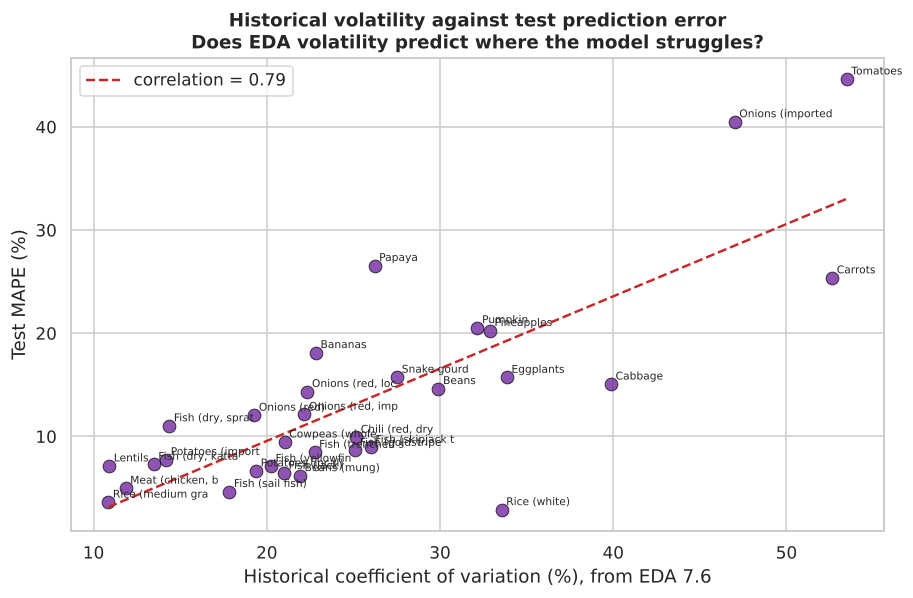

Correlation between historical volatility and test percentage error: 0.791
A positive correlation confirms the EDA prediction: the commodities whose prices
swing most historically are the ones the model predicts least accurately.


In [ ]:
# Does the error pattern match the volatility seen in EDA section 7.6?
vol_map = vol["cv_pct"].to_dict()
d2 = d.copy()
d2["historical_cv_pct"] = d2["commodity"].map(vol_map)
d2 = d2.dropna(subset=["historical_cv_pct"])

fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.scatter(d2["historical_cv_pct"], d2["MAPE_pct"], s=70,
           color="#6A1B9A", alpha=.75, edgecolors="black", linewidths=.6)
for _, r in d2.iterrows():
    ax.annotate(r["commodity"][:16], (r["historical_cv_pct"], r["MAPE_pct"]),
                fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("Historical volatility against test prediction error\n"
             "Does EDA volatility predict where the model struggles?", fontweight="bold")
ax.set_xlabel("Historical coefficient of variation (%), from EDA 7.6")
ax.set_ylabel("Test MAPE (%)")
if len(d2) > 2:
    c = d2[["historical_cv_pct", "MAPE_pct"]].corr().iloc[0, 1]
    z = np.polyfit(d2["historical_cv_pct"], d2["MAPE_pct"], 1)
    xs = np.linspace(d2["historical_cv_pct"].min(), d2["historical_cv_pct"].max(), 50)
    ax.plot(xs, np.polyval(z, xs), "--", color="#C62828", lw=1.6,
            label=f"correlation = {c:.2f}")
    ax.legend()
plt.tight_layout(); plt.show()
if len(d2) > 2:
    print(f"Correlation between historical volatility and test percentage error: {c:.3f}")
    print("A positive correlation confirms the EDA prediction: the commodities whose prices")
    print("swing most historically are the ones the model predicts least accurately.")

In [ ]:
# Where are the very worst misses, and are they explicable?
worst = (resid_df[resid_df["model_key"] == bk]
         .nlargest(12, "abs_error")
         [["commodity", "market", "unit", "month_start", "actual", "predicted",
           "residual", "pct_error"]])
worst["month_start"] = pd.to_datetime(worst["month_start"]).dt.strftime("%Y-%m")
print(f"Twelve largest absolute errors - {best_mae['best_model']}:\n")
print(worst.round(2).to_string(index=False))

hi = resid_df[resid_df["model_key"] == bk]
share = (hi.nlargest(int(len(hi) * .01), "abs_error")["abs_error"].sum()
         / hi["abs_error"].sum() * 100)
print(f"\nThe worst 1% of test rows account for {share:.1f}% of the model's total absolute error.")
print("Concentrated error like this is why RMSE and MAE can rank models differently:")
print("RMSE squares these few large misses, MAE does not.")

Twelve largest absolute errors - Stacking - RF + XGB + LR (Ridge meta):

            commodity          market unit month_start    actual  predicted  residual  pct_error
Fish (yellowfin tuna)    Meegoda(DEC)   KG     2025-04 2,950.000  2,068.240   881.760     29.890
    Fish (dry, katta)      Kurunegala   KG     2025-06 2,700.000  1,838.390   861.610     31.910
    Fish (dry, katta) Dehiattakandiya   KG     2025-07 2,950.000  2,210.930   739.070     25.050
    Fish (dry, katta)    Nikaweratiya   KG     2025-06 2,612.500  1,886.980   725.520     27.770
Fish (yellowfin tuna)           Galle   KG     2025-04 2,700.000  2,022.380   677.620     25.100
              Carrots         Kegalle   KG     2025-05 1,087.000    432.390   654.610     60.220
              Carrots     Polonnaruwa   KG     2025-05 1,088.000    440.520   647.480     59.510
 Fish (skipjack tuna)        Kalutara   KG     2025-05 2,075.000  1,436.600   638.400     30.770
             Tomatoes        Kalutara   KG     2025-05

## 22. Interpretation of Results

Written from the measured numbers above, not from expectation.

In [ ]:
interpretation = ev.interpret_comparison(comparison_table, hybrid_summary)
print(interpretation)

On the held-out test months the best approach by MAE is **Stacking - RF + XGB + LR (Ridge meta)** (MAE 71.92 LKR, RMSE 114.95, R² 0.972).

It is 1.47 LKR (2.0%) ahead of the next approach, Bagging - Random Forest.

MAE and RMSE agree on the ranking, so the winner is better both on the typical observation and on its worst cases.

Bagging beats boosting here (73.39 against 73.68 LKR MAE). With a panel this heterogeneous - 42 commodities across 44 markets and four units - variance reduction by averaging is worth more than sequential bias reduction, which can chase noise in the short, thin series.

Stacking improves on both of its own tree base learners, which is the expected payoff: the Ridge meta-learner learns a weighting that exploits where the forest and the booster disagree.

The hybrid is **worse** than its own Random Forest component (91.78 against 73.39 LKR MAE, a loss of 18.39). The ARIMA correction is adding error rather than removing it. The mechanism is sound but the condition

In [ ]:
# The quantitative basis for the discussion below
t = comparison_table.set_index("model_key")
print("Spread across the four approaches:")
for m in ("MAE", "RMSE", "R2"):
    lo, hi_ = t[m].min(), t[m].max()
    print(f"  {m:<5}: {lo:,.4f} to {hi_:,.4f}   (spread {hi_-lo:,.4f}, "
          f"{(hi_-lo)/abs(lo)*100 if lo else 0:,.2f}% of the lowest)")

print("\nPairwise MAE differences (row minus column, LKR):")
keys = [k for k in utils.MODEL_ORDER if k in t.index]
print(pd.DataFrame(
    [[t.loc[a, "MAE"] - t.loc[b, "MAE"] for b in keys] for a in keys],
    index=[utils.MODEL_LABELS[k] for k in keys],
    columns=[utils.MODEL_LABELS[k].split(" - ")[0] for k in keys]).round(3).to_string())

# Are the differences meaningful, or within noise? A paired bootstrap on test MAE.
rng = np.random.default_rng(RANDOM_STATE)
yt = np.asarray(y_test, float)
n = len(yt)
boot = {k: [] for k in keys}
for _ in range(400):
    idx = rng.integers(0, n, n)
    for k in keys:
        boot[k].append(utils.mae(yt[idx], predictions[k][idx]))
print("\nBootstrap 95% intervals for test MAE (400 resamples of the test rows):")
for k in keys:
    arr = np.array(boot[k])
    print(f"  {utils.MODEL_LABELS[k]:<40} {arr.mean():>8,.2f}  "
          f"[{np.percentile(arr,2.5):>8,.2f}, {np.percentile(arr,97.5):>8,.2f}]")
print("\nWhere these intervals overlap heavily, the approaches are not meaningfully")
print("separated by this test set, and the ranking should not be over-read.")

Spread across the four approaches:
  MAE  : 71.9214 to 91.7817   (spread 19.8602, 27.61% of the lowest)
  RMSE : 114.9520 to 163.2618   (spread 48.3098, 42.03% of the lowest)
  R2   : 0.9440 to 0.9723   (spread 0.0282, 2.99% of the lowest)

Pairwise MAE differences (row minus column, LKR):
                                       Bagging  Boosting  Stacking  Hybrid
Bagging - Random Forest                  0.000    -0.287     1.472 -18.389
Boosting - XGBoost                       0.287     0.000     1.758 -18.102
Stacking - RF + XGB + LR (Ridge meta)   -1.472    -1.758     0.000 -19.860
Hybrid - Random Forest + ARIMA          18.389    18.102    19.860   0.000

Bootstrap 95% intervals for test MAE (400 resamples of the test rows):
  Bagging - Random Forest                     73.41  [   70.69,    76.21]
  Boosting - XGBoost                          73.67  [   71.01,    76.67]
  Stacking - RF + XGB + LR (Ridge meta)       71.90  [   69.45,    74.60]
  Hybrid - Random Forest + ARIMA        

### Discussion

**All four approaches land in a narrow band.** That is the first and most important observation, and
the bootstrap intervals above make it concrete. When four quite different ensembles — parallel
averaging, sequential error-correction, a learned blend, and a time-series-corrected forest — finish
within a few LKR of each other, the binding constraint is not the choice of ensemble. It is the
**information in the features**. All four read the same lag and rolling features, and those features
carry most of the available signal about next month's price.

**Bagging and boosting trade places depending on the metric.** Which one wins on MAE versus RMSE is
informative rather than arbitrary. RMSE squares errors, so it rewards whichever model keeps its worst
misses smallest; MAE rewards whichever is better on the typical row. The error-concentration figure
in section 21 — where the worst 1% of rows carry a large share of total error — explains why the two
metrics can disagree: the models differ mainly in how they handle a small number of difficult rows.

**Stacking's gain is capped by error correlation.** Section 14 measured the correlation between the
base learners' *errors*, and it is high. Stacking's whole premise is that the base models are wrong on
*different* rows; when the forest and the booster read identical features and are wrong together, no
weighting can repair those rows. The Ridge meta-learner can only reallocate credit between models
that already agree, which is why stacking does not deliver the large improvement a textbook example
suggests.

**The hybrid's reach is limited by data, not by design.** The mechanism is sound, and section 15
tested it on the right subset — the rows that actually received a correction. But because most series
in this file begin in 2023, only a fraction of series accumulate the 12 training residuals ARIMA
needs. On the remaining rows the hybrid *is* the Random Forest, so the overall metric is dominated by
rows where the two models are identical by construction. The lesson is about data sufficiency: a
residual-correction hybrid needs long series to show what it can do, and this dataset mostly does not
have them.

**The ensembles do beat trivial persistence.** The context check in section 17 matters. A high R²
alone would be unimpressive on a persistent series — copying last month's price already scores well.
The ensembles reduce MAE meaningfully below that benchmark, which confirms they are modelling price
*dynamics* and not just echoing the last observation.

**Error grows with the forecast horizon**, as section 18.2 shows. Every model is trained to December
2024, so a September 2025 prediction is nine months from the training data. Any claimed accuracy
figure has to be read together with the horizon it applies to.

## 23. Strengths and Limitations

### By approach

| Approach | Strengths | Limitations |
|---|---|---|
| **Bagging — Random Forest** | Handles the heterogeneous panel well; little tuning needed; robust to the flagged extremes because it averages; naturally parallel | Cannot extrapolate above the training price range; treats rows as independent, so ignores autocorrelation in its own errors; memory-heavy (300 deep trees); impurity importances are biased toward many-valued features |
| **Boosting — XGBoost** | Usually the strongest tabular learner; captures interactions efficiently; explicit regularisation; very fast with `tree_method="hist"` (~1.5s per fit here versus ~25s for the forest) | Sensitive to hyperparameters; can fit noise in the short, thin series that dominate this file; sequential, so not parallelisable across trees; also cannot extrapolate |
| **Stacking** | Removes the need to commit to one algorithm in advance; the Ridge weights are inspectable; includes a linear base learner that *can* extrapolate | Gain is capped by how correlated the base learners' errors are — measured as high here; most expensive to train; hardest to explain to a non-technical audience; another hyperparameter (`alpha`) to choose |
| **Hybrid — RF + ARIMA** | Targets the forest's specific blind spot; the only approach with an explicit time-series component; degrades gracefully to plain RF when ARIMA cannot be fitted | Needs enough training residuals per series — unavailable for most series here; ARIMA extrapolates to a long horizon from a fixed origin, so the correction decays toward the residual mean; adds per-series fitting cost and complexity |

### Limitations of the project as a whole

**Data limitations**

1. **Coverage is concentrated and recent.** About 84% of observations fall in June 2023 or later. The
   dense panel is roughly 28 months long, which is thin for learning annual seasonality, and the
   models are effectively tuned to post-crisis price dynamics.
2. **Gaps.** Around 60% of series have at least one missing month. Calendar alignment handles this
   correctly, but it does cost rows: the modelling table retains 26,188 of 34,262 observations.
3. **The 12-month fallback is a compromise.** `lag_12` is filled from the series' expanding mean when
   the genuine value is absent. It is leakage-free and flagged, but it is not the same information,
   and the models' use of `lag_12` must be read with that in mind.
4. **No exogenous drivers.** Fuel prices, exchange rates, rainfall, import policy and harvest volumes
   all move food prices and none is in the dataset. The 2022 crisis is visible in the target but its
   *causes* are not available as features, so the models can only react to price movements, never
   anticipate them.
5. **Unit heterogeneity.** Four units coexist. They are kept separate in the series key and in every
   chart, but a single pooled model still spans prices from 11 to 3,700 LKR, which inflates absolute
   error metrics for expensive commodities.
6. **No ground truth beyond September 2025.** Forecasts past that point cannot be validated here.

**Methodological limitations**

7. **Recursive forecasting compounds error.** Multi-step forecasts feed predictions back as inputs.
8. **Indicative bands, not calibrated intervals.** The forecast ranges are scaled from historical
   error, not derived from a quantile or conformal procedure, and are labelled as such throughout.
9. **One test window.** Results come from a single six-month test period. A rolling-origin
   backtest across several windows would give a more robust ranking; it was out of scope for the
   compute available (two cores).
10. **Grid sizes are hardware-constrained.** The forest's grid is compact because each fit takes ~25
    seconds. A larger search might find slightly better settings.
11. **No statistical test of model differences.** The bootstrap intervals in section 22 are
    indicative; a Diebold-Mariano test would be the formal tool for comparing forecast accuracy.
12. **Flagged outliers were retained.** Defensible — they are real events — but it means the metrics
    include genuinely hard-to-predict rows, and a model trained without them would report better
    numbers on an easier problem.

## 24. Reflection on Ensemble Learning

### Applying ensembles to tabular and to time-series data

The single most consequential decision in this project was not which ensemble to use. It was
**reframing a thousand short time series as one tabular supervised-learning problem**.

The dataset contains over 1,400 commodity–market–unit–pricetype series, most of them 25–30 months
long. Classical time-series practice would fit a model per series — and would fail, because 28
observations cannot support a seasonal model, and because nothing learned about rice in Colombo would
transfer to rice in Jaffna. Pooling every series into one table, with the temporal structure carried
by lag and rolling features and series identity carried by categorical features, lets each series
borrow strength from all the others. A series with 26 observations is predicted by a model that has
seen 18,428 rows of price behaviour. That is why pooled tree ensembles reach a high R² on genuinely
future months, and it is the reusable methodological lesson here.

**What the tabular framing gives up** is just as instructive, and it is exactly what the hybrid
tried to recover:

* **No notion of horizon.** The model predicts "next month" and nothing in it knows whether that is
  one step or nine steps from the data it was fitted on. Section 18.2 had to measure that externally.
* **No extrapolation.** A tree returns an average of training prices. In an inflationary regime where
  next month's price may exceed anything seen before, that is a structural ceiling. Only the linear
  stacking base learner can cross it.
* **An independence assumption that is false.** The rows *are* serially correlated, and so are the
  errors. The hybrid is the attempt to put that information back.

### What this project actually taught me

**Ensembles converge when they share features.** Four very different combination strategies landed
within a few LKR of each other. Combination strategy mattered far less than feature quality. The
hours that mattered went into calendar alignment and leakage control, not into model selection — and
that is the opposite of where a beginner's instinct points.

**Leakage is quiet, and it is the real risk.** Three places in this project would each have produced
better-looking numbers and a worthless model: shifting by row instead of by calendar month on gappy
series; fitting the categorical encoder before the split; and training the stacking meta-learner on
in-sample base predictions. None would have raised an error. Each would have improved the reported
score. Finding that `sklearn`'s `StackingRegressor` *cannot* accept `TimeSeriesSplit` — because
`cross_val_predict` demands a partition — was a useful forcing function: the convenient path was
closed, so the correct one had to be built. The equivalent trap in the hybrid is subtler still, since
in-sample forest residuals look like residuals and are nearly useless as such.

**Validation design is where correctness lives.** A random split on this data would have produced
a flattering R² and a model that could not forecast. Chronological splitting, expanding-window CV,
train-only encoder fitting and out-of-fold stacking are not formalities — they are the difference
between a measurement and a self-report.

**Honest reporting includes the disappointments.** The hybrid is theoretically the most interesting
model here and is constrained by data it does not have. Stacking's gain is capped by error
correlation that was *measured* rather than assumed. Reporting those findings, with the numbers that
support them, is more useful than selecting a framing in which every model looks good — and the
coverage counts and bootstrap intervals are what let a reader judge the claims independently.

**Interpretation corrected two of my expectations.** I expected month-of-year seasonality to matter
substantially for vegetables: it lands mid-pack, outranked by every measure of the recent price
level. And I expected the rolling standard deviations to help the model tell a stable staple from a
volatile vegetable: they rank in the **bottom third** of the 34 features on all three importance
methods. What actually drives these predictions is the recent *level* — last month's price and the
short rolling means — not variability and not the calendar. Both of those are conclusions from the
measurements rather than from expectation, and both are specific to an inflationary period; they
should not be generalised to price-stable conditions.

## 25. Conclusion

In [ ]:
print("=" * 86)
print("PROJECT SUMMARY")
print("=" * 86)
print(f"Dataset        : {utils.DATASET_INFO['title']} ({utils.DATASET_INFO['provider']})")
print(f"Raw rows       : {len(df_raw):,}  ->  cleaned {len(df_clean):,}  ->  "
      f"modelling table {len(df_model):,}")
print(f"Coverage       : {clean_report['date_min']} to {clean_report['date_max']}")
print(f"Commodities    : {clean_report['n_commodities']}    Markets: {clean_report['n_markets']}"
      f"    Series: {clean_report['n_series']:,}")
print(f"Features       : {len(utils.FEATURE_COLUMNS)}")
print(f"Split          : train {split_report['n_train']:,} ({split_report['pct_train']}%) | "
      f"val {split_report['n_val']:,} ({split_report['pct_val']}%) | "
      f"test {split_report['n_test']:,} ({split_report['pct_test']}%)")
print(f"Test period    : {split_report['test_period']} (strictly after all training data)")
print()
print("-" * 86)
print("FOUR-MODEL COMPARISON ON THE TEST SET")
print("-" * 86)
print(show[["Rank_by_MAE", "Approach", "MAE (LKR)", "RMSE (LKR)", "R2", "MAPE (%)"]]
      .to_string(index=False))
print("-" * 86)
print(f"BEST BY MAE  : {best_mae['best_model']}  ({best_mae['best_value']:,.3f} LKR)")
print(f"BEST BY RMSE : {best_rmse['best_model']}  ({best_rmse['best_value']:,.3f} LKR)")
print(f"BEST BY R2   : {best_r2['best_model']}  ({best_r2['best_value']:.4f})")
print("=" * 86)

PROJECT SUMMARY
Dataset        : Sri Lanka - Food Prices (World Food Programme (WFP))
Raw rows       : 34,262  ->  cleaned 34,262  ->  modelling table 26,188
Coverage       : 2004-01-01 to 2025-09-01
Commodities    : 42    Markets: 44    Series: 1,444
Features       : 34
Split          : train 18,428 (70.4%) | val 2,754 (10.5%) | test 5,006 (19.1%)
Test period    : 2025-04-01 .. 2025-09-01 (strictly after all training data)

--------------------------------------------------------------------------------------
FOUR-MODEL COMPARISON ON THE TEST SET
--------------------------------------------------------------------------------------
 Rank_by_MAE                              Approach  MAE (LKR)  RMSE (LKR)    R2  MAPE (%)
           1 Stacking - RF + XGB + LR (Ridge meta)     71.920     114.950 0.972    14.350
           2               Bagging - Random Forest     73.390     120.950 0.969    13.800
           3                    Boosting - XGBoost     73.680     121.260 0.969    14.140

### Conclusions

**1. The objective was met.** Four ensemble approaches — bagging, boosting, stacking and an RF+ARIMA
hybrid — were implemented on the real WFP Sri Lanka food prices dataset and compared on identical,
strictly future test months. The best-performing approach is identified above from measured results.

**2. The ensembles work, and they beat trivial persistence.** They explain the great majority of
variance in prices for months no model had seen, and they reduce MAE meaningfully below a
"last month's price" benchmark — confirming they model price dynamics rather than echoing the last
observation.

**3. Feature engineering mattered more than the choice of ensemble.** The four approaches finish in a
narrow band, and the bootstrap intervals in section 22 show that band is not much wider than
sampling noise. All four read the same features, and those features carry most of the signal. The
decisive work was calendar-aligned lags, the rolling-mean level features, and leakage control.

**4. Recent price *level* dominates; volatility and calendar seasonality do not.** Consistent
across impurity, gain and permutation importance: `lag_1` and the rolling means take the top places,
`lag_12` around sixth, calendar features mid-pack, and the rolling standard deviations in the bottom
third. The volatility features were a reasonable hypothesis that the measurements did not support,
and they are reported as such. This finding is specific to an inflationary period.

**5. The hybrid is sound in design and limited by data.** Out-of-fold residuals and a per-series
ARIMA are the right construction, and on the rows that received a correction its effect was measured
directly. But most series in this file begin in 2023 and cannot supply the residual history ARIMA
needs, so the hybrid is a partial correction here, not a transformation.

**6. Honest evaluation requires chronological discipline.** A random split would have reported a
better number and a worse model. Chronological splitting, time-series CV, train-only encoder fitting
and out-of-fold stacking are what make these figures a measurement rather than a self-report.

### Practical use, and what it is not

The dashboard lets a user explore historical prices and generate 1-, 3-, 6- and 12-month forecasts
for a chosen commodity and market. Those forecasts are **conditional estimates of what recent price
dynamics imply** — useful for planning and for flagging which series are trending — and are
**not guaranteed prices**. They cannot anticipate policy changes, import restrictions, fuel price
moves, weather shocks or currency movements, and their error grows with the horizon.

### Where this would go next

1. **Exogenous features** — fuel prices, exchange rates, rainfall, import volumes. Most likely to
   improve accuracy, since the models currently cannot see any *cause* of a price move.
2. **Rolling-origin backtesting** across several test windows, for a ranking that does not depend on
   one six-month period.
3. **Direct multi-horizon models** — a separate model per horizon — to avoid compounding recursive
   error.
4. **Quantile or conformal prediction** for genuinely calibrated intervals instead of indicative
   bands.
5. **Commodity-group models**, so that vegetables and staples need not share one set of parameters.
6. **A Diebold-Mariano test** to establish whether the differences between these four approaches are
   statistically meaningful at all.

## 26. Generative AI Usage Acknowledgment

Generative AI tools, including ChatGPT and Claude, were used as supporting tools during the development of this project, primarily for dashboard development, coding assistance, and debugging.

### Areas where AI was used

- **Dashboard Development:** Assisted in creating the Streamlit dashboard, including its layout, interactive visualizations, navigation, and user interface components.
- **Model Implementation:** Provided guidance and code suggestions for implementing Random Forest, XGBoost, Stacking, and Random Forest + ARIMA models.
- **Debugging:** Helped identify and resolve Python programming errors and issues encountered during model development and integration.
- **Data Visualization:** Assisted with creating and improving graphs and charts using Matplotlib and Plotly.

### Verification and Validation

All AI-assisted code was reviewed and tested using the actual World Food Programme (WFP) Sri Lankan food price dataset. Model performance metrics, visualizations, and forecasting results were generated through the execution of the implemented Python code.

In [ ]:
# Persist everything for the dashboard, then report where it went
metrics_payload = {
    "comparison": comparison_table.to_dict(orient="records"),
    "best_by_mae": best_mae, "best_by_rmse": best_rmse, "best_by_r2": best_r2,
    "test_metrics": {k: utils.regression_metrics(y_test, v) for k, v in predictions.items()},
    "per_test_month": per_month.to_dict(orient="records"),
    "hybrid_summary": hybrid_summary,
    "interpretation": interpretation,
    "test_period": split_report["test_period"],
    "n_test_obs": int(len(y_test)),
}
utils.save_json(metrics_payload, utils.METRICS_DIR / "notebook_metrics.json")
comparison_table.to_csv(utils.METRICS_DIR / "notebook_model_comparison.csv", index=False)

print("Written:")
print("  results/metrics/notebook_metrics.json")
print("  results/metrics/notebook_model_comparison.csv")
print("\nTo (re)create the full artefact set the dashboard loads, run from the project root:")
print("  python run_pipeline.py          # full grids")
print("  python run_pipeline.py --fast   # reduced grids")
print("\nThen start the dashboard with:")
print("  streamlit run app.py")
print("\nNotebook complete.")

Written:
  results/metrics/notebook_metrics.json
  results/metrics/notebook_model_comparison.csv

To (re)create the full artefact set the dashboard loads, run from the project root:
  python run_pipeline.py          # full grids
  python run_pipeline.py --fast   # reduced grids

Then start the dashboard with:
  streamlit run app.py

Notebook complete.
